In [ ]:
!pip install -q mne moabb snntorch

In [ ]:
# ===================== CELL 1: Setup, Drive, seeds, paths (defined ONCE), config JSON, MOABB download =====================

import os, shutil, random, json, time, math, platform, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import mne, moabb, sklearn, scipy, pandas, matplotlib
from moabb.datasets import BNCI2014_001
from google.colab import drive

warnings.filterwarnings("ignore", category=FutureWarning, module="moabb")   # (silences the montage warning spam seen in Prototype8)
mne.set_log_level('WARNING')

# ---------- Drive mount (stuck-mount fix from StepD Cell 1) ----------
if os.path.isdir('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')
drive.mount('/content/drive')

# ---------- Paths: defined ONCE here ----------
ROOT = '/content/drive/MyDrive/Prototype_10'
SUBDIRS = ['config', 'data', 'models', 'masks', 'results', 'spike_traces',
           'hypergraph', 'mappings', 'figures', 'code']
PATHS = {d: os.path.join(ROOT, d) for d in SUBDIRS}
for p in PATHS.values():
    os.makedirs(p, exist_ok=True)
CONFIG_PATH   = os.path.join(PATHS['config'], 'config.json')
MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')

# ---------- Seeds (from Prototype8 Cell 1) ----------
SEED = 42                      # data split seed AND default model seed
SEEDS = [42]                   # CONTROL PANEL: seeds to run for the models (later e.g. [42, 43, 44, 45, 46])
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------- Hardware ----------
device = "cuda" if torch.cuda.is_available() else "cpu"
gpu_name = torch.cuda.get_device_name(0) if device == "cuda" else "none"

# ---------- Manifest helper (every later cell calls register() for each file it saves) ----------
def register(path, desc):
    m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
    m[os.path.relpath(path, ROOT)] = desc
    with open(MANIFEST_PATH, 'w') as f:
        json.dump(m, f, indent=2)

# ---------- Central config (every constant defined once; later cells read it, never redefine) ----------
# Training recipe: copied from Prototype8 Cell 4 (v5)
TRAIN = dict(EPOCHS=150, BATCH_SIZE=128, DROP_LAST=True, VAL_BATCH_SIZE=128,
             LR=3e-3, WARMUP_EPOCHS=3, WEIGHT_DECAY=1e-2, DROPOUT=0.1, LABEL_SMOOTH=0.1,
             KERNEL=51, STRIDE=5, MAX_SHIFT=25, NOISE_STD=0.02, READOUT_BETA=0.9,
             GRAD_CLIP=1.0, GATE_ACCURACY=0.50, LAST_K_EPOCHS=10, N_CLASSES=4, N_CHANNELS=22)
# Post-sparse fine-tuning: copied from Prototype8 Cell 8
FT = dict(FT_EPOCHS=50, FT_LR=1e-3, FT_WARM=2, FT_WEIGHT_DECAY=1e-2)
# Architectures: fpc = depthwise features per channel (F1 = 22*fpc), hidden = FC hidden dims
ARCH = {"S": dict(fpc=2, hidden=[64]),
        "M": dict(fpc=4, hidden=[128, 64]),
        "L": dict(fpc=8, hidden=[256, 128, 64])}
# Sparsity: 50% fixed fan-in on every FC layer up to the last hidden layer; conv and readout stay dense
MASK = dict(SPARSITY=0.5, RULE="fixed fan-in: each output neuron keeps k=round((1-SPARSITY)*in_features) inputs",
            MASKED_LAYERS="FC layers from conv-units->hidden1 through last hidden->hidden; depthwise conv and readout dense",
            PRE="random mask from a separate seeded torch.Generator, created before training",
            POST="top-|W| per output neuron from the trained dense model, then frozen-mask fine-tune",
            MECHANISM="registered buffer 'mask'; forward = F.linear(x, weight*mask, bias); raw weights zeroed at mask creation",
            INIT="PyTorch default nn.Linear init under torch.manual_seed(seed), mask applied on top")
# Hardware / mapping assumptions (identical for all nine models)
HW = dict(C_NPC=32, C_APC=128, C_SPC=512, E_R=1.7, E_T=3.5, L_R=2.1, L_T=5.3, ITERATIONS=1500,
          PLACEMENT_SEEDS=[42, 43, 44, 45, 46], MESH="Manhattan distance, Hilbert grid = next power of two")
# Data / split (from Prototype8 Cell 2 v3)
DATA = dict(DATASET="BNCI2014_001", EVENTS=['left_hand', 'right_hand', 'feet', 'tongue'], N_CLASSES=4,
            FMIN=8.0, FMAX=30.0, TMIN=0.0, TMAX=4.0, RESAMPLE=250.0, SUBJECTS=list(range(1, 10)),
            TEST_SIZE=0.2, SPLIT_SEED=42, STRATIFY="subject_class",
            SPLIT_NOTE="all subjects and sessions mixed, ONE stratified 80/20 split; NO test set; val used for selection and rate extraction",
            EA="Euclidean Alignment per subject on mean-removed trials, then divide by per-trial std")

# Steps/epoch and total updates (batch 4000 with drop_last): printed here, saved, and re-confirmed in Cell 2
N_TRAIN_EXPECTED = 4147        # printed by Prototype8; CONFIRMED against the real split in Cell 2
steps_per_epoch = (N_TRAIN_EXPECTED // TRAIN['BATCH_SIZE']) if TRAIN['DROP_LAST'] else math.ceil(N_TRAIN_EXPECTED / TRAIN['BATCH_SIZE'])
UPDATES = dict(dense=TRAIN['EPOCHS'] * steps_per_epoch,
               pre=TRAIN['EPOCHS'] * steps_per_epoch,
               post=(TRAIN['EPOCHS'] + FT['FT_EPOCHS']) * steps_per_epoch)

LIMITATIONS = [
    "BATCH_SIZE 4000 with drop_last on ~4147 training trials = 1 optimizer step per epoch: 150 updates for dense/pre, 150+50 for post; kept exactly as Prototype8 (may be re-tested with a smaller batch after dense results)",
    "Single random 80/20 split with sessions/runs mixed; no subject- or session-independent test set; val used for model selection and spike-rate extraction, so numbers are optimistic; last-10 mean is reported next to best-val",
    "Start with one seed (42); more seeds only if time allows",
    "Post-sparse gets 50 extra fine-tune epochs/updates compared with pre-sparse",
    "Depthwise conv stage is not modelled as synapses in the hypergraph",
    "Hardware metrics are ANALYTICAL estimates (rates x hop distances, Loihi-small constants), not simulated hardware",
    "C_APC / C_SPC are audited and reported, not enforced",
    "Pre-sparse uses a random mask, post-sparse uses magnitude (intended contrast)",
    "ELP is not comparable in absolute terms across different networks",
]

config = dict(created=time.strftime("%Y-%m-%d %H:%M:%S"), SEED=SEED, SEEDS=SEEDS,
              TRAIN=TRAIN, FT=FT, ARCH=ARCH, MASK=MASK, HW=HW, DATA=DATA,
              STEPS=dict(n_train_expected=N_TRAIN_EXPECTED, n_train_confirmed_in_cell2=False,
                         steps_per_epoch=steps_per_epoch, total_updates=UPDATES),
              LIMITATIONS=LIMITATIONS,
              PATHS=PATHS, ROOT=ROOT,
              ENV=dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__,
                       mne=mne.__version__, moabb=moabb.__version__, sklearn=sklearn.__version__,
                       scipy=scipy.__version__, pandas=pandas.__version__, matplotlib=matplotlib.__version__,
                       device=device, gpu=gpu_name))
with open(CONFIG_PATH, 'w') as f:
    json.dump(config, f, indent=2)
register(CONFIG_PATH, "central config: seeds, hyperparameters, architectures, mask rules, hardware constants, split info, versions, limitations")

# ---------- Fetch BCI Competition IV-2a (from Prototype8 Cell 1) ----------
dataset = BNCI2014_001()
t0 = time.time()
dataset.download()
dl_s = time.time() - t0

# ---------- Checks ----------
def chk(ok, msg):
    print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg

print("\nENVIRONMENT")
print(f"  Python {platform.python_version()} | Torch {torch.__version__} | MNE {mne.__version__} | MOABB {moabb.__version__}")
print(f"  Device: {device} ({gpu_name})")
chk(device == "cuda", "GPU available (run_fast uses bf16 autocast on 'cuda')")
chk(os.path.ismount('/content/drive'), "Drive mounted")

print("\nPATHS (defined once)")
print(f"  ROOT: {ROOT}")
for d, p in PATHS.items():
    chk(os.path.isdir(p), f"{d:<13} {p}")

print("\nCONFIG")
print(f"  seeds: SEED {SEED} | SEEDS {SEEDS}")
print(f"  BATCH_SIZE {TRAIN['BATCH_SIZE']} (drop_last {TRAIN['DROP_LAST']}) | EPOCHS {TRAIN['EPOCHS']} | FT_EPOCHS {FT['FT_EPOCHS']}")
print(f"  expected train trials {N_TRAIN_EXPECTED} (confirmed in Cell 2) -> steps/epoch {steps_per_epoch}")
print(f"  total optimizer updates: dense {UPDATES['dense']} | pre {UPDATES['pre']} | post {TRAIN['EPOCHS']}+{FT['FT_EPOCHS']} = {UPDATES['post']}")
print("  architectures: " + " | ".join(f"{k}: 22->{22*v['fpc']}->{'->'.join(map(str, v['hidden']))}->4" for k, v in ARCH.items()))
print(f"  sparsity {MASK['SPARSITY']:.0%} fixed fan-in on FC layers only (conv and readout dense)")
print(f"  hardware: C_NPC {HW['C_NPC']} | C_APC {HW['C_APC']} | C_SPC {HW['C_SPC']} | E_R {HW['E_R']} E_T {HW['E_T']} pJ | L_R {HW['L_R']} L_T {HW['L_T']} ns")
chk(os.path.exists(CONFIG_PATH), f"config saved: {CONFIG_PATH}")
chk(os.path.exists(MANIFEST_PATH), f"manifest started: {MANIFEST_PATH}")

print("\nDATASET")
try:
    print(f"  subject_list reported by MOABB: {dataset.subject_list}")
    chk(list(dataset.subject_list) == DATA['SUBJECTS'], "9 subjects (1..9)")
except Exception as e:
    print(f"  ⚠️ could not read subject_list ({e}); Cell 2 will fail loudly if data is missing")
print(f"  download() finished in {dl_s:.0f}s")

print("\nLIMITATIONS recorded in config (shown again in the final report):")
for s in LIMITATIONS[:2]:
    print("  - " + s)
print("  ... (" + str(len(LIMITATIONS)) + " in total)")
print("\nCell 1 complete.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading nm000139 v1.0.3.
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading nm000139 v1.0.3.
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finished downloading nm000139 v1.0.3.
This is nemar-py 0.3.3.
Preparing to download nm000139 from https://data.nemar.org/
Retrieving 6 of 769 manifest files (16 concurrent downloads).
All selected files already exist locally.
Finis

In [ ]:
# ===================== CELL 2: Data (paradigm, split, Euclidean Alignment, LDA reference, loaders) + save to Drive =====================
import hashlib
import pandas as pd
from scipy.linalg import fractional_matrix_power
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import LabelEncoder
from moabb.paradigms import MotorImagery

# ---------- Needs Cell 1 in the same session ----------
for _n in ("config", "PATHS", "TRAIN", "DATA", "dataset", "register", "CONFIG_PATH", "device", "SEED"):
    assert _n in globals(), f"'{_n}' missing: re-run Cell 1 first"

def chk(ok, msg):
    print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg

def soft(ok, msg):   # comparison with the Prototype8 printed numbers: reported, not fatal
    print(f"  {'✅' if ok else '⚠️ DIFFERS'} {msg}")
    return bool(ok)

SAVE_RAW_X = True    # also save the un-aligned trials X (~0.46 GB) so the dataset never needs re-downloading

# ---------- 1) Paradigm (copied from Prototype8 Cell 2 v3, values from the config) ----------
paradigm = MotorImagery(events=DATA['EVENTS'], n_classes=DATA['N_CLASSES'],
                        fmin=DATA['FMIN'], fmax=DATA['FMAX'],
                        tmin=DATA['TMIN'], tmax=DATA['TMAX'], resample=DATA['RESAMPLE'])

# ---------- 2) One get_data call for all 9 subjects (Prototype8 called it twice; equivalent) ----------
t0 = time.time()
X, labels, metadata = paradigm.get_data(dataset=dataset, subjects=DATA['SUBJECTS'])
print(f"get_data finished in {time.time()-t0:.0f}s")
X = X.astype(np.float32)
le = LabelEncoder().fit(labels)                  # fit on ALL labels (Prototype8: fit on subjects 1-3; same 4 classes)
y = le.transform(labels)

print("\nDATA SHAPES")
print(f"  X {X.shape} {X.dtype} | y {y.shape} | classes {list(le.classes_)}")
print(f"  per class: {np.bincount(y)} | metadata rows {len(metadata)}")
chk(len(y) == X.shape[0] == len(metadata), "X, y and metadata have the same number of trials")
chk(X.shape[1] == TRAIN['N_CHANNELS'], f"{TRAIN['N_CHANNELS']} EEG channels")
chk(len(le.classes_) == TRAIN['N_CLASSES'], f"{TRAIN['N_CLASSES']} classes")
chk(np.isfinite(X).all(), "no NaN/Inf in X")
print("  vs Prototype8 printed values:")
soft(X.shape[0] == 5184, f"trials {X.shape[0]} (Prototype8: 5184)")
soft(tuple(X.shape[1:]) == (22, 1001), f"trial shape {tuple(X.shape[1:])} (Prototype8: (22, 1001))")
soft(set(np.bincount(y)) == {1296}, f"per-class counts {np.bincount(y).tolist()} (Prototype8: 1296 each)")

# ---------- 3) Metadata checks (do not assume a 'session' column) ----------
print("\nMETADATA")
print(f"  columns: {list(metadata.columns)}")
print(metadata.head(3).to_string())
if 'session' in metadata.columns:
    print("\n  trials per subject x session:")
    print(pd.crosstab(metadata['subject'], metadata['session']).to_string())
    print(f"  sessions found: {sorted(metadata['session'].unique().tolist())}")
else:
    print("  ⚠️ no 'session' column in metadata: cannot print per-session counts")
subj = metadata['subject'].values
print("\n  trials per subject:", {int(s): int((subj == s).sum()) for s in np.unique(subj)})

# ---------- 4) Joint-channel normalisation (for the LDA reference only; Prototype8 Cell 2) ----------
X_c = X - X.mean(axis=-1, keepdims=True)
X_norm = X_c / (X_c.std(axis=(1, 2), keepdims=True) + 1e-6)

# ---------- 5) ONE stratified 80/20 split (copied exactly; fixed for every model and seed) ----------
strat = np.array([f"{s}_{c}" for s, c in zip(metadata['subject'].values, y)])
idx_tr, idx_va = train_test_split(np.arange(len(y)), test_size=DATA['TEST_SIZE'],
                                  random_state=DATA['SPLIT_SEED'], stratify=strat)
print(f"\nSPLIT: train {len(idx_tr)} | val {len(idx_va)}")
chk(len(set(idx_tr) & set(idx_va)) == 0, "train and val indices do not overlap")
chk(len(idx_tr) + len(idx_va) == len(y), "train + val cover every trial")
soft(len(idx_tr) == 4147 and len(idx_va) == 1037, f"train/val sizes {len(idx_tr)}/{len(idx_va)} (Prototype8: 4147/1037)")
chk(set(strat[idx_tr]) == set(strat[idx_va]), "every subject_class combination is in both splits")
print("  val trials per class:", np.bincount(y[idx_va]).tolist(), "| train per class:", np.bincount(y[idx_tr]).tolist())

# ---------- 6) Log-variance + LDA reference (copied from Prototype8 Cell 2) ----------
X_train_n, X_val_n = X_norm[idx_tr], X_norm[idx_va]
f_tr = np.log(X_train_n.var(axis=-1) + 1e-8); f_va = np.log(X_val_n.var(axis=-1) + 1e-8)
mu, sd = f_tr.mean(0), f_tr.std(0) + 1e-8
lda = LinearDiscriminantAnalysis().fit((f_tr - mu) / sd, y[idx_tr])
lda_val = float(lda.score((f_va - mu) / sd, y[idx_va]))
print(f"\nLog-variance + LDA val accuracy: {lda_val*100:.1f}%  (chance 25%; Prototype8 printed 44.9%)")
chk(lda_val > 0.30, "LDA reference is well above chance")
soft(abs(lda_val - 0.449) < 0.005, "LDA matches Prototype8 (44.9%) within 0.5 points")
del X_c, X_norm, X_train_n, X_val_n

# ---------- 7) Euclidean Alignment per subject (copied from Prototype8 Cell 4 v5) ----------
t0 = time.time()
Xc = (X - X.mean(axis=-1, keepdims=True)).astype(np.float64)
X_ea = np.empty_like(Xc, dtype=np.float32)
for s in np.unique(subj):
    m = subj == s
    R = np.mean([t @ t.T / t.shape[1] for t in Xc[m]], axis=0)
    W = np.real(fractional_matrix_power(R + 1e-6 * np.eye(R.shape[0]), -0.5))
    X_ea[m] = (W @ Xc[m]).astype(np.float32)
X_ea /= X_ea.std(axis=(1, 2), keepdims=True) + 1e-6
del Xc
print(f"\nEuclidean Alignment done in {time.time()-t0:.0f}s")
chk(np.isfinite(X_ea).all(), "no NaN/Inf after EA")
tr_std = X_ea.std(axis=(1, 2))
chk(np.allclose(tr_std, 1.0, atol=1e-3), f"per-trial std = 1 (min {tr_std.min():.4f}, max {tr_std.max():.4f})")
print(f"  X_ea mean {X_ea.mean():+.2e} | std {X_ea.std():.4f} | abs-max {np.abs(X_ea).max():.1f}")

# ---------- 8) Tensors and loaders (batch sizes from the config; train drop_last as Prototype8) ----------
tx, vx = torch.from_numpy(X_ea[idx_tr]), torch.from_numpy(X_ea[idx_va])
ty, vy = torch.from_numpy(y[idx_tr]).long(), torch.from_numpy(y[idx_va]).long()
train_loader = DataLoader(TensorDataset(tx, ty), batch_size=TRAIN['BATCH_SIZE'], shuffle=True, drop_last=TRAIN['DROP_LAST'])
val_loader   = DataLoader(TensorDataset(vx, vy), batch_size=TRAIN['VAL_BATCH_SIZE'], shuffle=False)
steps_per_epoch = len(train_loader)
dropped = len(idx_tr) - steps_per_epoch * TRAIN['BATCH_SIZE'] if TRAIN['DROP_LAST'] else 0
UPDATES = dict(dense=TRAIN['EPOCHS'] * steps_per_epoch, pre=TRAIN['EPOCHS'] * steps_per_epoch,
               post=(TRAIN['EPOCHS'] + FT['FT_EPOCHS']) * steps_per_epoch)
print(f"\nLOADERS: train {tuple(tx.shape)} | val {tuple(vx.shape)} | val batches {len(val_loader)}")
print(f"  BATCH_SIZE {TRAIN['BATCH_SIZE']} | steps/epoch {steps_per_epoch} | trials dropped per epoch {dropped}")
print(f"  total updates: dense {UPDATES['dense']} | pre {UPDATES['pre']} | post {TRAIN['EPOCHS']}+{FT['FT_EPOCHS']} = {UPDATES['post']}")
chk(steps_per_epoch == config['STEPS']['steps_per_epoch'], f"steps/epoch {steps_per_epoch} equals the value computed in Cell 1")
xb, yb = next(iter(train_loader))
chk(tuple(xb.shape) == (TRAIN['BATCH_SIZE'], 22, 1001) and yb.dtype == torch.long, f"first train batch {tuple(xb.shape)}")

# ---------- 9) Save everything to Drive ----------
D = PATHS['data']
np.save(os.path.join(D, 'X_ea.npy'), X_ea);          register(os.path.join(D, 'X_ea.npy'), "Euclidean-aligned, per-trial-std-normalised trials (5184,22,1001) float32")
np.save(os.path.join(D, 'y.npy'), y);                register(os.path.join(D, 'y.npy'), "integer labels (LabelEncoder order)")
np.save(os.path.join(D, 'idx_tr.npy'), idx_tr);      register(os.path.join(D, 'idx_tr.npy'), "train indices into X_ea/y (split seed 42, stratified subject_class)")
np.save(os.path.join(D, 'idx_va.npy'), idx_va);      register(os.path.join(D, 'idx_va.npy'), "val indices into X_ea/y")
metadata.to_csv(os.path.join(D, 'metadata.csv'), index=False); register(os.path.join(D, 'metadata.csv'), "MOABB trial metadata (subject/session/run)")
json.dump({"classes": [str(c) for c in le.classes_]}, open(os.path.join(D, 'label_classes.json'), 'w'), indent=2)
register(os.path.join(D, 'label_classes.json'), "LabelEncoder classes (index = integer label)")
if SAVE_RAW_X:
    np.save(os.path.join(D, 'X_raw.npy'), X);        register(os.path.join(D, 'X_raw.npy'), "un-aligned epoched trials (5184,22,1001) float32, for re-use without MOABB")

# ---------- 10) Update the config JSON with the CONFIRMED numbers ----------
cfg = json.load(open(CONFIG_PATH))
cfg['STEPS'].update(n_train_expected=cfg['STEPS']['n_train_expected'], n_train_confirmed_in_cell2=True,
                    n_train=int(len(idx_tr)), n_val=int(len(idx_va)), steps_per_epoch=int(steps_per_epoch),
                    trials_dropped_per_epoch=int(dropped), total_updates=UPDATES)
cfg['DATA'].update(n_trials=int(X.shape[0]), trial_shape=list(X.shape[1:]), classes=[str(c) for c in le.classes_],
                   per_class=np.bincount(y).tolist(), metadata_columns=list(metadata.columns),
                   idx_tr_md5=hashlib.md5(idx_tr.tobytes()).hexdigest(), idx_va_md5=hashlib.md5(idx_va.tobytes()).hexdigest(),
                   lda_val_acc=lda_val, moabb_source_note="data downloaded via nemar-py (nm000139) with MOABB 1.7.2")
with open(CONFIG_PATH, 'w') as f:
    json.dump(cfg, f, indent=2)
config = cfg

print("\nSAVED TO DRIVE")
for fn in sorted(os.listdir(D)):
    print(f"  ✅ {fn:<20}{os.path.getsize(os.path.join(D, fn))/1e6:>9.1f} MB")
print(f"  ✅ config updated: {CONFIG_PATH}")
print("\nCell 2 complete.")

/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/bnci/base.py:456: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = make_standard_montage("standard_1005")
/usr/local/lib/python3.13/di

get_data finished in 28s

DATA SHAPES
  X (5184, 22, 1001) float32 | y (5184,) | classes [np.str_('feet'), np.str_('left_hand'), np.str_('right_hand'), np.str_('tongue')]
  per class: [1296 1296 1296 1296] | metadata rows 5184
  ✅ X, y and metadata have the same number of trials
  ✅ 22 EEG channels
  ✅ 4 classes
  ✅ no NaN/Inf in X
  vs Prototype8 printed values:
  ✅ trials 5184 (Prototype8: 5184)
  ✅ trial shape (22, 1001) (Prototype8: (22, 1001))
  ✅ per-class counts [1296, 1296, 1296, 1296] (Prototype8: 1296 each)

METADATA
  columns: ['subject', 'session', 'run']
   subject session run
0        1  0train   0
1        1  0train   0
2        1  0train   0

  trials per subject x session:
session  0train  1test
subject               
1           288    288
2           288    288
3           288    288
4           288    288
5           288    288
6           288    288
7           288    288
8           288    288
9           288    288
  sessions found: ['0train', '1test']

  trials 

In [ ]:
# ===================== CELL 3: Generalised FastSNN + mask modules + verification (NO training) =====================
import os, json, time, math, random, copy, hashlib
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F

# ---------- Prelude: works after a runtime restart (reloads config/data from Drive); no-op if Cells 1-2 are in memory ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH, MASK = config['TRAIN'], config['FT'], config['ARCH'], config['MASK']
SEED = config['SEED']
CONFIG_PATH = os.path.join(PATHS['config'], 'config.json'); MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "run_fast uses bf16 autocast on 'cuda': use a GPU runtime"
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'vx' not in globals():
    _X = np.load(os.path.join(PATHS['data'], 'X_ea.npy'), mmap_mode='r')
    _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy')); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
    vx = torch.from_numpy(np.ascontiguousarray(_X[_iv])); vy = torch.from_numpy(_y[_iv]).long()
def chk(ok, msg):
    print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
def soft(ok, msg):
    print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)

# ---------- 1) Model source: written to Drive, then executed FROM that file ----------
MODEL_SRC = r'''# p10_model.py -- Prototype 10: generalised FastSNN + mask modules (written by Cell 3).
# Re-use without the notebook:  import sys; sys.path.append("<ROOT>/code"); from p10_model import *
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---- constants (Prototype8 Cell 4 v5 recipe; values injected from config.json) ----
KERNEL, STRIDE = __KERNEL__, __STRIDE__
DROPOUT, READOUT_BETA = __DROPOUT__, __READOUT_BETA__
N_CH, N_CLASSES = __NCH__, __NCLS__
BETA_INIT = 2.197              # sigmoid(2.197) ~ 0.9
MASK_SEED_OFFSET = 1000        # pre-sparse mask Generator seed = MASK_SEED_OFFSET + model seed

# (from Prototype8 Cell 4 v5) Heaviside forward, fast-sigmoid surrogate backward (slope 25)
class Spike(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x); return (x > 0).to(x.dtype)
    @staticmethod
    def backward(ctx, g):
        (x,) = ctx.saved_tensors; return g / (1 + 25 * x.abs()) ** 2
spike = Spike.apply

# (from StepD Cell 3) fixed fan-in random mask: every output neuron keeps exactly k = round((1-sparsity)*in) inputs
def make_mask(out_f, in_f, sparsity, gen):
    if sparsity <= 0:
        return torch.ones(out_f, in_f)
    k = max(1, int(round((1.0 - sparsity) * in_f)))
    scores = torch.rand(out_f, in_f, generator=gen)
    idx = scores.topk(k, dim=1).indices
    mask = torch.zeros(out_f, in_f)
    mask.scatter_(1, idx, 1.0)
    return mask

# (from Prototype8 Cell 8, generalised to a keep fraction) top-|W| per output neuron
def topk_mask(W, keep_frac):
    k = max(1, int(round(keep_frac * W.shape[1])))
    idx = W.detach().abs().topk(k, dim=1).indices
    m = torch.zeros_like(W)
    m.scatter_(1, idx, 1.0)
    return m

# (from StepD Cell 3 MaskedLinear) mask = registered buffer, forward = F.linear(x, W*mask, b).
# Subclasses nn.Linear so the default PyTorch init (and RNG use) is IDENTICAL to a plain nn.Linear.
class MaskedLinear(nn.Linear):
    def __init__(self, in_f, out_f):
        super().__init__(in_f, out_f)
        self.register_buffer("mask", torch.ones(out_f, in_f))      # all-ones = dense
    def set_mask(self, mask):
        assert tuple(mask.shape) == tuple(self.weight.shape)
        with torch.no_grad():
            self.mask.copy_(mask.to(self.mask.device, self.mask.dtype))
            self.weight.mul_(self.mask)                             # raw weights zeroed at mask creation
    def forward(self, x):
        return F.linear(x, self.weight * self.mask, self.bias)

# (from Prototype8 Cell 4 v5, generalised from 1 hidden layer to a LIST of hidden dims)
class FastSNN(nn.Module):
    def __init__(self, features_per_channel, hidden_dims):
        super().__init__()
        self.fpc, self.hidden_dims = features_per_channel, list(hidden_dims)
        F1 = N_CH * features_per_channel
        self.F1 = F1
        dims = [F1] + self.hidden_dims
        self.conv1 = nn.Conv1d(N_CH, F1, KERNEL, stride=STRIDE, padding=KERNEL // 2, groups=N_CH)
        self.bn1 = nn.BatchNorm1d(F1)
        self.fcs = nn.ModuleList([MaskedLinear(dims[i], dims[i + 1]) for i in range(len(self.hidden_dims))])
        self.norms = nn.ModuleList([nn.LayerNorm(d) for d in self.hidden_dims])
        self.readout = nn.Linear(dims[-1], N_CLASSES)               # never masked
        self.drop = nn.Dropout(DROPOUT)
        self.betas = nn.ParameterList([nn.Parameter(torch.full((n,), BETA_INIT)) for n in dims])
    @property
    def spike_sizes(self):                                          # spiking layers: conv units + every hidden layer
        return [self.F1] + self.hidden_dims

# (from Prototype8 Cell 4 v5, generalised) record=False -> logits; record=True -> (logits, [spike sums per layer (B,N)], T);
# trace=True additionally returns per-time-step binary spikes [(T,B,N) uint8 per layer]. The algorithm is unchanged.
def run_fast(model, xb, record=False, trace=False):
    with torch.autocast('cuda', dtype=torch.bfloat16):
        c1 = model.bn1(model.conv1(xb))
    c1 = c1.float().permute(2, 0, 1).contiguous()                   # (T, B, F)
    T, B, Fd = c1.shape
    sizes = model.spike_sizes
    be = [torch.sigmoid(p) for p in model.betas]
    mems = [torch.zeros(B, n, device=xb.device) for n in sizes]
    out = torch.zeros(B, N_CLASSES, device=xb.device); acc = torch.zeros_like(out)
    sums = [torch.zeros_like(m) for m in mems] if (record or trace) else None
    traces = [torch.zeros(T, B, n, dtype=torch.uint8, device=xb.device) for n in sizes] if trace else None
    for t in range(T):
        mems[0] = be[0] * mems[0] + c1[t]
        s = spike(mems[0] - 1.0); mems[0] = mems[0] - s.detach()
        if sums is not None: sums[0] += s.detach()
        if trace: traces[0][t] = s.detach().to(torch.uint8)
        for i in range(len(model.fcs)):
            with torch.autocast('cuda', dtype=torch.bfloat16):
                h = model.norms[i](model.fcs[i](s))
            mems[i + 1] = be[i + 1] * mems[i + 1] + h.float()
            s = spike(mems[i + 1] - 1.0); mems[i + 1] = mems[i + 1] - s.detach()
            if sums is not None: sums[i + 1] += s.detach()
            if trace: traces[i + 1][t] = s.detach().to(torch.uint8)
        with torch.autocast('cuda', dtype=torch.bfloat16):
            o = model.readout(model.drop(s))
        out = READOUT_BETA * out + o.float(); acc = acc + out
    lg = acc / T
    if trace: return lg, sums, T, traces
    if record: return lg, sums, T
    return lg

# ---- helpers ----
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def mask_report(model):
    rows = []
    for i, fc in enumerate(model.fcs):
        m = fc.mask; W = fc.weight.detach()
        rows.append(dict(layer=f"fc{i+1}", in_f=fc.in_features, out_f=fc.out_features,
                         k_min=int(m.sum(1).min()), k_max=int(m.sum(1).max()), retained=int(m.sum()), total=m.numel(),
                         sparsity=1.0 - float(m.sum()) / m.numel(),
                         eff_nonzero=int(((W * m) != 0).sum()), raw_nonzero=int((W != 0).sum())))
    return rows

def fc_connections(model):      # synapses the hypergraph will contain: retained masked FC + dense readout
    return int(sum(fc.mask.sum().item() for fc in model.fcs)) + model.readout.in_features * model.readout.out_features

def sparsity_summary(model):
    pruned = sum(fc.mask.numel() - int(fc.mask.sum()) for fc in model.fcs)
    masked_total = sum(fc.mask.numel() for fc in model.fcs)
    total = count_params(model)
    return dict(total_params=total, pruned_weights=int(pruned), retained_params=int(total - pruned),
                masked_layers_sparsity=pruned / masked_total, whole_model_sparsity=pruned / total)

def build_model(fpc, hidden, mode, seed, sparsity=0.5, device="cpu"):
    # mode: "dense" | "pre" (random fixed fan-in mask from a SEPARATE seeded Generator) | "post" (built dense; pruned later by prune_topk_)
    torch.manual_seed(seed)
    model = FastSNN(fpc, hidden)
    if mode == "pre":
        gen = torch.Generator().manual_seed(MASK_SEED_OFFSET + seed)
        for fc in model.fcs:
            fc.set_mask(make_mask(fc.out_features, fc.in_features, sparsity, gen))
    elif mode not in ("dense", "post"):
        raise ValueError(mode)
    return model.to(device)

def prune_topk_(model, keep_frac):                                   # post-sparse: top-|W| per output neuron, in place
    for fc in model.fcs:
        fc.set_mask(topk_mask(fc.weight, keep_frac))
'''
for tok, val in {"__KERNEL__": TRAIN['KERNEL'], "__STRIDE__": TRAIN['STRIDE'], "__DROPOUT__": TRAIN['DROPOUT'],
                 "__READOUT_BETA__": TRAIN['READOUT_BETA'], "__NCH__": TRAIN['N_CHANNELS'], "__NCLS__": TRAIN['N_CLASSES']}.items():
    MODEL_SRC = MODEL_SRC.replace(tok, str(val))
MODEL_PATH = os.path.join(PATHS['code'], 'p10_model.py')
with open(MODEL_PATH, 'w') as f: f.write(MODEL_SRC)
register(MODEL_PATH, "generalised FastSNN, MaskedLinear, make_mask, topk_mask, run_fast (+record/trace), build_model, prune_topk_")
exec(compile(open(MODEL_PATH).read(), MODEL_PATH, 'exec'), globals())     # run exactly what was saved
print(f"Model code written and loaded from {MODEL_PATH}")
sp = MASK['SPARSITY']; keep = 1.0 - sp

# ---------- 2) REGRESSION vs Prototype8 (a: parameter counts, b: identical init and identical outputs vs the verbatim original) ----------
print("\n[1] REGRESSION vs Prototype8")
for label, fpc, h, expected, src in [("fpc=2, hidden=[64]  (Prototype8 S_MI)", 2, [64], 5752, "hand-calculated and printed"),
                                      ("fpc=4, hidden=[128] (Prototype8 M_MI)", 4, [128], 17132, "printed by Prototype8"),
                                      ("fpc=8, hidden=[256] (Prototype8 L_MI)", 8, [256], 56788, "printed by Prototype8")]:
    n = count_params(FastSNN(fpc, h))
    chk(n == expected, f"{label}: {n:,} params == {expected:,} ({src})")

# Verbatim copy of the Prototype8 model + run_fast, used ONLY for this check
class RefFastSNN(nn.Module):
    def __init__(self, features_per_channel, hidden_dim):
        super().__init__()
        F1 = 22 * features_per_channel
        self.conv1 = nn.Conv1d(22, F1, KERNEL, stride=STRIDE, padding=KERNEL // 2, groups=22)
        self.bn1 = nn.BatchNorm1d(F1)
        self.fc1 = nn.Linear(F1, hidden_dim)
        self.bn2 = nn.LayerNorm(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, 4)
        self.drop = nn.Dropout(DROPOUT)
        self.b1 = nn.Parameter(torch.full((F1,), 2.197))
        self.b2 = nn.Parameter(torch.full((hidden_dim,), 2.197))

def ref_run_fast(model, xb, record=False):
    with torch.autocast('cuda', dtype=torch.bfloat16):
        c1 = model.bn1(model.conv1(xb))
    c1 = c1.float().permute(2, 0, 1).contiguous()
    T, B, Fd = c1.shape
    be1, be2 = torch.sigmoid(model.b1), torch.sigmoid(model.b2)
    mem1 = torch.zeros(B, Fd, device=xb.device)
    mem2 = torch.zeros(B, model.fc1.out_features, device=xb.device)
    out = torch.zeros(B, 4, device=xb.device); acc = torch.zeros_like(out)
    s1_sum = torch.zeros_like(mem1) if record else None
    s2_sum = torch.zeros_like(mem2) if record else None
    for t in range(T):
        mem1 = be1 * mem1 + c1[t]
        s1 = spike(mem1 - 1.0); mem1 = mem1 - s1.detach()
        with torch.autocast('cuda', dtype=torch.bfloat16):
            h = model.bn2(model.fc1(s1))
        mem2 = be2 * mem2 + h.float()
        s2 = spike(mem2 - 1.0); mem2 = mem2 - s2.detach()
        with torch.autocast('cuda', dtype=torch.bfloat16):
            o = model.fc2(model.drop(s2))
        out = READOUT_BETA * out + o.float(); acc = acc + out
        if record: s1_sum += s1.detach(); s2_sum += s2.detach()
    lg = acc / T
    return (lg, s1_sum, s2_sum, T) if record else lg

xb16 = vx[:16].to(device)
for label, fpc, h in [("S_MI", 2, 64), ("L_MI", 8, 256)]:
    torch.manual_seed(SEED); ref = RefFastSNN(fpc, h).to(device).eval()
    torch.manual_seed(SEED); new = FastSNN(fpc, [h]).to(device).eval()
    pairs = [(ref.conv1.weight, new.conv1.weight), (ref.conv1.bias, new.conv1.bias), (ref.fc1.weight, new.fcs[0].weight),
             (ref.fc1.bias, new.fcs[0].bias), (ref.fc2.weight, new.readout.weight), (ref.fc2.bias, new.readout.bias),
             (ref.b1, new.betas[0]), (ref.b2, new.betas[1])]
    chk(all(torch.equal(a, b) for a, b in pairs), f"{label}: same seed -> identical initial weights as the Prototype8 model")
    with torch.no_grad():
        lg_r, s1r, s2r, _ = ref_run_fast(ref, xb16, record=True)
        lg_n, sums, _ = run_fast(new, xb16, record=True)
    d_lg = (lg_r - lg_n).abs().max().item(); d_s = max((s1r - sums[0]).abs().max().item(), (s2r - sums[1]).abs().max().item())
    chk(d_lg < 1e-4, f"{label}: logits identical to the verbatim Prototype8 run_fast (max|diff| {d_lg:.2e})")
    soft(d_s == 0, f"{label}: spike counts identical (max|diff| {d_s:.0f})")
    del ref, new

# ---------- 3) Architecture tables (per-layer shapes, params, status) ----------
def role(name):
    if name.startswith('conv1'): return 'depthwise conv, DENSE (22 groups)'
    if name.startswith('bn1'): return 'BatchNorm, dense'
    if name.startswith('fcs') and name.endswith('weight'): return f'FC weight: MASKED in pre/post ({sp:.0%} fan-in removed)'
    if name.startswith('fcs'): return 'FC bias, dense'
    if name.startswith('norms'): return 'LayerNorm, dense'
    if name.startswith('readout'): return 'readout, DENSE (never masked)'
    if name.startswith('betas'): return 'learnable leak beta, dense'
    return '?'

HAND = {"S": 5752, "M": 25324, "L": 97748}      # my hand calculation: conv + BN + betas + FC + LayerNorm + readout
rows_csv, arch_info = [], {}
print("\n[2] ARCHITECTURE TABLES (dense structure; BatchNorm running stats are buffers, not parameters)")
for key, a in ARCH.items():
    m = build_model(a['fpc'], a['hidden'], "dense", SEED, sp, device)
    F1 = m.F1; dims = [F1] + a['hidden']
    print(f"\n--- {key}: 22 -> {F1} -> " + " -> ".join(map(str, a['hidden'])) + " -> 4 ---")
    print(f"  {'parameter':<16}{'shape':<18}{'params':>8}  role")
    for name, p in m.named_parameters():
        print(f"  {name:<16}{str(tuple(p.shape)):<18}{p.numel():>8,}  {role(name)}")
        rows_csv.append(dict(model=key, parameter=name, shape=str(tuple(p.shape)), params=p.numel(), role=role(name)))
    tot = count_params(m)
    chk(tot == HAND[key], f"{key} total {tot:,} params == hand-calculated {HAND[key]:,}")
    masked = [f"fc{i+1} {dims[i]}->{dims[i+1]}" for i in range(len(a['hidden']))]
    print(f"  masked layers ({len(masked)}): " + " | " + " | ".join(masked) + f"   | dense: conv 22->{F1} (depthwise), readout {dims[-1]}->4")
    nodes = F1 + sum(a['hidden']) + TRAIN['N_CLASSES']
    offsets, o = {}, 0
    for nm, sz in [("conv_units", F1)] + [(f"hidden{i+1}", h) for i, h in enumerate(a['hidden'])] + [("readout", 4)]:
        offsets[nm] = (o, sz); o += sz
    chk(o == nodes, f"{key} node layout {offsets} (contiguous, {nodes} nodes)")
    arch_info[key] = dict(fpc=a['fpc'], hidden=a['hidden'], F1=F1, params=tot, nodes=nodes, node_offsets=offsets,
                          dense_fc_connections=fc_connections(m))
    del m

# ---------- 4) The nine variants: params, retained params, sparsity, FC connections ----------
print("\n[3] NINE VARIANTS (post = dense structure + prune function applied to the UNTRAINED model: a function test only)")
print(f"{'variant':<9}{'nodes':>6}{'params':>9}{'pruned':>9}{'retained':>10}{'sparsity masked':>17}{'sparsity whole':>16}{'FC connections':>16}")
conn = {}
for key, a in ARCH.items():
    for mode in ["dense", "pre", "post"]:
        m = build_model(a['fpc'], a['hidden'], "pre" if mode == "pre" else "dense", SEED, sp, device)
        if mode == "post": prune_topk_(m, keep)
        s = sparsity_summary(m); conn[(key, mode)] = (s, fc_connections(m))
        print(f"{key+'_'+mode:<9}{arch_info[key]['nodes']:>6}{s['total_params']:>9,}{s['pruned_weights']:>9,}{s['retained_params']:>10,}"
              f"{s['masked_layers_sparsity']*100:>16.1f}%{s['whole_model_sparsity']*100:>15.1f}%{conn[(key, mode)][1]:>16,}")
        if mode != "dense": chk(abs(s['masked_layers_sparsity'] - sp) < 1e-9, f"{key}_{mode}: masked-layer sparsity is exactly {sp:.0%}")
        del m
    chk(conn[(key, "pre")][1] == conn[(key, "post")][1] and conn[(key, "pre")][0]['retained_params'] == conn[(key, "post")][0]['retained_params'],
        f"{key}: pre and post retain the same number of params and FC connections")
    arch_info[key].update(sparse_fc_connections=conn[(key, "pre")][1], retained_params_sparse=conn[(key, "pre")][0]['retained_params'],
                          whole_model_sparsity=conn[(key, "pre")][0]['whole_model_sparsity'])
soft(conn[("S", "pre")][1] == 1664, f"S sparse FC connections {conn[('S', 'pre')][1]} (Prototype8 Cell 5 printed 1664 synapses for S_MI with 50% fc1 pruning)")

# ---------- 5) Mask verification (pre-sparse), reproducibility, same-init-as-dense ----------
print("\n[4] PRE-SPARSE MASK CHECKS")
for key, a in ARCH.items():
    m = build_model(a['fpc'], a['hidden'], "pre", SEED, sp, device)
    print(f"  {key}_pre: " + f"{'layer':<6}{'in->out':>10}{'k expect':>10}{'k min/max':>11}{'retained':>10}{'sparsity':>10}{'eff nonzero':>13}{'raw nonzero':>13}")
    for r in mask_report(m):
        k_exp = int(round(keep * r['in_f']))
        print(f"          {r['layer']:<6}{str(r['in_f'])+'->'+str(r['out_f']):>10}{k_exp:>10}{str(r['k_min'])+'/'+str(r['k_max']):>11}{r['retained']:>10,}"
              f"{r['sparsity']*100:>9.1f}%{r['eff_nonzero']:>13,}{r['raw_nonzero']:>13,}")
        assert r['k_min'] == r['k_max'] == k_exp and r['retained'] == r['out_f'] * k_exp
        assert r['eff_nonzero'] == r['retained'] and r['raw_nonzero'] == r['retained']
    chk(True, f"{key}_pre: every neuron keeps exactly k inputs; effective and raw nonzero weights == mask.sum()")
    chk(not isinstance(m.readout, MaskedLinear) and not hasattr(m.conv1, 'mask'), f"{key}_pre: conv and readout carry no mask (dense)")
    del m

a = ARCH['L']
d0 = build_model(a['fpc'], a['hidden'], "dense", SEED, sp, device)
p1 = build_model(a['fpc'], a['hidden'], "pre", SEED, sp, device)
p2 = build_model(a['fpc'], a['hidden'], "pre", SEED, sp, device)
p3 = build_model(a['fpc'], a['hidden'], "pre", SEED + 1, sp, device)
chk(all(torch.equal(x.mask, y.mask) for x, y in zip(p1.fcs, p2.fcs)), "same seed -> identical masks")
chk(any(not torch.equal(x.mask, y.mask) for x, y in zip(p1.fcs, p3.fcs)), "different seed -> different masks")
sd_d, sd_p = d0.state_dict(), p1.state_dict(); ok_init = True
for k in sd_d:
    if k.endswith('.mask'): continue
    if k.startswith('fcs') and k.endswith('weight'):
        mk = p1.fcs[int(k.split('.')[1])].mask.bool(); ok_init &= torch.equal(sd_d[k][mk], sd_p[k][mk])
    else:
        ok_init &= torch.equal(sd_d[k], sd_p[k])
chk(ok_init, "L_pre starts from the SAME init as L_dense (retained weights and all other params identical)")
del d0, p2, p3

# ---------- 6) Post-sparse prune function test ----------
print("\n[5] POST-SPARSE PRUNE FUNCTION (untrained L dense, function test)")
m = build_model(a['fpc'], a['hidden'], "dense", SEED, sp, device)
W0 = [fc.weight.detach().clone() for fc in m.fcs]
prune_topk_(m, keep)
for i, (fc, W) in enumerate(zip(m.fcs, W0)):
    mk = fc.mask.bool(); k = int(round(keep * fc.in_features))
    chk(bool((fc.mask.sum(1) == k).all()), f"fc{i+1}: every row keeps exactly k={k}")
    kept_min = torch.where(mk, W.abs(), torch.full_like(W, float('inf'))).min(1).values
    pruned_max = torch.where(~mk, W.abs(), torch.full_like(W, -1.0)).max(1).values
    chk(bool((kept_min >= pruned_max).all()), f"fc{i+1}: smallest kept |W| >= largest pruned |W| in every row")
    chk(int((fc.weight != 0).sum()) == int(fc.mask.sum()), f"fc{i+1}: raw weights zeroed outside the mask")
del m

# ---------- 7) Gradient / optimizer enforcement test (one AdamW step on L_pre, 8 val trials) ----------
print("\n[6] MASK ENFORCEMENT DURING TRAINING (L_pre, one gradient step with AdamW weight decay)")
m = build_model(a['fpc'], a['hidden'], "pre", SEED, sp, device); m.train()
masks0 = [fc.mask.clone() for fc in m.fcs]; w_before = [fc.weight.detach().clone() for fc in m.fcs]
xb8, yb8 = vx[:8].to(device), vy[:8].to(device)
loss = F.cross_entropy(run_fast(m, xb8), yb8, label_smoothing=TRAIN['LABEL_SMOOTH']); loss.backward()
for i, (fc, mk) in enumerate(zip(m.fcs, masks0)):
    g = fc.weight.grad
    chk(bool((g[mk == 0] == 0).all()), f"fc{i+1}: gradient is exactly zero at every pruned position")
    soft(bool((g[mk == 1] != 0).any()), f"fc{i+1}: gradient is nonzero at retained positions")
chk(all(p.grad is not None and torch.isfinite(p.grad).all() for p in m.parameters()), "all gradients present and finite")
opt = torch.optim.AdamW(m.parameters(), lr=TRAIN['LR'], weight_decay=TRAIN['WEIGHT_DECAY'])
torch.nn.utils.clip_grad_norm_(m.parameters(), TRAIN['GRAD_CLIP']); opt.step()
for i, (fc, mk, wb) in enumerate(zip(m.fcs, masks0, w_before)):
    chk(bool((fc.weight[mk == 0] == 0).all()), f"fc{i+1}: raw weights at pruned positions still exactly 0 after the step")
    chk(torch.equal(fc.mask, mk), f"fc{i+1}: mask unchanged after the step")
    soft(bool((fc.weight[mk == 1] != wb[mk == 1]).any()), f"fc{i+1}: retained weights did move")
del m, opt

# ---------- 8) Dummy forward passes: output shape, number of recorded spike layers, initial firing health ----------
print("\n[7] FORWARD PASS (eval mode, 64 val trials): shapes, recorded spike layers, firing at init")
xb64 = vx[:64].to(device); warn = []
for key, a in ARCH.items():
    for mode in ["dense", "pre"]:
        m = build_model(a['fpc'], a['hidden'], mode, SEED, sp, device).eval()
        with torch.no_grad():
            lg, sums, T = run_fast(m, xb64, record=True)
        n_spk = len(a['hidden']) + 1
        chk(tuple(lg.shape) == (64, 4) and torch.isfinite(lg).all(), f"{key}_{mode}: logits {tuple(lg.shape)}, finite")
        chk(len(sums) == n_spk and all(tuple(s.shape) == (64, n) for s, n in zip(sums, m.spike_sizes)),
            f"{key}_{mode}: {len(sums)} recorded spike layers {[tuple(s.shape)[1] for s in sums]} (conv units + {len(a['hidden'])} hidden), T={T}")
        rates = [(s.sum(0) / (64 * T)).cpu().numpy() for s in sums]
        line = " | ".join(f"L{i} {r.mean():.3f} ({int((r == 0).sum())} silent)" for i, r in enumerate(rates))
        print(f"      mean rate per spiking layer: {line}")
        for i, r in enumerate(rates):
            if r.mean() < 0.001 or (r == 0).mean() > 0.5: warn.append(f"{key}_{mode} L{i}: (almost) silent at init")
            if r.mean() > 0.5: warn.append(f"{key}_{mode} L{i}: saturated at init")
        del m
soft(not warn, "no silent or saturated layer at init" if not warn else "; ".join(warn))
m = build_model(ARCH['L']['fpc'], ARCH['L']['hidden'], "pre", SEED, sp, device).train()
chk(tuple(run_fast(m, vx[:8].to(device)).shape) == (8, 4), "train-mode forward (dropout on): logits (8, 4)")
del m

# ---------- 9) record_trace must not change the algorithm ----------
print("\n[8] TRACE MODE (for the later NoC replay)")
m = build_model(ARCH['L']['fpc'], ARCH['L']['hidden'], "pre", SEED, sp, device).eval()
xb4 = vx[:4].to(device)
with torch.no_grad():
    lg_a, sums_a, T = run_fast(m, xb4, record=True)
    lg_b, sums_b, T2, traces = run_fast(m, xb4, trace=True)
chk(torch.equal(lg_a, lg_b), "logits identical with and without trace")
chk(all(tuple(t.shape) == (T, 4, n) for t, n in zip(traces, m.spike_sizes)), f"trace shapes (T={T}, B=4, N) per layer: {[tuple(t.shape)[2] for t in traces]}")
chk(all(set(torch.unique(t).tolist()) <= {0, 1} for t in traces), "traces are binary (uint8 0/1)")
chk(all(torch.equal(t.float().sum(0), s) for t, s in zip(traces, sums_b)), "trace.sum over time == recorded spike sums")
del m

# ---------- 10) Save: architecture CSV + config update ----------
csv_path = os.path.join(PATHS['results'], 'architecture_table.csv')
pd.DataFrame(rows_csv).to_csv(csv_path, index=False)
register(csv_path, "per-parameter table (name, shape, params, role) for S/M/L")
cfg = json.load(open(CONFIG_PATH))
cfg['ARCH_INFO'] = arch_info
cfg['MODEL_CODE'] = dict(path=MODEL_PATH, md5=hashlib.md5(MODEL_SRC.encode()).hexdigest(), mask_seed_offset=1000,
                         note="pre-sparse mask Generator seed = 1000 + model seed; PyTorch default init under torch.manual_seed(seed); raw weights zeroed at mask creation")
with open(CONFIG_PATH, 'w') as f: json.dump(cfg, f, indent=2)
config = cfg

st = config['STEPS']
print(f"\nTRAINING BUDGET (from config): BATCH_SIZE {TRAIN['BATCH_SIZE']} | steps/epoch {st['steps_per_epoch']} | "
      f"updates: dense {st['total_updates']['dense']} | pre {st['total_updates']['pre']} | post {TRAIN['EPOCHS']}+{FT['FT_EPOCHS']} = {st['total_updates']['post']}")
print(f"Saved: {MODEL_PATH}\n       {csv_path}\n       config updated (ARCH_INFO, MODEL_CODE)")
print("\nCell 3 complete.")

Model code written and loaded from /content/drive/MyDrive/Prototype_10/code/p10_model.py

[1] REGRESSION vs Prototype8
  ✅ fpc=2, hidden=[64]  (Prototype8 S_MI): 5,752 params == 5,752 (hand-calculated and printed)
  ✅ fpc=4, hidden=[128] (Prototype8 M_MI): 17,132 params == 17,132 (printed by Prototype8)
  ✅ fpc=8, hidden=[256] (Prototype8 L_MI): 56,788 params == 56,788 (printed by Prototype8)
  ✅ S_MI: same seed -> identical initial weights as the Prototype8 model
  ✅ S_MI: logits identical to the verbatim Prototype8 run_fast (max|diff| 0.00e+00)
  ✅ S_MI: spike counts identical (max|diff| 0)
  ✅ L_MI: same seed -> identical initial weights as the Prototype8 model
  ✅ L_MI: logits identical to the verbatim Prototype8 run_fast (max|diff| 0.00e+00)
  ✅ L_MI: spike counts identical (max|diff| 0)

[2] ARCHITECTURE TABLES (dense structure; BatchNorm running stats are buffers, not parameters)

--- S: 22 -> 44 -> 64 -> 4 ---
  parameter       shape               params  role
  conv1.weight   

In [ ]:
# ===================== CELL 4: Training framework (-> code/p10_train.py) + memory/time probe + 2-epoch dry run =====================
import os, sys, json, time, math, shutil, hashlib, importlib
import numpy as np, torch, torch.nn.functional as F

# ---------- Prelude: works after a runtime restart ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH, MASK = config['TRAIN'], config['FT'], config['ARCH'], config['MASK']
SEED, sp = config['SEED'], config['MASK']['SPARSITY']
CONFIG_PATH = os.path.join(PATHS['config'], 'config.json'); MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "use a GPU runtime"
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if 'train_loader' not in globals():       # rebuild tensors/loaders from Drive (same split, same loaders as Cell 2)
    from torch.utils.data import TensorDataset, DataLoader
    _X = np.load(os.path.join(PATHS['data'], 'X_ea.npy')); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
    _it = np.load(os.path.join(PATHS['data'], 'idx_tr.npy')); _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
    tx, vx = torch.from_numpy(_X[_it]), torch.from_numpy(_X[_iv])
    ty, vy = torch.from_numpy(_y[_it]).long(), torch.from_numpy(_y[_iv]).long()
    train_loader = DataLoader(TensorDataset(tx, ty), batch_size=TRAIN['BATCH_SIZE'], shuffle=True, drop_last=TRAIN['DROP_LAST'])
    val_loader = DataLoader(TensorDataset(vx, vy), batch_size=TRAIN['VAL_BATCH_SIZE'], shuffle=False)
    del _X
assert len(train_loader) == config['STEPS']['steps_per_epoch']

# ---------- 1) Training framework source -> Drive, then imported FROM that file ----------
TRAIN_SRC = r'''# p10_train.py -- Prototype 10: training framework (written by Cell 4). Needs p10_model.py on sys.path.
import os, json, time, math
import numpy as np
import torch
import torch.nn.functional as F
from p10_model import *

# (from Prototype8 Cell 4 v5) random roll (one shift per batch) + gaussian noise
def augment_fast(xb, hp):
    xb = torch.roll(xb, int(torch.randint(-hp["MAX_SHIFT"], hp["MAX_SHIFT"] + 1, (1,))), dims=-1)
    return xb + hp["NOISE_STD"] * torch.randn_like(xb)

# (from Prototype8 Cell 4 v5 / Cell 8) linear warmup + cosine to 1e-5, per optimizer step
def lr_schedule(lr, warm, total):
    return lambda s: lr * (s + 1) / warm if s < warm else 1e-5 + (lr - 1e-5) * 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm)))

# (from Prototype8 eval_fast, generalised) rates = {1: conv units, 2: hidden1, ..., L: last hidden}; spikes / neuron / time step
@torch.no_grad()
def eval_fast(model, loader, device):
    model.eval()
    L, n, P, Y, G, sums, T = 0.0, 0, [], [], [], None, None
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        lg, s, T = run_fast(model, xb, record=True)
        L += F.cross_entropy(lg, yb).item() * len(yb); n += len(yb)
        P.append(lg.argmax(1).cpu()); Y.append(yb.cpu()); G.append(lg.cpu())
        s = [x.sum(0) for x in s]
        sums = s if sums is None else [a + b for a, b in zip(sums, s)]
    P, Y, G = torch.cat(P).numpy(), torch.cat(Y).numpy(), torch.cat(G).numpy()
    rates = {i + 1: (a / (n * T)).cpu().numpy() for i, a in enumerate(sums)}
    return L / n, float((P == Y).mean()), P, Y, G, rates

# (from Prototype8 Cell 4 v5 / Cell 8) generic AdamW loop; used for dense/pre training AND for post-sparse fine-tuning.
# Model selection = best val accuracy, strictly greater. Also keeps the last-epoch state.
def fit(model, train_loader, val_loader, epochs, lr, warm_epochs, weight_decay, hp, device, log_every=25):
    spe = len(train_loader); total, warm = epochs * spe, warm_epochs * spe
    lr_at = lr_schedule(lr, warm, total)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best = {"acc": -1.0}; step = 0; t0 = time.time()
    for ep in range(epochs):
        model.train(); rl = rc = seen = 0
        for xb, yb in train_loader:
            for g in opt.param_groups: g["lr"] = lr_at(step)
            xb, yb = xb.to(device), yb.to(device)
            lg = run_fast(model, augment_fast(xb, hp))
            loss = F.cross_entropy(lg, yb, label_smoothing=hp["LABEL_SMOOTH"])
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), hp["GRAD_CLIP"]); opt.step(); step += 1
            rl += loss.item() * len(yb); rc += (lg.argmax(1) == yb).sum().item(); seen += len(yb)
        vl, va, P, Y, G, rates = eval_fast(model, val_loader, device)
        hist["train_loss"].append(rl / seen); hist["train_acc"].append(rc / seen)
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if ep == 0 or (ep + 1) % log_every == 0 or ep == epochs - 1:
            rs = " ".join(f"L{i} {rates[i].mean():.3f}" for i in sorted(rates))
            print(f" Ep {ep+1:3d}/{epochs} | train {rl/seen:.3f}/{rc/seen*100:5.1f}% | val {vl:.3f}/{va*100:5.2f}% | rate {rs} | {time.time()-t0:.0f}s")
        if va > best["acc"]:
            best = {"acc": va, "epoch": ep + 1, "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                    "preds": P, "labels": Y, "logits": G, "rates": rates}
    last = {"epoch": epochs, "acc": va, "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            "preds": P, "logits": G, "rates": rates}
    return hist, best, last, time.time() - t0, total

# ---------- file layout / resume ----------
def variant_key(size, mode, seed):
    return f"{size}_{mode}_s{seed}"

def variant_paths(dirs, key):
    return dict(best=os.path.join(dirs["models"], f"model_{key}_best.pt"), last=os.path.join(dirs["models"], f"model_{key}_last.pt"),
                scores=os.path.join(dirs["models"], f"scores_{key}.npz"), results=os.path.join(dirs["models"], f"results_{key}.json"),
                masks=os.path.join(dirs["masks"], f"masks_{key}.npz"), rates=os.path.join(dirs["results"], f"rates_{key}.npz"),
                trace=os.path.join(dirs["spike_traces"], f"trace_{key}.npz"))

def is_done(dirs, key):
    return all(os.path.exists(p) for p in variant_paths(dirs, key).values())

def load_variant(path, device):
    ck = torch.load(path, map_location=device, weights_only=False)
    c = ck["model_cfg"]
    m = FastSNN(c["fpc"], c["hidden"]).to(device)
    m.load_state_dict(ck["state_dict"])          # mask buffers are part of the state_dict
    m.eval()
    return m, ck

def _check_state_masks(st, n_fc, mask_ref, label):
    for i in range(n_fc):
        mk, W = st[f"fcs.{i}.mask"], st[f"fcs.{i}.weight"]
        if mask_ref is not None:
            assert torch.equal(mk, mask_ref[i]), f"{label} fc{i+1}: mask differs from the one created before training"
        assert int(((1 - mk) * W != 0).sum()) == 0, f"{label} fc{i+1}: nonzero raw weight outside the mask"
        assert int((W * mk != 0).sum()) == int(mk.sum()), f"{label} fc{i+1}: effective nonzero weights != mask.sum()"

def save_variant(dirs, key, cfg, seed, hp, hist, best, last, secs, updates, val_loader, trace_data, device,
                 mask_ref=None, extra=None, reg=None):
    reg = reg or (lambda p, d: None)
    P = variant_paths(dirs, key)
    for p in P.values(): os.makedirs(os.path.dirname(p), exist_ok=True)
    n_fc = len(cfg["hidden"])
    _check_state_masks(best["state"], n_fc, mask_ref, "best"); _check_state_masks(last["state"], n_fc, mask_ref, "last")
    print("  ✅ masks in best AND last checkpoint: unchanged vs creation, nothing nonzero outside, effective nonzero == mask.sum()")
    m_cpu = FastSNN(cfg["fpc"], cfg["hidden"]); m_cpu.load_state_dict(best["state"])
    n_params = count_params(m_cpu); sps = sparsity_summary(m_cpu); mrep = mask_report(m_cpu)
    names = ["conv_units"] + [f"hidden{i+1}" for i in range(n_fc)]
    def ck(kind, st, ep, acc):
        return {"state_dict": st, "model_cfg": cfg, "seed": seed, "hp": hp, "kind": kind, "epoch": ep, "val_acc": acc, "n_params": n_params,
                "model_class": "FastSNN", "kernel": hp["KERNEL"], "stride": hp["STRIDE"], "readout_beta": hp["READOUT_BETA"], "ea": True,
                "extra": extra or {}}
    torch.save(ck("best", best["state"], best["epoch"], best["acc"]), P["best"]); reg(P["best"], f"{key}: best-val checkpoint (state_dict incl. mask buffers)")
    torch.save(ck("last", last["state"], last["epoch"], last["acc"]), P["last"]); reg(P["last"], f"{key}: last-epoch checkpoint")
    # reload check (StepD pattern): the saved best checkpoint must reproduce the logits recorded at training time
    m2, _ = load_variant(P["best"], device)
    _, acc2, _, _, G2, _ = eval_fast(m2, val_loader, device)
    d = float(np.abs(G2 - best["logits"]).max())
    assert abs(acc2 - best["acc"]) < 1e-9 and d < 1e-3, f"reload mismatch: acc {acc2} vs {best['acc']}, max|dlogit| {d}"
    print(f"  ✅ reload check: val acc {acc2*100:.2f}% == best {best['acc']*100:.2f}%, max|dlogits| {d:.1e}")
    # fixed val windows -> per-time-step binary spike traces (for the later NoC replay)
    with torch.no_grad():
        lgt, _, T, traces = run_fast(m2, trace_data["x"].to(device), trace=True)
    pos = trace_data["pos"]; lgt = lgt.cpu().numpy()
    d_tr = float(np.abs(lgt - best["logits"][pos]).max()); agree = float((lgt.argmax(1) == best["preds"][pos]).mean())
    np.savez_compressed(P["trace"], **{f"L{i+1}": t.cpu().numpy() for i, t in enumerate(traces)}, positions=pos, labels=trace_data["labels"],
                        logits=lgt, layer_names=np.array(names), T=np.array(T))
    reg(P["trace"], f"{key}: per-time-step binary spikes (uint8, T x 32 windows x N) of every spiking layer on the fixed val windows")
    print(f"  {'✅' if agree == 1.0 else '⚠️'} trace windows: pred agreement with val run {agree*100:.0f}%, max|dlogits| {d_tr:.1e} (batch-size/bf16 effect only)")
    del m2
    np.savez(P["scores"], logits=best["logits"], preds=best["preds"], labels=best["labels"], last_logits=last["logits"], last_preds=last["preds"])
    reg(P["scores"], f"{key}: val logits/preds/labels (best and last epoch)")
    np.savez(P["masks"], **{f"fc{i+1}": best["state"][f"fcs.{i}.mask"].numpy().astype(np.uint8) for i in range(n_fc)})
    reg(P["masks"], f"{key}: connection masks per masked FC layer, shape (out, in), uint8")
    np.savez(P["rates"], **{f"best_L{i}": best["rates"][i] for i in best["rates"]}, **{f"last_L{i}": last["rates"][i] for i in last["rates"]})
    reg(P["rates"], f"{key}: per-neuron spike rates on val (best / last), L1 = conv units, L2.. = hidden layers")
    K = hp["LAST_K_EPOCHS"]; tail = hist["val_acc"][-K:]
    res = dict(key=key, size=cfg["size"], mode=cfg["mode"], seed=seed, fpc=cfg["fpc"], hidden=cfg["hidden"], epochs=len(hist["val_acc"]),
               best_acc=float(best["acc"]), best_epoch=int(best["epoch"]), last_epoch_acc=float(hist["val_acc"][-1]),
               last_k=len(tail), last_k_mean=float(np.mean(tail)), last_k_std=float(np.std(tail)),
               gate_threshold=hp["GATE_ACCURACY"], gate="PASS" if best["acc"] >= hp["GATE_ACCURACY"] else "FAIL",
               train_time_s=float(secs), total_updates=int(updates), n_params=n_params,
               retained_params=sps["retained_params"], pruned_weights=sps["pruned_weights"],
               masked_layers_sparsity=sps["masked_layers_sparsity"], whole_model_sparsity=sps["whole_model_sparsity"],
               fc_connections=fc_connections(m_cpu), mask_report=mrep, spike_layer_names=names,
               rate_mean_per_layer=[float(best["rates"][i + 1].mean()) for i in range(len(names))],
               silent_per_layer=[int((best["rates"][i + 1] == 0).sum()) for i in range(len(names))],
               neurons_per_layer=[int(len(best["rates"][i + 1])) for i in range(len(names))],
               trace_pred_agreement=agree, trace_logit_maxdiff=d_tr, history=hist, extra=extra or {})
    with open(P["results"], "w") as f: json.dump(res, f, indent=2)       # written LAST: its presence + all files = "done"
    reg(P["results"], f"{key}: metrics, histories, sparsity per layer, spike-rate summary")
    return res

# ---------- one dense / pre-sparse variant (post-sparse is built from a dense run in Cell 6) ----------
def train_variant(size, mode, seed, arch, hp, sparsity, loaders, dirs, device, trace_data, epochs=None, warm=None,
                  force=False, reg=None, log_every=25):
    assert mode in ("dense", "pre")
    key = variant_key(size, mode, seed)
    if is_done(dirs, key) and not force:
        res = json.load(open(variant_paths(dirs, key)["results"]))
        print(f"[{key}] already trained: loaded results (best {res['best_acc']*100:.2f}% ep {res['best_epoch']}, last-10 {res['last_k_mean']*100:.2f}%)")
        return res, False
    a = arch[size]; cfg = dict(size=size, mode=mode, fpc=a["fpc"], hidden=a["hidden"])
    epochs = epochs or hp["EPOCHS"]; warm = warm if warm is not None else hp["WARMUP_EPOCHS"]
    train_loader, val_loader = loaders
    model = build_model(a["fpc"], a["hidden"], mode, seed, sparsity, device)       # torch.manual_seed(seed) inside
    mask_ref = [fc.mask.detach().cpu().clone() for fc in model.fcs]
    s0 = sparsity_summary(model)
    print(f"=== Training {key} | params {s0['total_params']:,} | retained {s0['retained_params']:,} | masked-layer sparsity {s0['masked_layers_sparsity']*100:.1f}% | "
          f"{epochs} epochs x {len(train_loader)} step(s) ===")
    hist, best, last, secs, updates = fit(model, train_loader, val_loader, epochs, hp["LR"], warm, hp["WEIGHT_DECAY"], hp, device, log_every)
    tail = hist["val_acc"][-hp["LAST_K_EPOCHS"]:]; gate = "PASS" if best["acc"] >= hp["GATE_ACCURACY"] else "FAIL"
    print(f" -> best val {best['acc']*100:.2f}% (ep {best['epoch']}) | last-epoch {hist['val_acc'][-1]*100:.2f}% | "
          f"mean last {len(tail)} {np.mean(tail)*100:.2f}% +/- {np.std(tail)*100:.2f} | gate {gate} | {secs/60:.1f} min")
    res = save_variant(dirs, key, cfg, seed, hp, hist, best, last, secs, updates, val_loader, trace_data, device, mask_ref=mask_ref, reg=reg)
    del model; torch.cuda.empty_cache()
    return res, True
'''
TRAIN_PATH = os.path.join(PATHS['code'], 'p10_train.py')
assert os.path.exists(os.path.join(PATHS['code'], 'p10_model.py')), "run Cell 3 first (p10_model.py missing)"
with open(TRAIN_PATH, 'w') as f: f.write(TRAIN_SRC)
register(TRAIN_PATH, "training framework: fit/eval_fast/augment/lr schedule, save_variant/load_variant, train_variant (resumable)")
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
import p10_model, p10_train
importlib.reload(p10_model); importlib.reload(p10_train)
from p10_model import *
from p10_train import *
print(f"Framework written and imported from {TRAIN_PATH}")

# ---------- 2) Fixed val windows for spike traces: 8 per class, chosen with seed 42 ----------
TRACE_WIN = os.path.join(PATHS['spike_traces'], 'trace_windows.npz')
vy_np = vy.numpy()
if os.path.exists(TRACE_WIN):
    z = np.load(TRACE_WIN); pos = z['positions_in_val']
    chk(np.array_equal(z['labels'], vy_np[pos]), "trace_windows.npz exists and its labels match the val labels")
else:
    rng = np.random.RandomState(42)
    pos = np.concatenate([np.sort(rng.choice(np.where(vy_np == c)[0], 8, replace=False)) for c in range(TRAIN['N_CLASSES'])])
    idx_va_g = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
    np.savez(TRACE_WIN, positions_in_val=pos, trial_index=idx_va_g[pos], labels=vy_np[pos])
    register(TRACE_WIN, "fixed val windows for spike traces: positions in val, global trial index, labels (8 per class, seed 42)")
trace_data = dict(x=vx[pos], pos=pos, labels=vy_np[pos])
print(f"\nTRACE WINDOWS: {len(pos)} (per class {np.bincount(vy_np[pos]).tolist()}), saved {TRACE_WIN}")

# ---------- 3) Memory / time probe: one REAL training step (batch 4000, full T) + one val pass per size ----------
print("\nPROBE: one training step at the real batch size, then one val pass (throw-away models)")
gpu_total = torch.cuda.get_device_properties(0).total_memory / 1e9
def probe_size(size):
    a = ARCH[size]
    m = build_model(a['fpc'], a['hidden'], "dense", SEED, sp, device); m.train()
    opt = torch.optim.AdamW(m.parameters(), lr=TRAIN['LR'], weight_decay=TRAIN['WEIGHT_DECAY'])
    def step(xb, yb):
        loss = F.cross_entropy(run_fast(m, augment_fast(xb, TRAIN)), yb, label_smoothing=TRAIN['LABEL_SMOOTH'])
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), TRAIN['GRAD_CLIP']); opt.step()
    step(tx[:64].to(device), ty[:64].to(device))                                   # warm-up (kernel init)
    torch.cuda.synchronize(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    xb, yb = tx[:TRAIN['BATCH_SIZE']].to(device), ty[:TRAIN['BATCH_SIZE']].to(device)
    t0 = time.time(); step(xb, yb); torch.cuda.synchronize(); step_s = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 1e9
    t1 = time.time(); _, _, _, _, G, rates = eval_fast(m, val_loader, device); torch.cuda.synchronize(); eval_s = time.time() - t1
    assert set(rates) == set(range(1, len(a['hidden']) + 2)), f"rates keys {sorted(rates)}"
    assert all(len(rates[i + 1]) == n for i, n in enumerate(m.spike_sizes)), "rate vector lengths differ from layer sizes"
    del m, opt, xb, yb; torch.cuda.empty_cache()
    return dict(step_s=step_s, eval_s=eval_s, peak_gb=peak)

probe = {}
try:
    for size in ARCH:
        probe[size] = probe_size(size)
        print(f"  {size}: step {probe[size]['step_s']:.2f}s | val pass {probe[size]['eval_s']:.2f}s | peak GPU {probe[size]['peak_gb']:.1f} GB of {gpu_total:.1f} GB")
except torch.cuda.OutOfMemoryError:
    print(f"\n❌ CUDA out of memory at size {size} with BATCH_SIZE {TRAIN['BATCH_SIZE']} on this {gpu_total:.0f} GB GPU. Do NOT start Cell 5.")
    print("   Paste this output: the options change the recipe (smaller batch, or activation checkpointing), so it is your decision.")
    raise
print(f"\n{'size':<6}{'step (s)':>10}{'val pass (s)':>14}{'epoch (s)':>11}{'150 ep (min)':>14}{'+50 FT ep (min)':>17}{'peak GB':>9}")
for size, p in probe.items():
    ep_s = p['step_s'] + p['eval_s']
    p.update(epoch_s=ep_s, dense_pre_min=TRAIN['EPOCHS'] * ep_s / 60, ft_min=FT['FT_EPOCHS'] * ep_s / 60)
    print(f"{size:<6}{p['step_s']:>10.2f}{p['eval_s']:>14.2f}{ep_s:>11.2f}{p['dense_pre_min']:>14.1f}{p['ft_min']:>17.1f}{p['peak_gb']:>9.1f}")
    chk(p['peak_gb'] <= 0.92 * gpu_total, f"{size}: peak {p['peak_gb']:.1f} GB fits in {gpu_total:.1f} GB (limit 92%)")
tot_min = sum(p['dense_pre_min'] * 2 + p['ft_min'] for p in probe.values())
print(f"\n  Projection for the nine variants, seed {SEED} only (dense + pre + post-FT; same cost per epoch): ~{tot_min:.0f} min = {tot_min/60:.1f} h")
print("  (estimates from one step each; the first big step includes allocator growth, so they are slightly pessimistic)")

# ---------- 4) Dry run: S dense and S pre, 2 epochs, into a TEMPORARY folder; tests save/resume/reload/trace/mask checks ----------
DRY = '/content/p10_dryrun'; shutil.rmtree(DRY, ignore_errors=True)
dry_dirs = {k: os.path.join(DRY, k) for k in ('models', 'masks', 'results', 'spike_traces')}
print("\nDRY RUN (2 epochs, temporary folder; nothing is written to Drive or the manifest)")
for mode in ("dense", "pre"):
    res, trained = train_variant("S", mode, SEED, ARCH, TRAIN, sp, (train_loader, val_loader), dry_dirs, device, trace_data, epochs=2, warm=1, log_every=1)
    key = variant_key("S", mode, SEED)
    chk(trained and is_done(dry_dirs, key), f"{key}: trained and all {len(variant_paths(dry_dirs, key))} files written")
    res2, trained2 = train_variant("S", mode, SEED, ARCH, TRAIN, sp, (train_loader, val_loader), dry_dirs, device, trace_data, epochs=2, warm=1)
    chk(not trained2 and res2['best_acc'] == res['best_acc'], f"{key}: second call skipped training (resume works)")
    z = np.load(variant_paths(dry_dirs, key)['trace'])
    chk(tuple(z['L1'].shape) == (201, 32, 44) and tuple(z['L2'].shape) == (201, 32, 64) and z['L1'].dtype == np.uint8,
        f"{key}: trace L1 {z['L1'].shape}, L2 {z['L2'].shape}, dtype {z['L1'].dtype}")
    zm = np.load(variant_paths(dry_dirs, key)['masks'])['fc1']
    chk(zm.shape == (64, 44) and int(zm.sum()) == (64 * 44 if mode == "dense" else 64 * 22), f"{key}: saved mask {zm.shape}, {int(zm.sum())} connections")
    chk(res['masked_layers_sparsity'] == (0.0 if mode == "dense" else 0.5), f"{key}: masked-layer sparsity {res['masked_layers_sparsity']:.2f}")
    print(f"      results keys ok: best {res['best_acc']*100:.2f}% | last-k {res['last_k']} epoch(s) | rates/layer {np.round(res['rate_mean_per_layer'], 3).tolist()} | silent {res['silent_per_layer']}")
chk(TRAIN['LAST_K_EPOCHS'] == 10, "LAST_K_EPOCHS = 10 (the dry run only has 2 epochs, so last_k = 2 there)")
shutil.rmtree(DRY, ignore_errors=True)

# ---------- 5) Save probe + config ----------
probe_path = os.path.join(PATHS['results'], 'probe_memory_time.json')
json.dump(dict(gpu=torch.cuda.get_device_name(0), gpu_total_gb=gpu_total, batch_size=TRAIN['BATCH_SIZE'], probe=probe), open(probe_path, 'w'), indent=2)
register(probe_path, "memory/time probe: one training step + val pass per size at batch 4000")
with torch.no_grad():
    _m = build_model(ARCH['S']['fpc'], ARCH['S']['hidden'], "dense", SEED, sp, device).eval(); T_steps = run_fast(_m, vx[:2].to(device), record=True)[2]; del _m
cfg = json.load(open(CONFIG_PATH))
cfg['TRAIN_CODE'] = dict(path=TRAIN_PATH, md5=hashlib.md5(TRAIN_SRC.encode()).hexdigest(),
                         file_naming="model_{size}_{mode}_s{seed}_best.pt / _last.pt; results/scores in models/, masks in masks/, rates in results/, traces in spike_traces/")
cfg['DATA']['T_time_steps'] = int(T_steps)
cfg['DATA']['T_note'] = "conv output length floor((1001+2*25-51)/5)+1 = 201 (blueprint/Prototype8 comment said 200); the NoC replay must use T = 201"
cfg['PROBE'] = probe
with open(CONFIG_PATH, 'w') as f: json.dump(cfg, f, indent=2)
config = cfg
chk(T_steps == 201, f"T = {T_steps} time steps (stored in config)")
print(f"\nSaved: {TRAIN_PATH}\n       {TRAIN_WIN if False else TRACE_WIN}\n       {probe_path}\n       config updated (TRAIN_CODE, T_time_steps, PROBE)")
print("\nCell 4 complete.")

Framework written and imported from /content/drive/MyDrive/Prototype_10/code/p10_train.py
  ✅ trace_windows.npz exists and its labels match the val labels

TRACE WINDOWS: 32 (per class [8, 8, 8, 8]), saved /content/drive/MyDrive/Prototype_10/spike_traces/trace_windows.npz

PROBE: one training step at the real batch size, then one val pass (throw-away models)
  S: step 0.41s | val pass 1.44s | peak GPU 0.1 GB of 23.7 GB
  M: step 0.59s | val pass 2.12s | peak GPU 0.2 GB of 23.7 GB
  L: step 0.78s | val pass 2.79s | peak GPU 0.4 GB of 23.7 GB

size    step (s)  val pass (s)  epoch (s)  150 ep (min)  +50 FT ep (min)  peak GB
S           0.41          1.44       1.85           4.6              1.5      0.1
  ✅ S: peak 0.1 GB fits in 23.7 GB (limit 92%)
M           0.59          2.12       2.71           6.8              2.3      0.2
  ✅ M: peak 0.2 GB fits in 23.7 GB (limit 92%)
L           0.78          2.79       3.57           8.9              3.0      0.4
  ✅ L: peak 0.4 GB fits in 23.

Dense training | sizes ['S', 'M', 'L'] | seeds [42] | FORCE_RETRAIN True
Recipe: 150 epochs x 32 step(s) = 4800 updates | BATCH_SIZE 128 (drop_last, 51 trials dropped per epoch)
Probe estimate per variant (150 ep): S 4.6 min | M 6.8 min | L 8.9 min
=== Training S_dense_s42 | params 5,752 | retained 5,752 | masked-layer sparsity 0.0% | 150 epochs x 32 step(s) ===
 Ep   1/150 | train 2.254/ 25.0% | val 1.538/24.40% | rate L1 0.035 L2 0.244 | 15s
 Ep  25/150 | train 1.091/ 57.1% | val 1.044/54.48% | rate L1 0.050 L2 0.172 | 359s
 Ep  50/150 | train 1.038/ 60.4% | val 1.058/55.06% | rate L1 0.056 L2 0.130 | 719s
 Ep  75/150 | train 0.991/ 63.8% | val 0.990/56.80% | rate L1 0.061 L2 0.117 | 1079s
 Ep 100/150 | train 0.951/ 66.3% | val 0.991/56.80% | rate L1 0.066 L2 0.121 | 1438s
 Ep 125/150 | train 0.934/ 67.4% | val 0.993/55.64% | rate L1 0.068 L2 0.123 | 1796s
 Ep 150/150 | train 0.930/ 68.2% | val 0.981/58.05% | rate L1 0.068 L2 0.123 | 2157s
 -> best val 58.63% (ep 145) | last-epoch 58

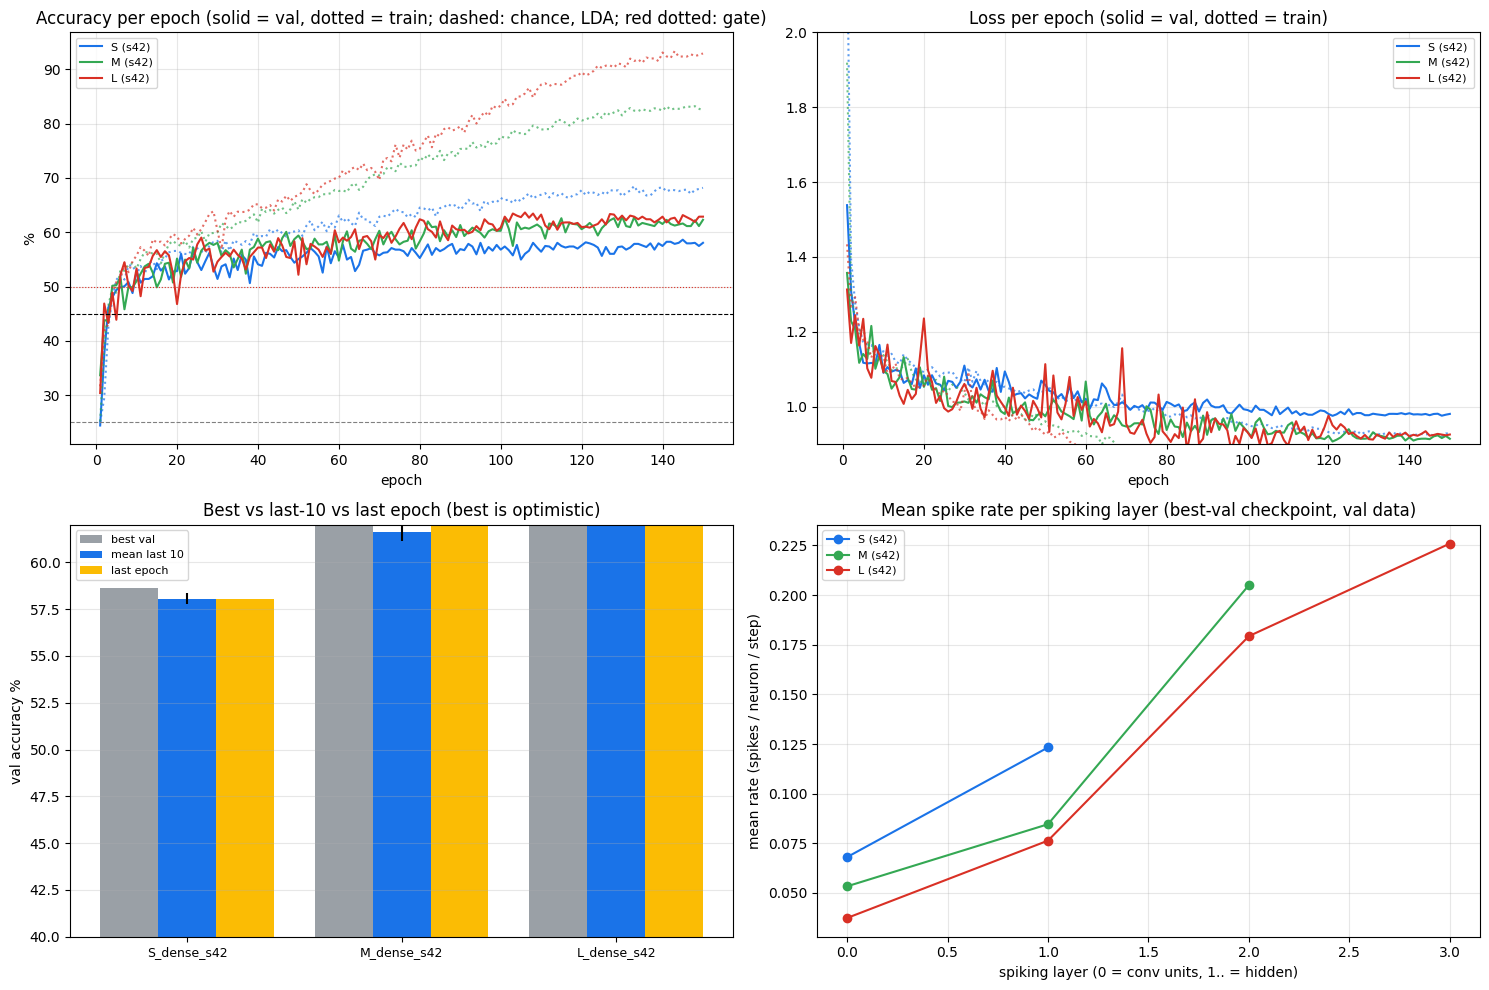


Files per variant on Drive:
  S_dense_s42    ✅ all 7 files | best ckpt 41 KB | trace 0.1 MB
  M_dense_s42    ✅ all 7 files | best ckpt 188 KB | trace 0.2 MB
  L_dense_s42    ✅ all 7 files | best ckpt 746 KB | trace 0.3 MB

Saved: /content/drive/MyDrive/Prototype_10/results/dense_summary.csv
       /content/drive/MyDrive/Prototype_10/figures/05_dense_training.png

Cell 5 complete.


In [ ]:
# ===================== CELL 5: DENSE training S / M / L (resumable) + summary table + plots =====================
import os, sys, json, time, importlib
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

# ---------- Prelude: works after a runtime restart (reloads everything from Drive); no-op if Cells 1-4 are in memory ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH, MASK = config['TRAIN'], config['FT'], config['ARCH'], config['MASK']
SEED, sp = config['SEED'], config['MASK']['SPARSITY']
CONFIG_PATH = os.path.join(PATHS['config'], 'config.json'); MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
device = "cuda" if torch.cuda.is_available() else "cpu"; assert device == "cuda", "use a GPU runtime"
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if 'train_loader' not in globals():
    from torch.utils.data import TensorDataset, DataLoader
    _X = np.load(os.path.join(PATHS['data'], 'X_ea.npy')); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
    _it = np.load(os.path.join(PATHS['data'], 'idx_tr.npy')); _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
    tx, vx = torch.from_numpy(_X[_it]), torch.from_numpy(_X[_iv]); ty, vy = torch.from_numpy(_y[_it]).long(), torch.from_numpy(_y[_iv]).long()
    train_loader = DataLoader(TensorDataset(tx, ty), batch_size=TRAIN['BATCH_SIZE'], shuffle=True, drop_last=TRAIN['DROP_LAST'])
    val_loader = DataLoader(TensorDataset(vx, vy), batch_size=TRAIN['VAL_BATCH_SIZE'], shuffle=False); del _X
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'train_variant' not in globals():
    from p10_model import *
    from p10_train import *
if 'trace_data' not in globals():
    _z = np.load(os.path.join(PATHS['spike_traces'], 'trace_windows.npz')); _pos = _z['positions_in_val']
    trace_data = dict(x=vx[_pos], pos=_pos, labels=vy.numpy()[_pos])
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}

# ---------- CONTROL PANEL ----------
TRAIN_SIZES   = ["S", "M", "L"]          # e.g. ["S"] to train only one size per session
SEEDS_RUN     = list(config['SEEDS'])    # from Cell 1 (currently [42]); add seeds there later, no other change needed
FORCE_RETRAIN = True                    # False = skip any variant whose 7 files are already on Drive (resume after a disconnect)
MODE = "dense"

st = config['STEPS']
print(f"Dense training | sizes {TRAIN_SIZES} | seeds {SEEDS_RUN} | FORCE_RETRAIN {FORCE_RETRAIN}")
print(f"Recipe: {TRAIN['EPOCHS']} epochs x {st['steps_per_epoch']} step(s) = {st['total_updates']['dense']} updates | BATCH_SIZE {TRAIN['BATCH_SIZE']} "
      f"(drop_last, {st['trades_dropped'] if 'trades_dropped' in st else st['trials_dropped_per_epoch']} trials dropped per epoch)")
print(f"Probe estimate per variant (150 ep): " + " | ".join(f"{k} {config['PROBE'][k]['dense_pre_min']:.1f} min" for k in TRAIN_SIZES))

# ---------- Train (each variant saves its 7 files immediately; a disconnect loses at most the running variant) ----------
results = {}
for seed in SEEDS_RUN:
    for size in TRAIN_SIZES:
        t0 = time.time()
        res, trained = train_variant(size, MODE, seed, ARCH, TRAIN, sp, (train_loader, val_loader), DIRS, device, trace_data,
                                     force=FORCE_RETRAIN, reg=register)
        results[(size, seed)] = res
        if trained: print(f"  [{res['key']}] done in {(time.time()-t0)/60:.1f} min\n")

# ---------- Summary table ----------
print("\n" + "=" * 136)
print(f"DENSE RESULTS (validation set; chance 25%, LDA reference {config['DATA']['lda_val_acc']*100:.1f}%, gate {TRAIN['GATE_ACCURACY']*100:.0f}% on best val)")
print("=" * 136)
print(f"{'variant':<14}{'params':>8}{'best val':>10}{'best ep':>8}{'last ep':>9}{'last-10 mean':>14}{'train acc':>11}{'gap':>7}{'silent/layer':>20}{'rate/layer':>26}{'min':>6}  gate")
rows = []
for (size, seed), r in results.items():
    h = r['history']; tr_last = float(np.mean(h['train_acc'][-TRAIN['LAST_K_EPOCHS']:])); gap = tr_last - r['last_k_mean']
    print(f"{r['key']:<14}{r['n_params']:>8,}{r['best_acc']*100:>9.2f}%{r['best_epoch']:>8}{r['last_epoch_acc']*100:>8.2f}%"
          f"{r['last_k_mean']*100:>9.2f}±{r['last_k_std']*100:<4.2f}{tr_last*100:>10.1f}%{gap*100:>6.1f}"
          f"{str(r['silent_per_layer']):>20}{str(np.round(r['rate_mean_per_layer'], 3).tolist()):>26}{r['train_time_s']/60:>6.1f}  {r['gate']}")
    rows.append(dict(variant=r['key'], size=size, mode=MODE, seed=seed, params=r['n_params'], retained_params=r['retained_params'],
                     best_val=r['best_acc'], best_epoch=r['best_epoch'], last_epoch_val=r['last_epoch_acc'],
                     last10_mean=r['last_k_mean'], last10_std=r['last_k_std'], train_acc_last10=tr_last,
                     silent=str(r['silent_per_layer']), neurons=str(r['neurons_per_layer']), rate_mean=str(np.round(r['rate_mean_per_layer'], 4).tolist()),
                     minutes=r['train_time_s']/60, gate=r['gate']))
df = pd.DataFrame(rows)
if len(SEEDS_RUN) > 1:
    g = df.groupby('size')[['best_val', 'last10_mean']].agg(['mean', 'std'])
    print("\nMEAN +/- STD ACROSS SEEDS:\n" + g.round(4).to_string())
csv_path = os.path.join(PATHS['results'], 'dense_summary.csv'); df.round(5).to_csv(csv_path, index=False)
register(csv_path, "dense S/M/L: best val, last-10 mean, rates, silent counts, time (one row per size x seed)")

# ---------- Checks and honest flags ----------
print("\nCHECKS")
for (size, seed), r in results.items():
    k = r['key']
    chk(r['gate'] == "PASS", f"{k}: gate PASS (best val {r['best_acc']*100:.2f}% >= {TRAIN['GATE_ACCURACY']*100:.0f}%)")
    chk(r['masked_layers_sparsity'] == 0.0 and r['pruned_weights'] == 0, f"{k}: dense = no pruned weights")
    chk(r['epochs'] == TRAIN['EPOCHS'], f"{k}: {r['epochs']} epochs recorded")
    soft(all(s == 0 for s in r['silent_per_layer']), f"{k}: silent neurons per layer {r['silent_per_layer']} of {r['neurons_per_layer']}")
    soft(all(0.002 < x < 0.5 for x in r['rate_mean_per_layer']), f"{k}: mean spike rate per layer {np.round(r['rate_mean_per_layer'], 3).tolist()} (no dead/saturated layer)")
    soft(r['best_acc'] - r['last_k_mean'] < 0.03, f"{k}: best-minus-last10 gap {100*(r['best_acc']-r['last_k_mean']):.2f} points (selection optimism)")
    soft(r['best_acc'] > config['DATA']['lda_val_acc'], f"{k}: better than the log-variance+LDA reference ({config['DATA']['lda_val_acc']*100:.1f}%)")
if ("S", SEED) in results:
    r = results[("S", SEED)]
    print(f"  ℹ️ context: Prototype8 S_MI (same architecture, same recipe) printed best val 54.68% (ep 112) and mean-last-5 53.83%; "
          f"here best {r['best_acc']*100:.2f}% (ep {r['best_epoch']}). Small differences can come from GPU/library versions.")
print("  ℹ️ Prototype8's M_MI/L_MI had ONE hidden layer, so they are not comparable with the new M/L (2 and 3 hidden layers).")

# ---------- Plots ----------
colors = {"S": "#1a73e8", "M": "#34a853", "L": "#d93025"}
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
for (size, seed), r in results.items():
    h = r['history']; ep = np.arange(1, len(h['val_acc']) + 1); c = colors[size]; lab = f"{size} (s{seed})"
    ax[0, 0].plot(ep, np.array(h['val_acc']) * 100, color=c, label=lab)
    ax[0, 0].plot(ep, np.array(h['train_acc']) * 100, color=c, ls=':', alpha=0.7)
    ax[0, 1].plot(ep, h['val_loss'], color=c, label=lab); ax[0, 1].plot(ep, h['train_loss'], color=c, ls=':', alpha=0.7)
ax[0, 0].axhline(25, color='gray', lw=0.8, ls='--'); ax[0, 0].axhline(config['DATA']['lda_val_acc'] * 100, color='k', lw=0.8, ls='--')
ax[0, 0].axhline(TRAIN['GATE_ACCURACY'] * 100, color='#d93025', lw=0.8, ls=':')
ax[0, 0].set_title("Accuracy per epoch (solid = val, dotted = train; dashed: chance, LDA; red dotted: gate)"); ax[0, 0].set_xlabel("epoch"); ax[0, 0].set_ylabel("%")
ax[0, 1].set_title("Loss per epoch (solid = val, dotted = train)"); ax[0, 1].set_xlabel("epoch"); ax[0, 1].set_ylim(0.9, 2.0)
for a in (ax[0, 0], ax[0, 1]): a.legend(fontsize=8); a.grid(alpha=0.3)
labels, x = [r['key'] for r in results.values()], np.arange(len(results)); w = 0.27
ax[1, 0].bar(x - w, [r['best_acc'] * 100 for r in results.values()], w, label="best val", color="#9aa0a6")
ax[1, 0].bar(x, [r['last_k_mean'] * 100 for r in results.values()], w, yerr=[r['last_k_std'] * 100 for r in results.values()], label=f"mean last {TRAIN['LAST_K_EPOCHS']}", color="#1a73e8")
ax[1, 0].bar(x + w, [r['last_epoch_acc'] * 100 for r in results.values()], w, label="last epoch", color="#fbbc04")
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(labels, fontsize=9); ax[1, 0].set_ylim(40, 62); ax[1, 0].set_ylabel("val accuracy %"); ax[1, 0].legend(fontsize=8)
ax[1, 0].set_title("Best vs last-10 vs last epoch (best is optimistic)"); ax[1, 0].grid(axis='y', alpha=0.3)
for (size, seed), r in results.items():
    ax[1, 1].plot(range(len(r['rate_mean_per_layer'])), r['rate_mean_per_layer'], marker='o', color=colors[size], label=f"{size} (s{seed})")
ax[1, 1].set_xlabel("spiking layer (0 = conv units, 1.. = hidden)"); ax[1, 1].set_ylabel("mean rate (spikes / neuron / step)")
ax[1, 1].set_title("Mean spike rate per spiking layer (best-val checkpoint, val data)"); ax[1, 1].legend(fontsize=8); ax[1, 1].grid(alpha=0.3)
plt.tight_layout()
fig_path = os.path.join(PATHS['figures'], '05_dense_training.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "dense S/M/L: accuracy/loss curves, best vs last-10, spike rate per layer")

# ---------- Manifest check ----------
print(f"\nFiles per variant on Drive:")
for (size, seed), r in results.items():
    ps = variant_paths(DIRS, r['key']); print(f"  {r['key']:<14} " + ("✅ all 7 files" if is_done(DIRS, r['key']) else "❌ incomplete") + f" | best ckpt {os.path.getsize(ps['best'])/1e3:.0f} KB | trace {os.path.getsize(ps['trace'])/1e6:.1f} MB")
print(f"\nSaved: {csv_path}\n       {fig_path}")
print("\nCell 5 complete.")

PRE-sparse training | sizes ['S', 'M', 'L'] | seeds [42] | FORCE_RETRAIN True
Same recipe as dense: 150 epochs x 32 step(s) = 4800 updates | mask: random fixed fan-in, 50% removed, created before training, enforced throughout
=== Training S_pre_s42 | params 5,752 | retained 4,344 | masked-layer sparsity 50.0% | 150 epochs x 32 step(s) ===
 Ep   1/150 | train 2.601/ 25.4% | val 1.539/24.98% | rate L1 0.037 L2 0.262 | 14s
 Ep  25/150 | train 1.100/ 56.3% | val 1.073/54.68% | rate L1 0.052 L2 0.178 | 348s
 Ep  50/150 | train 1.069/ 58.9% | val 1.025/56.51% | rate L1 0.057 L2 0.160 | 700s
 Ep  75/150 | train 1.028/ 61.2% | val 1.018/56.12% | rate L1 0.063 L2 0.153 | 1050s
 Ep 100/150 | train 0.999/ 63.0% | val 1.000/56.22% | rate L1 0.066 L2 0.158 | 1399s
 Ep 125/150 | train 0.980/ 64.0% | val 0.999/55.83% | rate L1 0.067 L2 0.158 | 1747s
 Ep 150/150 | train 0.970/ 64.7% | val 0.993/57.18% | rate L1 0.067 L2 0.157 | 2095s
 -> best val 58.34% (ep 121) | last-epoch 57.18% | mean last 10 56.8

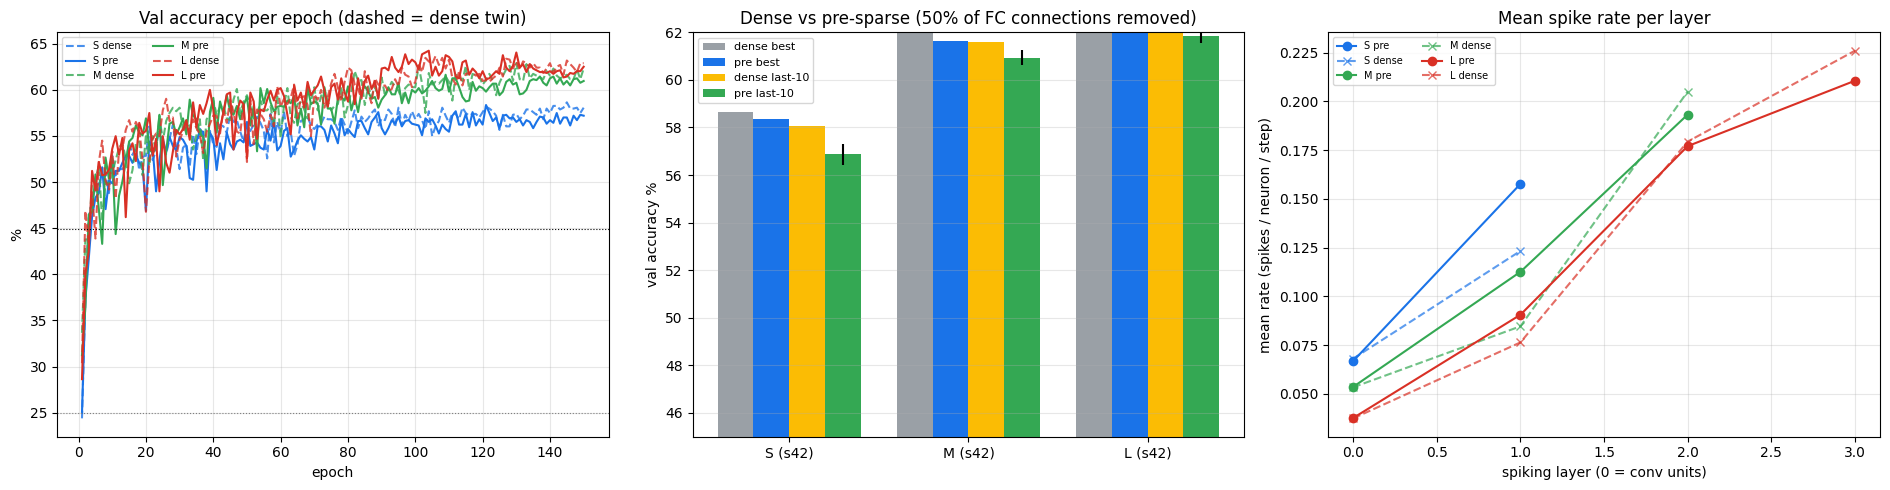


Files per variant on Drive:
  S_pre_s42     ✅ all 7 files
  M_pre_s42     ✅ all 7 files
  L_pre_s42     ✅ all 7 files

Saved: /content/drive/MyDrive/Prototype_10/results/pre_summary.csv
       /content/drive/MyDrive/Prototype_10/figures/06_pre_sparse_training.png

Cell 6 complete.


In [ ]:
# ===================== CELL 6: PRE-SPARSE training S / M / L (resumable) + comparison with the dense twins =====================
import os, sys, json, time
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

# ---------- Prelude (same as Cell 5: works after a runtime restart) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH, MASK = config['TRAIN'], config['FT'], config['ARCH'], config['MASK']
SEED, sp = config['SEED'], config['MASK']['SPARSITY']
MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
device = "cuda" if torch.cuda.is_available() else "cpu"; assert device == "cuda", "use a GPU runtime"
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if 'train_loader' not in globals():
    from torch.utils.data import TensorDataset, DataLoader
    _X = np.load(os.path.join(PATHS['data'], 'X_ea.npy')); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
    _it = np.load(os.path.join(PATHS['data'], 'idx_tr.npy')); _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
    tx, vx = torch.from_numpy(_X[_it]), torch.from_numpy(_X[_iv]); ty, vy = torch.from_numpy(_y[_it]).long(), torch.from_numpy(_y[_iv]).long()
    train_loader = DataLoader(TensorDataset(tx, ty), batch_size=TRAIN['BATCH_SIZE'], shuffle=True, drop_last=TRAIN['DROP_LAST'])
    val_loader = DataLoader(TensorDataset(vx, vy), batch_size=TRAIN['VAL_BATCH_SIZE'], shuffle=False); del _X
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'train_variant' not in globals():
    from p10_model import *
    from p10_train import *
if 'trace_data' not in globals():
    _z = np.load(os.path.join(PATHS['spike_traces'], 'trace_windows.npz')); _pos = _z['positions_in_val']
    trace_data = dict(x=vx[_pos], pos=_pos, labels=vy.numpy()[_pos])
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}

# ---------- CONTROL PANEL ----------
TRAIN_SIZES   = ["S", "M", "L"]
SEEDS_RUN     = list(config['SEEDS'])
FORCE_RETRAIN = True
MODE = "pre"

st = config['STEPS']
print(f"PRE-sparse training | sizes {TRAIN_SIZES} | seeds {SEEDS_RUN} | FORCE_RETRAIN {FORCE_RETRAIN}")
print(f"Same recipe as dense: {TRAIN['EPOCHS']} epochs x {st['steps_per_epoch']} step(s) = {st['total_updates']['pre']} updates | "
      f"mask: random fixed fan-in, {sp:.0%} removed, created before training, enforced throughout")

# ---------- Train ----------
results, dense = {}, {}
for seed in SEEDS_RUN:
    for size in TRAIN_SIZES:
        dk = variant_key(size, "dense", seed)
        assert is_done(DIRS, dk), f"{dk} not found: run Cell 5 first"
        dense[(size, seed)] = json.load(open(variant_paths(DIRS, dk)['results']))
        t0 = time.time()
        res, trained = train_variant(size, MODE, seed, ARCH, TRAIN, sp, (train_loader, val_loader), DIRS, device, trace_data,
                                     force=FORCE_RETRAIN, reg=register)
        results[(size, seed)] = res
        if trained: print(f"  [{res['key']}] done in {(time.time()-t0)/60:.1f} min\n")

# ---------- Table: pre-sparse vs its dense twin ----------
print("\n" + "=" * 150)
print(f"PRE-SPARSE vs DENSE (validation set; chance 25%, LDA {config['DATA']['lda_val_acc']*100:.1f}%)")
print("=" * 150)
print(f"{'variant':<13}{'retained':>9}{'sp.masked':>10}{'sp.whole':>9}{'best val':>9}{'(dense)':>9}{'last-10 mean':>14}{'(dense)':>9}{'Δbest':>7}{'Δlast10':>8}{'silent/layer':>18}{'rate/layer':>26}{'min':>5}")
rows = []
for (size, seed), r in results.items():
    d = dense[(size, seed)]
    print(f"{r['key']:<13}{r['retained_params']:>9,}{r['masked_layers_sparsity']*100:>9.1f}%{r['whole_model_sparsity']*100:>8.1f}%"
          f"{r['best_acc']*100:>8.2f}%{d['best_acc']*100:>8.2f}%{r['last_k_mean']*100:>9.2f}±{r['last_k_std']*100:<4.2f}{d['last_k_mean']*100:>8.2f}%"
          f"{(r['best_acc']-d['best_acc'])*100:>+7.2f}{(r['last_k_mean']-d['last_k_mean'])*100:>+8.2f}"
          f"{str(r['silent_per_layer']):>18}{str(np.round(r['rate_mean_per_layer'], 3).tolist()):>26}{r['train_time_s']/60:>5.1f}")
    rows.append(dict(variant=r['key'], size=size, mode=MODE, seed=seed, params=r['n_params'], retained_params=r['retained_params'],
                     fc_connections=r['fc_connections'], masked_sparsity=r['masked_layers_sparsity'], whole_sparsity=r['whole_model_sparsity'],
                     best_val=r['best_acc'], best_epoch=r['best_epoch'], last_epoch_val=r['last_epoch_acc'],
                     last10_mean=r['last_k_mean'], last10_std=r['last_k_std'],
                     dense_best_val=d['best_acc'], dense_last10_mean=d['last_k_mean'],
                     delta_best=r['best_acc']-d['best_acc'], delta_last10=r['last_k_mean']-d['last_k_mean'],
                     silent=str(r['silent_per_layer']), neurons=str(r['neurons_per_layer']),
                     rate_mean=str(np.round(r['rate_mean_per_layer'], 4).tolist()), minutes=r['train_time_s']/60, gate=r['gate']))
df = pd.DataFrame(rows)
csv_path = os.path.join(PATHS['results'], 'pre_summary.csv'); df.round(5).to_csv(csv_path, index=False)
register(csv_path, "pre-sparse S/M/L: best val, last-10 mean, sparsity, rates, silent counts, delta vs dense twin")

# ---------- Checks and honest flags ----------
print("\nCHECKS")
for (size, seed), r in results.items():
    k = r['key']; d = dense[(size, seed)]
    chk(r['gate'] == "PASS", f"{k}: gate PASS (best val {r['best_acc']*100:.2f}%)")
    chk(abs(r['masked_layers_sparsity'] - sp) < 1e-9, f"{k}: masked-layer sparsity exactly {sp:.0%}; whole-model sparsity {r['whole_model_sparsity']*100:.1f}%")
    for m_ in r['mask_report']:
        chk(m_['k_min'] == m_['k_max'] and m_['eff_nonzero'] == m_['retained'] == m_['raw_nonzero'],
            f"{k} {m_['layer']} {m_['in_f']}->{m_['out_f']}: every neuron keeps {m_['k_min']} inputs; effective = raw nonzero = mask.sum() = {m_['retained']:,}")
    chk(r['epochs'] == TRAIN['EPOCHS'] and r['n_params'] == d['n_params'], f"{k}: {r['epochs']} epochs, same parameter-tensor sizes as dense ({r['n_params']:,})")
    soft(all(s == 0 for s in r['silent_per_layer']), f"{k}: silent neurons per layer {r['silent_per_layer']} of {r['neurons_per_layer']} (dense twin: {d['silent_per_layer']})")
    soft(all(0.002 < x < 0.5 for x in r['rate_mean_per_layer']), f"{k}: mean rate per layer {np.round(r['rate_mean_per_layer'], 3).tolist()}")
    soft(r['best_acc'] - r['last_k_mean'] < 0.03, f"{k}: best-minus-last10 gap {100*(r['best_acc']-r['last_k_mean']):.2f} points")
print("  ℹ️ one seed: differences of ~1 point or less are within the last-10 std (0.3-0.5) and should not be read as a pre-vs-dense ranking yet.")
print("  ℹ️ pre-sparse starts from the SAME init as its dense twin (verified in Cell 3); only the mask differs.")

# ---------- Plots ----------
colors = {"S": "#1a73e8", "M": "#34a853", "L": "#d93025"}
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for (size, seed), r in results.items():
    d = dense[(size, seed)]; ep = np.arange(1, TRAIN['EPOCHS'] + 1)
    ax[0].plot(ep, np.array(d['history']['val_acc']) * 100, color=colors[size], ls='--', alpha=0.8, label=f"{size} dense")
    ax[0].plot(ep, np.array(r['history']['val_acc']) * 100, color=colors[size], label=f"{size} pre")
ax[0].axhline(25, color='gray', lw=0.8, ls=':'); ax[0].axhline(config['DATA']['lda_val_acc'] * 100, color='k', lw=0.8, ls=':')
ax[0].set_title("Val accuracy per epoch (dashed = dense twin)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("%"); ax[0].legend(fontsize=7, ncol=2); ax[0].grid(alpha=0.3)
x = np.arange(len(results)); w = 0.2; keys = list(results)
ax[1].bar(x - 1.5*w, [dense[k]['best_acc']*100 for k in keys], w, label="dense best", color="#9aa0a6")
ax[1].bar(x - 0.5*w, [results[k]['best_acc']*100 for k in keys], w, label="pre best", color="#1a73e8")
ax[1].bar(x + 0.5*w, [dense[k]['last_k_mean']*100 for k in keys], w, label="dense last-10", color="#fbbc04")
ax[1].bar(x + 1.5*w, [results[k]['last_k_mean']*100 for k in keys], w, yerr=[results[k]['last_k_std']*100 for k in keys], label="pre last-10", color="#34a853")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{k[0]} (s{k[1]})" for k in keys]); ax[1].set_ylim(45, 62); ax[1].set_ylabel("val accuracy %")
ax[1].set_title("Dense vs pre-sparse (50% of FC connections removed)"); ax[1].legend(fontsize=8); ax[1].grid(axis='y', alpha=0.3)
for (size, seed), r in results.items():
    ax[2].plot(range(len(r['rate_mean_per_layer'])), r['rate_mean_per_layer'], marker='o', color=colors[size], label=f"{size} pre")
    ax[2].plot(range(len(dense[(size, seed)]['rate_mean_per_layer'])), dense[(size, seed)]['rate_mean_per_layer'], marker='x', ls='--', color=colors[size], alpha=0.7, label=f"{size} dense")
ax[2].set_xlabel("spiking layer (0 = conv units)"); ax[2].set_ylabel("mean rate (spikes / neuron / step)"); ax[2].set_title("Mean spike rate per layer"); ax[2].legend(fontsize=7, ncol=2); ax[2].grid(alpha=0.3)
plt.tight_layout()
fig_path = os.path.join(PATHS['figures'], '06_pre_sparse_training.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "pre-sparse vs dense: accuracy curves, best/last-10 bars, spike rate per layer")

print("\nFiles per variant on Drive:")
for (size, seed), r in results.items():
    print(f"  {r['key']:<13} " + ("✅ all 7 files" if is_done(DIRS, r['key']) else "❌ incomplete"))
print(f"\nSaved: {csv_path}\n       {fig_path}")
print("\nCell 6 complete.")

In [ ]:
8

8

Post-sparse code written and imported from /content/drive/MyDrive/Prototype_10/code/p10_post.py

[1] FINISHED CODE FILES NOT MODIFIED (md5 of the files on Drive vs the md5 stored in config.json)
  ✅ p10_model.py: cecb569ec3c9bf12c9c61ac7a41764eb == config cecb569ec3c9bf12c9c61ac7a41764eb
  ✅ p10_train.py: f1eec8910dfc4f693ebf5ac441837284 == config f1eec8910dfc4f693ebf5ac441837284

[2] PATCH OF STALE CONFIG ITEMS
  LIMITATIONS[0] OLD: BATCH_SIZE 4000 with drop_last on ~4147 training trials = 1 optimizer step per epoch: 150 updates for dense/pre, 150+50 for post; kept exactly as Prototype8 (may be re-tested with a smaller batch after dense results)
  LIMITATIONS[0] NEW: BATCH_SIZE 128 with drop_last on 4147 training trials = 32 optimizer steps per epoch (51 trials dropped per epoch): 4800 updates for dense and pre, 150+50 epochs = 6400 updates for post
  probe: epoch_s in Cell 4 assumed 1 step/epoch; corrected = 32 x step_s + val pass (compared with the measured dense times):
  ✅ S: corr

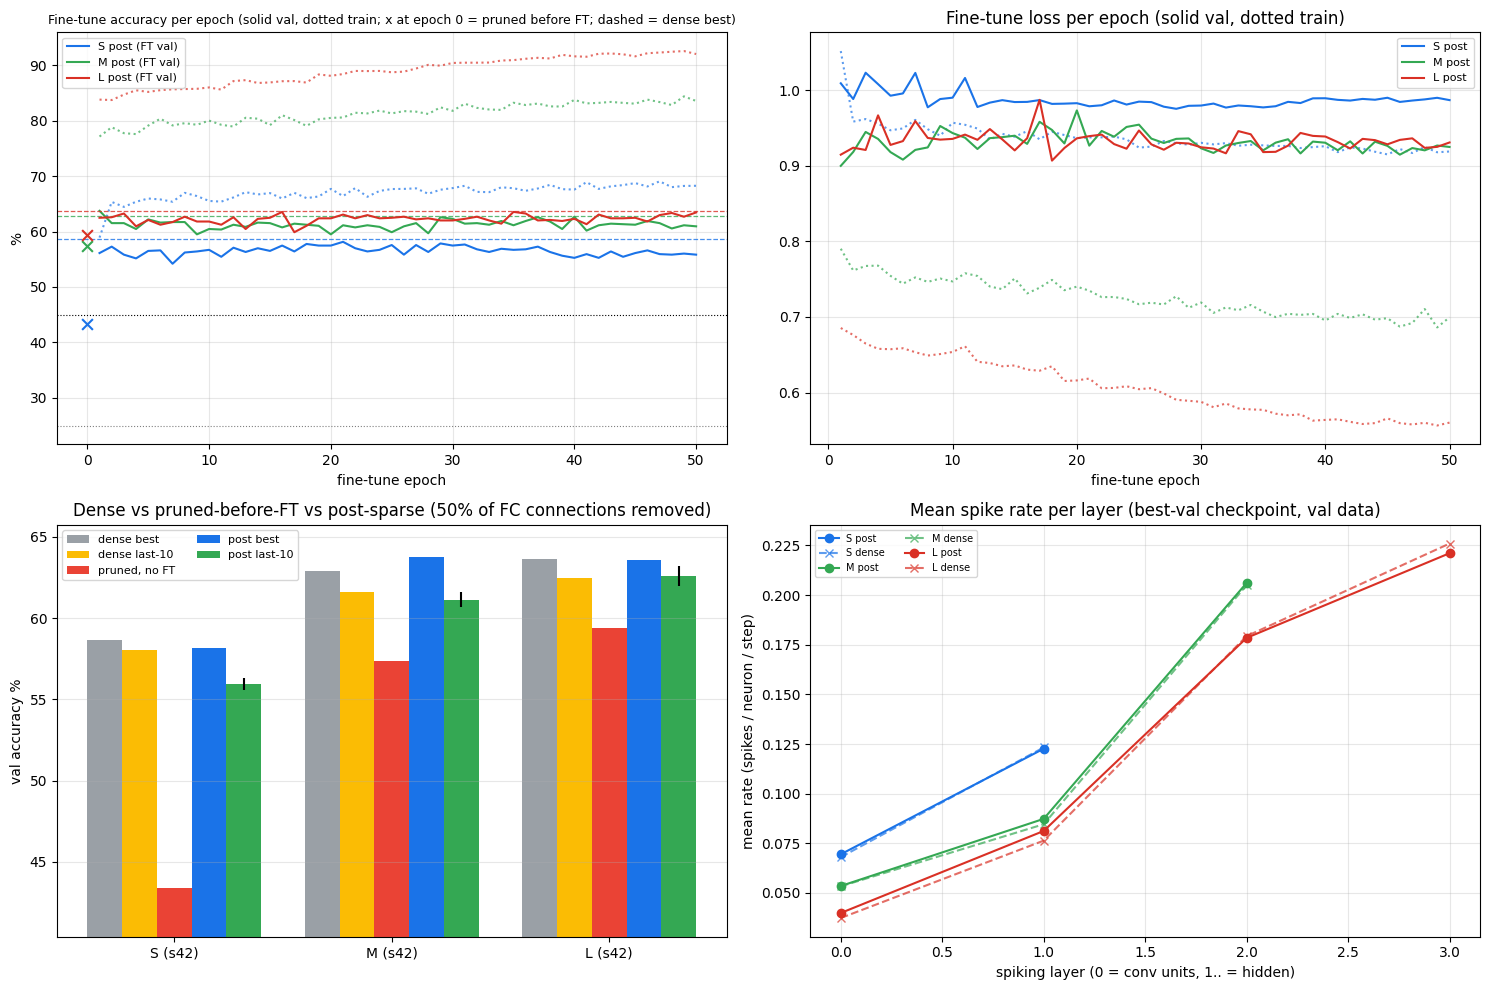


Files per variant on Drive:
  S_post_s42    ✅ all 7 files | in manifest ✅ | best ckpt 42 KB | trace 0.1 MB
  M_post_s42    ✅ all 7 files | in manifest ✅ | best ckpt 189 KB | trace 0.2 MB
  L_post_s42    ✅ all 7 files | in manifest ✅ | best ckpt 748 KB | trace 0.3 MB

Saved: /content/drive/MyDrive/Prototype_10/code/p10_post.py
       /content/drive/MyDrive/Prototype_10/results/post_summary.csv
       /content/drive/MyDrive/Prototype_10/figures/07_post_sparse_training.png
       config + probe json patched

Cell 7 complete.


In [ ]:
# ===================== CELL 7: POST-SPARSE S / M / L (prune the trained dense best-val checkpoint, frozen-mask fine-tune; resumable) =====================
import os, sys, json, time, importlib, hashlib
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

# ---------- Prelude (same pattern as Cells 5/6: works after a runtime restart; no-op if Cells 1-6 are in memory) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH, MASK = config['TRAIN'], config['FT'], config['ARCH'], config['MASK']
SEED, sp = config['SEED'], config['MASK']['SPARSITY']
CONFIG_PATH = os.path.join(PATHS['config'], 'config.json'); MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
device = "cuda" if torch.cuda.is_available() else "cpu"; assert device == "cuda", "use a GPU runtime"
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if 'train_loader' not in globals():
    from torch.utils.data import TensorDataset, DataLoader
    _X = np.load(os.path.join(PATHS['data'], 'X_ea.npy')); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
    _it = np.load(os.path.join(PATHS['data'], 'idx_tr.npy')); _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
    tx, vx = torch.from_numpy(_X[_it]), torch.from_numpy(_X[_iv]); ty, vy = torch.from_numpy(_y[_it]).long(), torch.from_numpy(_y[_iv]).long()
    train_loader = DataLoader(TensorDataset(tx, ty), batch_size=TRAIN['BATCH_SIZE'], shuffle=True, drop_last=TRAIN['DROP_LAST'])
    val_loader = DataLoader(TensorDataset(vx, vy), batch_size=TRAIN['VAL_BATCH_SIZE'], shuffle=False); del _X
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'train_variant' not in globals():
    from p10_model import *
    from p10_train import *
if 'trace_data' not in globals():
    _z = np.load(os.path.join(PATHS['spike_traces'], 'trace_windows.npz')); _pos = _z['positions_in_val']
    trace_data = dict(x=vx[_pos], pos=_pos, labels=vy.numpy()[_pos])
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}

# ---------- 1) NEW code file code/p10_post.py (p10_model.py and p10_train.py are NOT touched) ----------
POST_SRC = r'''# p10_post.py -- Prototype 10: post-sparse = prune the trained DENSE best-val checkpoint, then frozen-mask fine-tune (written by Cell 7).
# Needs p10_model.py and p10_train.py on sys.path. Does not modify them.
import json, time
import numpy as np
import torch
from p10_model import FastSNN, prune_topk_, sparsity_summary, fc_connections
from p10_train import fit, eval_fast, load_variant, save_variant, variant_key, variant_paths, is_done

POST_SEED_OFFSET = 2000      # fine-tune RNG seed (shuffle / augmentation) = POST_SEED_OFFSET + model seed

# (from Prototype8 Cell 8: topk per output neuron; here via p10_model.prune_topk_) prune in place and VERIFY against a copy of the dense weights
def prune_and_verify(model, keep_frac):
    W0 = [fc.weight.detach().clone() for fc in model.fcs]
    prune_topk_(model, keep_frac)
    rows = []
    for i, fc in enumerate(model.fcs):
        m = fc.mask.bool(); A = W0[i].abs(); W = fc.weight.detach()
        k = max(1, int(round(keep_frac * fc.in_features)))
        kept_min = A.masked_fill(~m, float("inf")).min(1).values
        pruned_max = A.masked_fill(m, float("-inf")).max(1).values
        r = dict(layer=f"fc{i+1}", in_f=int(fc.in_features), out_f=int(fc.out_features), k=k,
                 k_min=int(m.sum(1).min()), k_max=int(m.sum(1).max()), retained=int(m.sum()),
                 magnitude_ok=bool((kept_min >= pruned_max).all()),
                 zero_outside=bool((W[~m] == 0).all()),
                 kept_unchanged=bool(torch.equal(W[m], W0[i][m])),
                 kept_nonzero=bool(int((W[m] != 0).sum()) == int(m.sum())))
        assert r["k_min"] == r["k_max"] == k, f"{r['layer']}: rows keep {r['k_min']}..{r['k_max']} inputs, expected exactly {k}"
        assert r["magnitude_ok"], f"{r['layer']}: a kept weight is smaller than a pruned one in some row"
        assert r["zero_outside"] and r["kept_unchanged"] and r["kept_nonzero"], f"{r['layer']}: raw weights not (dense weights x mask)"
        print(f"  ✅ {r['layer']} {r['in_f']}->{r['out_f']}: every row keeps exactly k={k}; smallest kept |W| >= largest pruned |W| in every row; "
              f"raw weights = dense weights x mask ({r['retained']:,} kept, all nonzero)")
        rows.append(r)
    return rows

def _tolist(x):
    return [float(v) for v in x]

# one post-sparse variant. dense twin = the BEST-val checkpoint of {size}_dense_s{seed} (Prototype8 Cell 8 pruned its best-val checkpoint too).
def train_post_variant(size, seed, arch, hp, ft, keep_frac, loaders, dirs, device, trace_data, dense_updates,
                       expect=None, force=False, reg=None, log_every=10):
    key, dkey = variant_key(size, "post", seed), variant_key(size, "dense", seed)
    P = variant_paths(dirs, key)
    if is_done(dirs, key) and not force:
        res = json.load(open(P["results"]))
        print(f"[{key}] already done: loaded results (FT best {res['best_acc']*100:.2f}% ep {res['best_epoch']}, last-10 {res['last_k_mean']*100:.2f}%)")
        return res, False
    assert is_done(dirs, dkey), f"{dkey} not found: run Cell 5 first"
    dres = json.load(open(variant_paths(dirs, dkey)["results"]))
    assert dres["total_updates"] == dense_updates, f"{dkey}: total_updates {dres['total_updates']} != {dense_updates} (stale dense variant)"
    train_loader, val_loader = loaders
    a = arch[size]; cfg = dict(size=size, mode="post", fpc=a["fpc"], hidden=a["hidden"])
    model, ck = load_variant(variant_paths(dirs, dkey)["best"], device)                  # eval mode; dense files are only READ
    assert ck["model_cfg"]["size"] == size and ck["model_cfg"]["mode"] == "dense" and ck["kind"] == "best"
    assert all(int(fc.mask.sum()) == fc.mask.numel() for fc in model.fcs), "dense twin must have all-ones masks"
    print(f"=== Post-sparse {key} | pruning {dkey} best-val checkpoint (dense epoch {dres['best_epoch']}) | keep {keep_frac:.0%} per output neuron ===")
    r0 = eval_fast(model, val_loader, device)
    assert abs(r0[1] - dres["best_acc"]) < 1e-9, f"loaded dense checkpoint gives {r0[1]} but results say {dres['best_acc']}"
    print(f"  ✅ dense checkpoint reloaded: val acc {r0[1]*100:.2f}% == recorded best {dres['best_acc']*100:.2f}%")
    # --- prune + verify ---
    mrows = prune_and_verify(model, keep_frac)
    sps = sparsity_summary(model); fcc = fc_connections(model)
    if expect is not None:
        assert sps["retained_params"] == expect[0] and fcc == expect[1], f"retained {sps['retained_params']} / connections {fcc} != expected {expect}"
        print(f"  ✅ retained params {sps['retained_params']:,} and FC connections {fcc:,} equal the pre-sparse values")
    # --- evaluate right after pruning (before fine-tuning) ---
    vlb, vab, _, _, _, rb = eval_fast(model, val_loader, device)
    before = dict(acc=float(vab), loss=float(vlb), rate_mean_per_layer=[float(rb[i + 1].mean()) for i in range(len(rb))],
                  silent_per_layer=[int((rb[i + 1] == 0).sum()) for i in range(len(rb))])
    print(f"  pruned, BEFORE fine-tune: val acc {vab*100:.2f}% (dense best {dres['best_acc']*100:.2f}%, drop {(vab-dres['best_acc'])*100:+.2f}) | silent {before['silent_per_layer']}")
    # --- frozen-mask fine-tune: same mask-in-forward mechanism, fresh AdamW (as Prototype8 Cell 8), FT recipe from config ---
    mask_ref = [fc.mask.detach().cpu().clone() for fc in model.fcs]
    torch.manual_seed(POST_SEED_OFFSET + seed)
    hist, best, last, secs, ft_updates = fit(model, train_loader, val_loader, ft["FT_EPOCHS"], ft["FT_LR"], ft["FT_WARM"], ft["FT_WEIGHT_DECAY"], hp, device, log_every)
    for fc, ref in zip(model.fcs, mask_ref):
        assert torch.equal(fc.mask.detach().cpu(), ref), "mask changed during fine-tuning"
        assert int(((1 - fc.mask) * fc.weight.detach() != 0).sum()) == 0, "nonzero raw weight outside the mask after fine-tuning"
    print("  ✅ mask unchanged after fine-tuning; raw weights outside the mask are exactly 0")
    total_updates = int(dense_updates + ft_updates)
    K = hp["LAST_K_EPOCHS"]; tail = hist["val_acc"][-K:]
    print(f" -> FT best val {best['acc']*100:.2f}% (FT ep {best['epoch']}) | last-epoch {hist['val_acc'][-1]*100:.2f}% | "
          f"mean last {len(tail)} FT epochs {np.mean(tail)*100:.2f}% +/- {np.std(tail)*100:.2f} | {secs/60:.1f} min")
    extra = dict(dense_key=dkey, pruned_from=f"{dkey} best-val checkpoint (dense epoch {dres['best_epoch']})",
                 dense=dict(best_acc=float(dres["best_acc"]), best_epoch=int(dres["best_epoch"]), last_epoch_acc=float(dres["last_epoch_acc"]),
                            last_k_mean=float(dres["last_k_mean"]), last_k_std=float(dres["last_k_std"]), train_time_s=float(dres["train_time_s"]),
                            total_updates=int(dres["total_updates"]), rate_mean_per_layer=_tolist(dres["rate_mean_per_layer"]),
                            silent_per_layer=[int(v) for v in dres["silent_per_layer"]]),
                 before_ft=before, ft=dict(ft), ft_updates=int(ft_updates), dense_updates=int(dense_updates), total_updates=total_updates,
                 ft_seed=int(POST_SEED_OFFSET + seed), mask_verification=mrows,
                 note="history / best_acc / best_epoch / last_k_* / train_time_s refer to the FINE-TUNE epochs only; total_updates = dense + fine-tune")
    res = save_variant(dirs, key, cfg, seed, hp, hist, best, last, secs, total_updates, val_loader, trace_data, device,
                       mask_ref=mask_ref, extra=extra, reg=reg)
    del model; torch.cuda.empty_cache()
    return res, True
'''
POST_PATH = os.path.join(PATHS['code'], 'p10_post.py')
with open(POST_PATH, 'w') as f: f.write(POST_SRC)
register(POST_PATH, "post-sparse: prune_and_verify (top-|W| per row from the dense best-val checkpoint) + train_post_variant (frozen-mask fine-tune, 7-file layout)")
import p10_post; importlib.reload(p10_post)
from p10_post import prune_and_verify, train_post_variant, POST_SEED_OFFSET
print(f"Post-sparse code written and imported from {POST_PATH}")
print("\n[1] FINISHED CODE FILES NOT MODIFIED (md5 of the files on Drive vs the md5 stored in config.json)")
_cfg = json.load(open(CONFIG_PATH))
for nm, k_ in (("p10_model.py", "MODEL_CODE"), ("p10_train.py", "TRAIN_CODE")):
    md5 = hashlib.md5(open(os.path.join(PATHS['code'], nm), 'rb').read()).hexdigest()
    soft(md5 == _cfg[k_]['md5'], f"{nm}: {md5} {'==' if md5 == _cfg[k_]['md5'] else '!='} config {_cfg[k_]['md5']}")

# ---------- 2) Patch stale config items (printing what changed) ----------
print("\n[2] PATCH OF STALE CONFIG ITEMS")
st = _cfg['STEPS']; tu = st['total_updates']
new_lim0 = (f"BATCH_SIZE {_cfg['TRAIN']['BATCH_SIZE']} with drop_last on {st['n_train']} training trials = {st['steps_per_epoch']} optimizer steps per epoch "
            f"({st['trials_dropped_per_epoch']} trials dropped per epoch): {tu['dense']} updates for dense and pre, "
            f"{_cfg['TRAIN']['EPOCHS']}+{_cfg['FT']['FT_EPOCHS']} epochs = {tu['post']} updates for post")
i0 = next((i for i, s in enumerate(_cfg['LIMITATIONS']) if s.startswith("BATCH_SIZE 4000")), None)
if i0 is not None:
    print(f"  LIMITATIONS[{i0}] OLD: {_cfg['LIMITATIONS'][i0]}\n  LIMITATIONS[{i0}] NEW: {new_lim0}")
    _cfg['LIMITATIONS'][i0] = new_lim0
else:
    print(f"  LIMITATIONS[0] already patched: {_cfg['LIMITATIONS'][0][:110]}...")
probe_path = os.path.join(PATHS['results'], 'probe_memory_time.json')
pj = json.load(open(probe_path)); steps_pe = st['steps_per_epoch']
corr = {}
print(f"  probe: epoch_s in Cell 4 assumed 1 step/epoch; corrected = {steps_pe} x step_s + val pass (compared with the measured dense times):")
for size_, p_ in _cfg['PROBE'].items():
    ep_s = steps_pe * p_['step_s'] + p_['eval_s']
    corr[size_] = dict(epoch_s=ep_s, dense_pre_min=TRAIN['EPOCHS'] * ep_s / 60, ft_min=FT['FT_EPOCHS'] * ep_s / 60)
    dpath = variant_paths(DIRS, variant_key(size_, "dense", SEED))['results']
    if os.path.exists(dpath):
        meas = json.load(open(dpath))['train_time_s'] / 60
        soft(abs(corr[size_]['dense_pre_min'] / meas - 1) < 0.05,
             f"{size_}: corrected 150-epoch estimate {corr[size_]['dense_pre_min']:.1f} min vs measured dense {meas:.1f} min (old Cell 4 table said {p_['dense_pre_min']:.1f})")
note = ("STALE: epoch_s, dense_pre_min, ft_min and the '~47 min' projection assume 1 optimizer step per epoch (batch 4000). "
        f"With batch {TRAIN['BATCH_SIZE']} there are {steps_pe} steps per epoch. The per-step and val-pass times are still valid; see 'corrected'. Real times: results_*.json train_time_s.")
pj['STALE_NOTE'] = note; pj['corrected'] = corr
json.dump(pj, open(probe_path, 'w'), indent=2)
register(probe_path, "memory/time probe (per-step and val-pass times valid; epoch/150-ep/FT/projection columns STALE, corrected values + STALE_NOTE inside)")
_cfg['PROBE_STALE_NOTE'] = note
_cfg['POST_CODE'] = dict(path=POST_PATH, md5=hashlib.md5(POST_SRC.encode()).hexdigest(), post_seed_offset=POST_SEED_OFFSET,
                         rule="prune the dense BEST-val checkpoint (top-|W| per output neuron), eval before FT, frozen-mask fine-tune with the FT recipe, best-val over FT epochs, last-10 = last 10 FT epochs")
with open(CONFIG_PATH, 'w') as f: json.dump(_cfg, f, indent=2)
register(CONFIG_PATH, "central config: seeds, hyperparameters, architectures, mask rules, hardware constants, split info, versions, limitations (LIMITATIONS[0] and PROBE note patched in Cell 7)")
config = _cfg

# ---------- CONTROL PANEL ----------
TRAIN_SIZES   = ["S", "M", "L"]
SEEDS_RUN     = list(config['SEEDS'])
FORCE_RETRAIN = False          # True = redo the POST variant even if its 7 files exist (the dense files are never touched)
MODE = "post"
EXPECT = {"S": (4344, 1664), "M": (15596, 9984), "L": (54740, 43264)}     # (retained params, FC connections): printed by Cell 6 / architecture table, same as pre
keep_frac = 1.0 - sp
dense_upd, post_upd = st['total_updates']['dense'], st['total_updates']['post']
print(f"\nPOST-sparse | sizes {TRAIN_SIZES} | seeds {SEEDS_RUN} | FORCE_RETRAIN {FORCE_RETRAIN}")
print(f"Recipe: prune dense best-val checkpoint (keep {keep_frac:.0%} per output neuron) -> {FT['FT_EPOCHS']} FT epochs, lr {FT['FT_LR']}, warm {FT['FT_WARM']}, wd {FT['FT_WEIGHT_DECAY']} "
      f"| updates {TRAIN['EPOCHS']}+{FT['FT_EPOCHS']} epochs x {st['steps_per_epoch']} = {post_upd} (pre-sparse gets {tu['pre']})")

# ---------- 3) Dense twins: existence + stale guard ----------
print("\n[3] DENSE TWINS (stale guard: valid only if total_updates == %d)" % dense_upd)
for seed in SEEDS_RUN:
    for size in TRAIN_SIZES:
        dk = variant_key(size, "dense", seed)
        chk(is_done(DIRS, dk), f"{dk}: all 7 files present")
        d = json.load(open(variant_paths(DIRS, dk)['results']))
        chk(d['total_updates'] == dense_upd and d['epochs'] == TRAIN['EPOCHS'],
            f"{dk}: total_updates field = {d['total_updates']} (need {dense_upd}), epochs {d['epochs']}; best {d['best_acc']*100:.2f}% (ep {d['best_epoch']}), dense train {d['train_time_s']/60:.1f} min")
        print(f"      estimated fine-tune time ({FT['FT_EPOCHS']}/{TRAIN['EPOCHS']} of the dense time, an estimate): {d['train_time_s']/60*FT['FT_EPOCHS']/TRAIN['EPOCHS']:.1f} min")

# ---------- 4) Post-sparse variants ----------
results, dense = {}, {}
for seed in SEEDS_RUN:
    for size in TRAIN_SIZES:
        dense[(size, seed)] = json.load(open(variant_paths(DIRS, variant_key(size, "dense", seed))['results']))
        t0 = time.time()
        res, trained = train_post_variant(size, seed, ARCH, TRAIN, FT, keep_frac, (train_loader, val_loader), DIRS, device, trace_data,
                                          dense_upd, expect=EXPECT[size], force=FORCE_RETRAIN, reg=register)
        results[(size, seed)] = res
        if trained: print(f"  [{res['key']}] done in {(time.time()-t0)/60:.1f} min\n")

# ---------- 5) Tables ----------
print("\n" + "=" * 158)
print(f"POST-SPARSE vs DENSE: ACCURACY (validation set; chance 25%, LDA {config['DATA']['lda_val_acc']*100:.1f}%). Pruned model = the dense best-val checkpoint. "
      f"post best / last-10 are over the {FT['FT_EPOCHS']} FT epochs")
print("=" * 158)
print(f"{'variant':<13}{'dense best':>11}{'dense last10':>13}{'pruned (no FT)':>15}{'Δprune':>8}{'post best (ep)':>16}{'post last-10':>15}{'post last ep':>13}{'Δbest':>8}{'Δlast10':>9}  gate")
rows = []
for (size, seed), r in results.items():
    d, e = dense[(size, seed)], r['extra']; b = e['before_ft']
    print(f"{r['key']:<13}{d['best_acc']*100:>10.2f}%{d['last_k_mean']*100:>12.2f}%{b['acc']*100:>14.2f}%{(b['acc']-d['best_acc'])*100:>+8.2f}"
          f"{r['best_acc']*100:>10.2f}% ({r['best_epoch']:>2}){r['last_k_mean']*100:>9.2f}±{r['last_k_std']*100:<4.2f}{r['last_epoch_acc']*100:>12.2f}%"
          f"{(r['best_acc']-d['best_acc'])*100:>+8.2f}{(r['last_k_mean']-d['last_k_mean'])*100:>+9.2f}  {r['gate']}")
    rows.append(dict(variant=r['key'], dense_variant=e['dense_key'], size=size, mode=MODE, seed=seed,
                     params=r['n_params'], retained_params=r['retained_params'], pruned_weights=r['pruned_weights'], fc_connections=r['fc_connections'],
                     masked_sparsity=r['masked_layers_sparsity'], whole_sparsity=r['whole_model_sparsity'],
                     dense_best_val=d['best_acc'], dense_best_epoch=d['best_epoch'], dense_last10_mean=d['last_k_mean'], dense_last10_std=d['last_k_std'],
                     pruned_before_ft_val=b['acc'], pruned_before_ft_loss=b['loss'], delta_prune=b['acc'] - d['best_acc'],
                     post_best_val=r['best_acc'], post_best_ft_epoch=r['best_epoch'], post_last_epoch_val=r['last_epoch_acc'],
                     post_last10_mean=r['last_k_mean'], post_last10_std=r['last_k_std'],
                     delta_best=r['best_acc'] - d['best_acc'], delta_last10=r['last_k_mean'] - d['last_k_mean'],
                     silent_dense=str(d['silent_per_layer']), silent_before_ft=str(b['silent_per_layer']), silent_post=str(r['silent_per_layer']),
                     neurons=str(r['neurons_per_layer']), rate_dense=str(np.round(d['rate_mean_per_layer'], 4).tolist()),
                     rate_before_ft=str(np.round(b['rate_mean_per_layer'], 4).tolist()), rate_post=str(np.round(r['rate_mean_per_layer'], 4).tolist()),
                     dense_minutes=d['train_time_s'] / 60, ft_minutes=r['train_time_s'] / 60, dense_updates=e['dense_updates'], ft_updates=e['ft_updates'],
                     total_updates=r['total_updates'], gate=r['gate']))
print("  (Δprune = pruned-before-FT minus dense best, same checkpoint. Δbest / Δlast10 = post minus dense; the two last-10 windows cover different training phases.)")
print("\n" + "=" * 158)
print("POST-SPARSE vs DENSE: STRUCTURE, SPIKE RATES, TIME")
print("=" * 158)
print(f"{'variant':<13}{'params':>8}{'retained':>9}{'sp.masked':>10}{'sp.whole':>9}{'silent dense→post':>21}{'rate/layer dense':>30}{'rate/layer post':>30}{'min dense+FT':>14}")
for (size, seed), r in results.items():
    d = dense[(size, seed)]
    print(f"{r['key']:<13}{r['n_params']:>8,}{r['retained_params']:>9,}{r['masked_layers_sparsity']*100:>9.1f}%{r['whole_model_sparsity']*100:>8.1f}%"
          f"{str(d['silent_per_layer'])+'→'+str(r['silent_per_layer']):>21}{str(np.round(d['rate_mean_per_layer'], 3).tolist()):>30}"
          f"{str(np.round(r['rate_mean_per_layer'], 3).tolist()):>30}{d['train_time_s']/60:>8.1f}+{r['train_time_s']/60:<5.1f}")
df = pd.DataFrame(rows)
csv_path = os.path.join(PATHS['results'], 'post_summary.csv'); df.round(5).to_csv(csv_path, index=False)
register(csv_path, "post-sparse S/M/L vs dense twin: before-FT, after-FT best/last-10, deltas, sparsity, rates, silent counts, time (one row per size x seed)")

# ---------- 6) Checks and honest flags ----------
print("\nCHECKS")
for (size, seed), r in results.items():
    k = r['key']; d = dense[(size, seed)]; e = r['extra']; dk = e['dense_key']
    chk(dk == variant_key(size, "dense", seed) and abs(e['dense']['best_acc'] - d['best_acc']) < 1e-12, f"{k}: stored dense-twin metrics match {dk} results")
    chk(r['mode'] == "post" and r['epochs'] == FT['FT_EPOCHS'] and r['last_k'] == TRAIN['LAST_K_EPOCHS'], f"{k}: {r['epochs']} fine-tune epochs recorded, last-{r['last_k']} window = last {r['last_k']} FT epochs")
    chk(r['total_updates'] == post_upd == e['dense_updates'] + e['ft_updates'], f"{k}: total updates {r['total_updates']} = {e['dense_updates']} dense + {e['ft_updates']} FT (pre-sparse: {tu['pre']})")
    chk(abs(r['masked_layers_sparsity'] - sp) < 1e-9, f"{k}: masked-layer sparsity exactly {sp:.0%}; whole-model sparsity {r['whole_model_sparsity']*100:.1f}%")
    for m_ in r['mask_report']:
        chk(m_['k_min'] == m_['k_max'] and m_['eff_nonzero'] == m_['retained'] == m_['raw_nonzero'],
            f"{k} {m_['layer']} {m_['in_f']}->{m_['out_f']}: every neuron keeps {m_['k_min']} inputs; effective = raw nonzero = mask.sum() = {m_['retained']:,}")
    chk(r['retained_params'] == EXPECT[size][0] and r['fc_connections'] == EXPECT[size][1] and r['n_params'] == d['n_params'],
        f"{k}: retained params {r['retained_params']:,} and FC connections {r['fc_connections']:,} equal the pre-sparse values; same parameter-tensor sizes as dense")
    # independent re-derivation: the saved post mask must equal top-|W| of the dense best checkpoint (=> mask frozen through fine-tuning and saved correctly)
    dst = torch.load(variant_paths(DIRS, dk)['best'], map_location='cpu', weights_only=False)['state_dict']
    zm = np.load(variant_paths(DIRS, k)['masks'])
    same = all(np.array_equal(topk_mask(dst[f'fcs.{i}.weight'].float(), keep_frac).numpy().astype(np.uint8), zm[f'fc{i+1}']) for i in range(len(ARCH[size]['hidden'])))
    chk(same, f"{k}: saved masks == top-|W| of the dense best-val checkpoint (re-derived on CPU)")
    soft(r['gate'] == "PASS", f"{k}: gate {r['gate']} (FT best val {r['best_acc']*100:.2f}% vs threshold {TRAIN['GATE_ACCURACY']*100:.0f}%)")
    soft(all(s_ == 0 for s_ in r['silent_per_layer']), f"{k}: silent neurons per layer {r['silent_per_layer']} of {r['neurons_per_layer']} (dense {d['silent_per_layer']}, before FT {e['before_ft']['silent_per_layer']})")
    soft(all(0.002 < x < 0.5 for x in r['rate_mean_per_layer']), f"{k}: mean rate per layer {np.round(r['rate_mean_per_layer'], 3).tolist()}")
    soft(r['best_acc'] - r['last_k_mean'] < 0.03, f"{k}: best-minus-last10 gap {100*(r['best_acc']-r['last_k_mean']):.2f} points")
    soft(r['best_epoch'] > 3, f"{k}: FT best epoch is {r['best_epoch']} (a very early best means fine-tuning did not beat the first epochs; rely on last-10)")
    dl = r['last_k_mean'] - d['last_k_mean']; sd = max(r['last_k_std'], d['last_k_std'])
    soft(abs(dl) > sd, f"{k}: Δlast10 {dl*100:+.2f} vs larger last-10 std {sd*100:.2f}: " + ("outside" if abs(dl) > sd else "WITHIN") + " the epoch-to-epoch noise (one seed)")
print("  ℹ️ one seed: differences of ~1 point are within the last-10 std (0.2-0.5) and are not a ranking.")
print(f"  ℹ️ post-sparse gets {FT['FT_EPOCHS']} extra fine-tune epochs ({post_upd - dense_upd} extra updates: {post_upd} vs {dense_upd}); this budget difference is unavoidable and must be stated in the report.")
print("  ℹ️ M and L overfit (train accuracy far above val): pruning can act as regularisation, so a post model above its dense twin is not evidence of 'better topology'.")
print("  ℹ️ val is used for model selection AND reporting (no test set): best-val numbers are optimistic.")

# ---------- 7) Plots ----------
colors = {"S": "#1a73e8", "M": "#34a853", "L": "#d93025"}
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
for (size, seed), r in results.items():
    d = dense[(size, seed)]; h = r['history']; ep = np.arange(1, len(h['val_acc']) + 1); c = colors[size]; b = r['extra']['before_ft']
    ax[0, 0].plot(ep, np.array(h['val_acc']) * 100, color=c, label=f"{size} post (FT val)")
    ax[0, 0].plot(ep, np.array(h['train_acc']) * 100, color=c, ls=':', alpha=0.7)
    ax[0, 0].axhline(d['best_acc'] * 100, color=c, ls='--', lw=0.9, alpha=0.8)
    ax[0, 0].scatter([0], [b['acc'] * 100], color=c, marker='x', s=60, zorder=5)
    ax[0, 1].plot(ep, h['val_loss'], color=c, label=f"{size} post"); ax[0, 1].plot(ep, h['train_loss'], color=c, ls=':', alpha=0.7)
ax[0, 0].axhline(25, color='gray', lw=0.8, ls=':'); ax[0, 0].axhline(config['DATA']['lda_val_acc'] * 100, color='k', lw=0.8, ls=':')
ax[0, 0].set_title("Fine-tune accuracy per epoch (solid val, dotted train; x at epoch 0 = pruned before FT; dashed = dense best)", fontsize=9)
ax[0, 0].set_xlabel("fine-tune epoch"); ax[0, 0].set_ylabel("%"); ax[0, 0].legend(fontsize=8); ax[0, 0].grid(alpha=0.3)
ax[0, 1].set_title("Fine-tune loss per epoch (solid val, dotted train)"); ax[0, 1].set_xlabel("fine-tune epoch"); ax[0, 1].legend(fontsize=8); ax[0, 1].grid(alpha=0.3)
keys = list(results); x = np.arange(len(keys)); w = 0.16
series = [("dense best", [dense[k]['best_acc'] for k in keys], "#9aa0a6", None), ("dense last-10", [dense[k]['last_k_mean'] for k in keys], "#fbbc04", None),
          ("pruned, no FT", [results[k]['extra']['before_ft']['acc'] for k in keys], "#ea4335", None),
          ("post best", [results[k]['best_acc'] for k in keys], "#1a73e8", None),
          ("post last-10", [results[k]['last_k_mean'] for k in keys], "#34a853", [results[k]['last_k_std'] * 100 for k in keys])]
for j, (lab, vals, col, err) in enumerate(series):
    ax[1, 0].bar(x + (j - 2) * w, np.array(vals) * 100, w, yerr=err, label=lab, color=col)
allv = np.array([v for s_ in series for v in s_[1]]) * 100
ax[1, 0].set_ylim(max(0, allv.min() - 3), allv.max() + 2); ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels([f"{k[0]} (s{k[1]})" for k in keys]); ax[1, 0].set_ylabel("val accuracy %")
ax[1, 0].set_title("Dense vs pruned-before-FT vs post-sparse (50% of FC connections removed)"); ax[1, 0].legend(fontsize=8, ncol=2); ax[1, 0].grid(axis='y', alpha=0.3)
for (size, seed), r in results.items():
    d = dense[(size, seed)]
    ax[1, 1].plot(range(len(r['rate_mean_per_layer'])), r['rate_mean_per_layer'], marker='o', color=colors[size], label=f"{size} post")
    ax[1, 1].plot(range(len(d['rate_mean_per_layer'])), d['rate_mean_per_layer'], marker='x', ls='--', color=colors[size], alpha=0.7, label=f"{size} dense")
ax[1, 1].set_xlabel("spiking layer (0 = conv units, 1.. = hidden)"); ax[1, 1].set_ylabel("mean rate (spikes / neuron / step)")
ax[1, 1].set_title("Mean spike rate per layer (best-val checkpoint, val data)"); ax[1, 1].legend(fontsize=7, ncol=2); ax[1, 1].grid(alpha=0.3)
plt.tight_layout()
fig_path = os.path.join(PATHS['figures'], '07_post_sparse_training.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "post-sparse vs dense: fine-tune curves, loss, accuracy bars (dense / pruned-before-FT / post), spike rate per layer")

# ---------- 8) Files on Drive + manifest ----------
manifest = json.load(open(MANIFEST_PATH))
print("\nFiles per variant on Drive:")
for (size, seed), r in results.items():
    ps = variant_paths(DIRS, r['key'])
    in_man = all(os.path.relpath(p, ROOT) in manifest for p in ps.values())
    print(f"  {r['key']:<13} " + ("✅ all 7 files" if is_done(DIRS, r['key']) else "❌ incomplete") + f" | in manifest {'✅' if in_man else '❌'} | best ckpt {os.path.getsize(ps['best'])/1e3:.0f} KB | trace {os.path.getsize(ps['trace'])/1e6:.1f} MB")
print(f"\nSaved: {POST_PATH}\n       {csv_path}\n       {fig_path}\n       config + probe json patched")
print("\nCell 7 complete.")

ALL-VARIANT RESULTS | sizes ['S', 'M', 'L'] | seeds [42] | modes ['dense', 'pre', 'post']

[1] STALE GUARD (valid = all 7 files + total_updates {'dense': 4800, 'pre': 4800, 'post': 6400} + epochs {'dense': 150, 'pre': 150, 'post': 50}; post also needs a valid dense_updates)
  ✅ valid S_dense_s42: total_updates 4800 (need 4800), epochs 150 (need 150)
  ✅ valid S_pre_s42: total_updates 4800 (need 4800), epochs 150 (need 150)
  ✅ valid S_post_s42: total_updates 6400 (need 6400), epochs 50 (need 50)
  ✅ valid M_dense_s42: total_updates 4800 (need 4800), epochs 150 (need 150)
  ✅ valid M_pre_s42: total_updates 4800 (need 4800), epochs 150 (need 150)
  ✅ valid M_post_s42: total_updates 6400 (need 6400), epochs 50 (need 50)
  ✅ valid L_dense_s42: total_updates 4800 (need 4800), epochs 150 (need 150)
  ✅ valid L_pre_s42: total_updates 4800 (need 4800), epochs 150 (need 150)
  ✅ valid L_post_s42: total_updates 6400 (need 6400), epochs 50 (need 50)
  ✅ S s42: dense and post are valid
  ✅ M s42: 

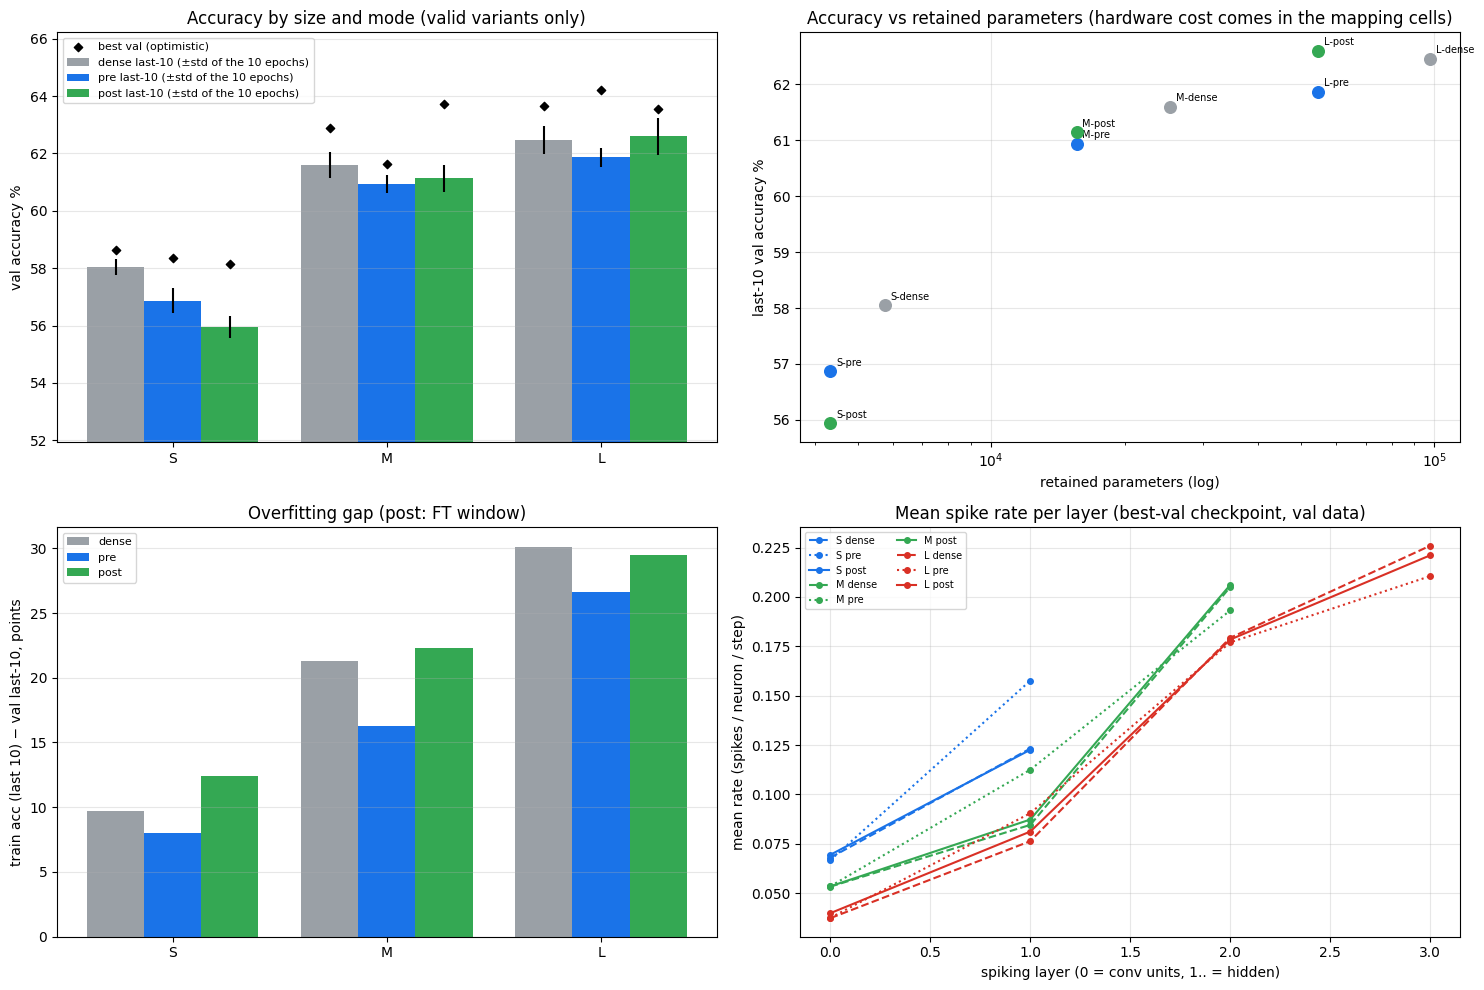


Saved: /content/drive/MyDrive/Prototype_10/results/all_variants_summary.csv
       /content/drive/MyDrive/Prototype_10/figures/08_all_variants.png

Cell 8 complete.


In [ ]:
# ===================== CELL 8: Results table + plots for ALL valid variants (dense / pre / post) with STALE GUARD =====================
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------- Prelude (same pattern as Cells 5-7; no training here, so no GPU/data needed) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH = config['TRAIN'], config['FT'], config['ARCH']
MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'variant_paths' not in globals():
    from p10_model import *
    from p10_train import *
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}

# ---------- CONTROL PANEL ----------
SIZES     = ["S", "M", "L"]
SEEDS_RUN = list(config['SEEDS'])
MODES     = ["dense", "pre", "post"]
tu = config['STEPS']['total_updates']
EXP_UPD = dict(dense=tu['dense'], pre=tu['pre'], post=tu['post'])                       # 4800 / 4800 / 6400
EXP_EP  = dict(dense=TRAIN['EPOCHS'], pre=TRAIN['EPOCHS'], post=FT['FT_EPOCHS'])        # 150 / 150 / 50 (post history = FT epochs only)
EXP_CONN = {"S": {"dense": 3072, "sparse": 1664}, "M": {"dense": 19712, "sparse": 9984}, "L": {"dense": 86272, "sparse": 43264}}
K = TRAIN['LAST_K_EPOCHS']
print(f"ALL-VARIANT RESULTS | sizes {SIZES} | seeds {SEEDS_RUN} | modes {MODES}")

# ---------- 1) STALE GUARD: a variant is valid only if total_updates and epochs match the current recipe ----------
print(f"\n[1] STALE GUARD (valid = all 7 files + total_updates {EXP_UPD} + epochs {EXP_EP}; post also needs a valid dense_updates)")
valid = {}
for seed in SEEDS_RUN:
    for size in SIZES:
        for mode in MODES:
            key = variant_key(size, mode, seed)
            if not is_done(DIRS, key):
                print(f"  — {key}: not on Drive (omitted)"); continue
            r = json.load(open(variant_paths(DIRS, key)['results']))
            ok = r['total_updates'] == EXP_UPD[mode] and r['epochs'] == EXP_EP[mode]
            if ok and mode == "post": ok = r['extra']['dense_updates'] == EXP_UPD['dense']
            print(f"  {'✅ valid' if ok else '⛔ STALE (omitted from every table and plot)'} {key}: total_updates {r['total_updates']} (need {EXP_UPD[mode]}), epochs {r['epochs']} (need {EXP_EP[mode]})")
            if ok: valid[(size, mode, seed)] = r
for seed in SEEDS_RUN:
    for size in SIZES:
        chk((size, "dense", seed) in valid and (size, "post", seed) in valid, f"{size} s{seed}: dense and post are valid")
n_pre = sum(1 for k in valid if k[1] == "pre")
print(f"  pre-sparse: {n_pre} of {len(SIZES) * len(SEEDS_RUN)} variants valid" + ("" if n_pre == len(SIZES) * len(SEEDS_RUN) else
      " -> pre is NOT in the tables/plots below; retrain it (Cell 6 with FORCE_RETRAIN=True) and re-run this cell"))

# ---------- 2) One row per valid variant ----------
rows = []
for size in SIZES:
    for mode in MODES:
        for seed in SEEDS_RUN:
            r = valid.get((size, mode, seed))
            if r is None: continue
            h = r['history']; tr = float(np.mean(h['train_acc'][-K:]))
            own_min = r['train_time_s'] / 60
            tot_min = own_min + (r['extra']['dense']['train_time_s'] / 60 if mode == "post" else 0.0)
            rows.append(dict(variant=r['key'], size=size, mode=mode, seed=seed, window=("last 10 of 50 FT epochs" if mode == "post" else "last 10 of 150 epochs"),
                             params=r['n_params'], retained_params=r['retained_params'], fc_connections=r['fc_connections'],
                             sparsity_per_masked_layer=str([round(m_['sparsity'], 3) for m_ in r['mask_report']]),
                             masked_sparsity=r['masked_layers_sparsity'], whole_sparsity=r['whole_model_sparsity'],
                             best_val=r['best_acc'], best_epoch=r['best_epoch'], last_epoch_val=r['last_epoch_acc'],
                             last10_mean=r['last_k_mean'], last10_std=r['last_k_std'], train_acc_last10=tr, train_minus_val=tr - r['last_k_mean'],
                             rate_mean=str(np.round(r['rate_mean_per_layer'], 4).tolist()), silent=str(r['silent_per_layer']), neurons=str(r['neurons_per_layer']),
                             minutes_own=own_min, minutes_total=tot_min, total_updates=r['total_updates'], gate=r['gate']))
df = pd.DataFrame(rows)

print("\n" + "=" * 170)
print(f"[2] ALL VALID VARIANTS (validation set; chance 25%, LDA {config['DATA']['lda_val_acc']*100:.1f}%; best-val is optimistic; post best/last-10 are over the FT epochs only)")
print("=" * 170)
print(f"{'variant':<13}{'params':>8}{'retained':>9}{'FC conn':>8}{'sparsity/masked layer':>24}{'whole':>7}{'best (ep)':>14}{'last-10 mean':>15}{'last ep':>9}{'train':>8}{'gap':>6}{'silent/layer':>18}{'rate/layer':>28}{'min own/total':>16}")
for x in rows:
    print(f"{x['variant']:<13}{x['params']:>8,}{x['retained_params']:>9,}{x['fc_connections']:>8,}{x['sparsity_per_masked_layer']:>24}{x['whole_sparsity']*100:>6.1f}%"
          f"{x['best_val']*100:>8.2f}% ({x['best_epoch']:>3}){x['last10_mean']*100:>9.2f}±{x['last10_std']*100:<4.2f}{x['last_epoch_val']*100:>8.2f}%{x['train_acc_last10']*100:>7.1f}%{x['train_minus_val']*100:>6.1f}"
          f"{x['silent']:>18}{x['rate_mean']:>28}{x['minutes_own']:>8.1f}/{x['minutes_total']:<6.1f}")
if len(SEEDS_RUN) > 1:
    print("\nMEAN +/- STD ACROSS SEEDS:\n" + df.groupby(['size', 'mode'])[['best_val', 'last10_mean']].agg(['mean', 'std']).round(4).to_string())

# ---------- 3) Pairwise differences (same size and seed), with the noise caveat ----------
print("\n[3] PAIRWISE DIFFERENCES (points; flagged WITHIN when |Δlast10| <= the larger last-10 std). Windows differ (post: FT epochs), budgets differ (post 6400 vs 4800 updates).")
print(f"{'size/seed':<10}{'comparison':<14}{'Δbest':>8}{'Δlast10':>9}{'noise (std)':>13}  note")
for seed in SEEDS_RUN:
    for size in SIZES:
        for a_, b_ in (("post", "dense"), ("pre", "dense"), ("pre", "post")):
            ra, rb = valid.get((size, a_, seed)), valid.get((size, b_, seed))
            if ra is None or rb is None: continue
            dl = ra['last_k_mean'] - rb['last_k_mean']; sd = max(ra['last_k_std'], rb['last_k_std'])
            print(f"{size + ' s' + str(seed):<10}{a_ + ' - ' + b_:<14}{(ra['best_acc'] - rb['best_acc'])*100:>+8.2f}{dl*100:>+9.2f}{sd*100:>13.2f}  {'WITHIN noise' if abs(dl) <= sd else 'outside noise'}")

# ---------- 4) Checks ----------
print("\n[4] CHECKS")
for (size, mode, seed), r in valid.items():
    k = r['key']; sparse = mode != "dense"
    soft(r['gate'] == "PASS", f"{k}: gate {r['gate']}")
    chk(abs(r['masked_layers_sparsity'] - (config['MASK']['SPARSITY'] if sparse else 0.0)) < 1e-9, f"{k}: masked-layer sparsity {r['masked_layers_sparsity']*100:.1f}% (whole model {r['whole_model_sparsity']*100:.1f}%)")
    chk(r['fc_connections'] == EXP_CONN[size]["sparse" if sparse else "dense"], f"{k}: FC connections {r['fc_connections']:,}")
    soft(all(0.002 < x < 0.5 for x in r['rate_mean_per_layer']), f"{k}: mean rate per layer {np.round(r['rate_mean_per_layer'], 3).tolist()}")
    soft(all(s_ == 0 for s_ in r['silent_per_layer']), f"{k}: silent neurons per layer {r['silent_per_layer']} of {r['neurons_per_layer']}")
for seed in SEEDS_RUN:
    for size in SIZES:
        a, b = valid[(size, "dense", seed)], valid[(size, "post", seed)]
        chk(a['n_params'] == b['n_params'], f"{size} s{seed}: dense and post have the same parameter-tensor sizes ({a['n_params']:,})")
        if (size, "pre", seed) in valid:
            p = valid[(size, "pre", seed)]
            chk(p['retained_params'] == b['retained_params'] and p['fc_connections'] == b['fc_connections'], f"{size} s{seed}: pre and post retain identical parameters/connections ({p['retained_params']:,} / {p['fc_connections']:,})")
print("  ℹ️ one seed (42): differences of ~1 point are within the last-10 std (0.2-0.6); best-val is a max over noisy epochs and is optimistic, so last-10 is the primary number.")
print("  ℹ️ post-sparse gets 1600 extra updates (6400 vs 4800); pre vs post is also random-mask vs magnitude-mask (intended contrast).")
print("  ℹ️ M and L overfit (train-minus-val gap above); a sparse model matching its dense twin may reflect regularisation, not topology.")

# ---------- 5) Save + plots ----------
csv_path = os.path.join(PATHS['results'], 'all_variants_summary.csv'); df.round(5).to_csv(csv_path, index=False)
register(csv_path, "all VALID dense/pre/post variants (stale-guarded): accuracy best/last-10, sparsity per layer, params, rates, silent, time, train-val gap")
mcol = {"dense": "#9aa0a6", "pre": "#1a73e8", "post": "#34a853"}; scol = {"S": "#1a73e8", "M": "#34a853", "L": "#d93025"}
modes_present = [m for m in MODES if (df['mode'] == m).any()]
g = df.groupby(['size', 'mode']).agg(best=('best_val', 'mean'), last=('last10_mean', 'mean'), err=('last10_std', 'mean')).reset_index()
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
w = 0.8 / len(modes_present); allv = []
for j, m in enumerate(modes_present):
    xs, ls, es, bs = [], [], [], []
    for i, s in enumerate(SIZES):
        q = g[(g['size'] == s) & (g['mode'] == m)]
        if len(q): xs.append(i + (j - (len(modes_present) - 1) / 2) * w); ls.append(float(q['last'].iloc[0])); es.append(float(q['err'].iloc[0])); bs.append(float(q['best'].iloc[0]))
    ax[0, 0].bar(xs, np.array(ls) * 100, w, yerr=np.array(es) * 100, color=mcol[m], label=f"{m} last-10 (±std of the 10 epochs)")
    ax[0, 0].scatter(xs, np.array(bs) * 100, marker='D', color='k', s=18, zorder=5, label="best val (optimistic)" if j == 0 else None)
    allv += ls + bs
ax[0, 0].set_xticks(range(len(SIZES))); ax[0, 0].set_xticklabels(SIZES); ax[0, 0].set_ylim(min(allv) * 100 - 4, max(allv) * 100 + 2); ax[0, 0].set_ylabel("val accuracy %")
ax[0, 0].axhline(config['DATA']['lda_val_acc'] * 100, color='k', lw=0.8, ls=':'); ax[0, 0].legend(fontsize=8); ax[0, 0].grid(axis='y', alpha=0.3)
ax[0, 0].set_title("Accuracy by size and mode (valid variants only)")
for x in rows:
    ax[0, 1].scatter(x['retained_params'], x['last10_mean'] * 100, color=mcol[x['mode']], s=70, zorder=3)
    ax[0, 1].annotate(f"{x['size']}-{x['mode']}", (x['retained_params'], x['last10_mean'] * 100), fontsize=7, xytext=(4, 4), textcoords='offset points')
ax[0, 1].set_xscale('log'); ax[0, 1].set_xlabel("retained parameters (log)"); ax[0, 1].set_ylabel("last-10 val accuracy %"); ax[0, 1].grid(alpha=0.3)
ax[0, 1].set_title("Accuracy vs retained parameters (hardware cost comes in the mapping cells)")
for j, m in enumerate(modes_present):
    xs, gp = [], []
    for i, s in enumerate(SIZES):
        q = df[(df['size'] == s) & (df['mode'] == m)]
        if len(q): xs.append(i + (j - (len(modes_present) - 1) / 2) * w); gp.append(float(q['train_minus_val'].mean()) * 100)
    ax[1, 0].bar(xs, gp, w, color=mcol[m], label=m)
ax[1, 0].set_xticks(range(len(SIZES))); ax[1, 0].set_xticklabels(SIZES); ax[1, 0].set_ylabel("train acc (last 10) − val last-10, points"); ax[1, 0].legend(fontsize=8); ax[1, 0].grid(axis='y', alpha=0.3)
ax[1, 0].set_title("Overfitting gap (post: FT window)")
ls_ = {"dense": "--", "pre": ":", "post": "-"}
for (size, mode, seed), r in valid.items():
    ax[1, 1].plot(range(len(r['rate_mean_per_layer'])), r['rate_mean_per_layer'], ls=ls_[mode], marker='o', ms=4, color=scol[size], label=f"{size} {mode}")
ax[1, 1].set_xlabel("spiking layer (0 = conv units, 1.. = hidden)"); ax[1, 1].set_ylabel("mean rate (spikes / neuron / step)"); ax[1, 1].legend(fontsize=7, ncol=2); ax[1, 1].grid(alpha=0.3)
ax[1, 1].set_title("Mean spike rate per layer (best-val checkpoint, val data)")
plt.tight_layout()
fig_path = os.path.join(PATHS['figures'], '08_all_variants.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "all valid variants: accuracy by size/mode, accuracy vs retained params, overfitting gap, spike rate per layer")
print(f"\nSaved: {csv_path}\n       {fig_path}")
print("\nCell 8 complete.")

In [ ]:
# ===================== CELL 9: Hypergraph extraction for ALL valid models (dense / post / pre once retrained) + checks + save to hypergraph/ =====================
import os, sys, json, time, pickle
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

# ---------- Prelude (same pattern as Cells 5-8) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS = config['ROOT'], config['PATHS']
TRAIN, FT, ARCH = config['TRAIN'], config['FT'], config['ARCH']
MANIFEST_PATH = os.path.join(ROOT, 'manifest.json')
device = "cuda" if torch.cuda.is_available() else "cpu"; assert device == "cuda", "use a GPU runtime"
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if 'val_loader' not in globals():
    from torch.utils.data import TensorDataset, DataLoader
    _X = np.load(os.path.join(PATHS['data'], 'X_ea.npy'), mmap_mode='r'); _y = np.load(os.path.join(PATHS['data'], 'y.npy'))
    _iv = np.load(os.path.join(PATHS['data'], 'idx_va.npy'))
    vx = torch.from_numpy(np.ascontiguousarray(_X[_iv])); vy = torch.from_numpy(_y[_iv]).long()
    val_loader = DataLoader(TensorDataset(vx, vy), batch_size=TRAIN['VAL_BATCH_SIZE'], shuffle=False)
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'load_variant' not in globals():
    from p10_model import *
    from p10_train import *
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
HG_DIR = PATHS['hypergraph']

# ---------- CONTROL PANEL ----------
SIZES     = ["S", "M", "L"]
SEEDS_RUN = list(config['SEEDS'])
MODES     = ["dense", "pre", "post"]
tu = config['STEPS']['total_updates']
EXP_UPD = dict(dense=tu['dense'], pre=tu['pre'], post=tu['post'])
EXP_EP  = dict(dense=TRAIN['EPOCHS'], pre=TRAIN['EPOCHS'], post=FT['FT_EPOCHS'])
T_STEPS = config['DATA']['T_time_steps']                       # 201 (stored by Cell 4)
print(f"HYPERGRAPH extraction | sizes {SIZES} | seeds {SEEDS_RUN} | modes {MODES} | rates measured on VAL with the best-val checkpoint, T = {T_STEPS}")

# ---------- 1) Stale guard (same rule as Cell 8): only valid variants get a hypergraph ----------
print("\n[1] STALE GUARD")
todo = []
for seed in SEEDS_RUN:
    for size in SIZES:
        for mode in MODES:
            key = variant_key(size, mode, seed)
            if not is_done(DIRS, key):
                print(f"  — {key}: not on Drive (omitted)"); continue
            r = json.load(open(variant_paths(DIRS, key)['results']))
            ok = r['total_updates'] == EXP_UPD[mode] and r['epochs'] == EXP_EP[mode]
            if ok and mode == "post": ok = r['extra']['dense_updates'] == EXP_UPD['dense']
            print(f"  {'✅ valid' if ok else '⛔ STALE (no hypergraph)'} {key}: total_updates {r['total_updates']} (need {EXP_UPD[mode]})")
            if ok: todo.append((size, mode, seed, key, r))
chk(len(todo) > 0, f"{len(todo)} valid variants")

# ---------- 2) Extractor: StepD Cell 5 offset logic (cumsum of layer sizes), adapted to FastSNN ----------
# nodes = [conv units | hidden1 | ... | hiddenN | readout]; one hyperedge per SOURCE neuron listing its destination nodes in the NEXT layer.
# Synapses come from the ACTUAL retained masks (model.fcs[l].mask, shape (out, in)); the readout is dense (every last-hidden neuron -> 4 readout nodes).
# The depthwise conv stage is NOT modelled as synapses: conv units have no inbound edges.
def extract_hypergraph(model, loader):
    sizes = list(model.spike_sizes) + [model.readout.out_features]          # [F1, h1, ..., hN, 4]
    offsets = np.cumsum([0] + sizes[:-1]).tolist()
    n_layers = len(sizes)
    # 1) rates on VAL (spikes / neuron / time step); eval_fast returns {1: conv units, 2: hidden1, ..., N+1: last hidden}
    vl, acc, _, _, _, rates_d = eval_fast(model, loader, device)
    rates = [np.asarray(rates_d[i + 1], dtype=np.float64) for i in range(n_layers - 1)] + [np.zeros(sizes[-1])]   # readout = integrator, no spikes
    nodes = list(range(sum(sizes)))
    spike_freqs = {}
    for l in range(n_layers):
        for i in range(sizes[l]): spike_freqs[offsets[l] + i] = float(rates[l][i])
    # 2) hyperedges from the masks
    h_edges = {}
    for l, fc in enumerate(model.fcs):
        mk = fc.mask.detach().cpu()
        for src in range(sizes[l]):
            dsts = torch.where(mk[:, src] > 0)[0].tolist()
            if dsts: h_edges[offsets[l] + src] = [offsets[l + 1] + d for d in dsts]
    l_last = n_layers - 2
    for src in range(sizes[l_last]):                                         # dense readout
        h_edges[offsets[l_last] + src] = [offsets[l_last + 1] + k for k in range(sizes[-1])]
    return nodes, h_edges, spike_freqs, rates, sizes, offsets, float(acc), float(vl)

# ---------- 3) Extract + check every valid model ----------
hypergraphs, layer_rates, node_maps, hg_info = {}, {}, {}, {}
print("\n[2] EXTRACTION AND CHECKS")
print(f"{'model':<13}{'nodes':>6}{'hyperedges':>11}{'synapses':>10}{'mean fan-out':>13}{'val acc':>9}{'silent nodes':>13}{'events/step':>13}{'s':>5}")
for size, mode, seed, key, r in todo:
    t0 = time.time()
    model, ck = load_variant(variant_paths(DIRS, key)['best'], device)
    nodes, h_edges, sf, rates, sizes, offsets, acc, vl = extract_hypergraph(model, val_loader)
    ai = config['ARCH_INFO'][size]; sparse = mode != "dense"
    names = ["conv_units"] + [f"hidden{i+1}" for i in range(len(ARCH[size]['hidden']))] + ["readout"]
    node_map = {n: (int(offsets[i]), int(sizes[i])) for i, n in enumerate(names)}
    # --- checks ---
    chk(abs(acc - r['best_acc']) < 1e-9, f"{key}: best-val checkpoint reproduces val acc {acc*100:.2f}% == recorded {r['best_acc']*100:.2f}%")
    chk(len(nodes) == ai['nodes'] and all(node_map[n] == tuple(ai['node_offsets'][n]) for n in names), f"{key}: {len(nodes)} nodes; node layout equals config ARCH_INFO {node_map}")
    n_syn = sum(len(d) for d in h_edges.values())
    exp_syn = ai['sparse_fc_connections'] if sparse else ai['dense_fc_connections']
    chk(n_syn == exp_syn == r['fc_connections'] == fc_connections(model), f"{key}: total synapses {n_syn:,} == fc_connections {fc_connections(model):,} == results {r['fc_connections']:,} == config {exp_syn:,}")
    ok_rng = True; ok_dup = True; ok_fanin = True; ok_fanout = True
    for s_node, dsts in h_edges.items():
        l = max(i for i in range(len(sizes)) if offsets[i] <= s_node)
        lo, hi = offsets[l + 1], offsets[l + 1] + sizes[l + 1]
        ok_rng &= all(lo <= d < hi for d in dsts); ok_dup &= len(set(dsts)) == len(dsts)
    for l, fc in enumerate(model.fcs):                                       # fan-in per destination = mask row sum; fan-out per source = mask column sum
        mk = fc.mask.detach().cpu()
        fin = np.zeros(sizes[l + 1], dtype=int); fout = np.zeros(sizes[l], dtype=int)
        for s_node, dsts in h_edges.items():
            if offsets[l] <= s_node < offsets[l] + sizes[l]:
                fout[s_node - offsets[l]] = len(dsts)
                for d in dsts: fin[d - offsets[l + 1]] += 1
        ok_fanin &= np.array_equal(fin, mk.sum(1).numpy().astype(int)); ok_fanout &= np.array_equal(fout, mk.sum(0).numpy().astype(int))
    chk(ok_rng and ok_dup, f"{key}: every destination lies in the NEXT layer, no duplicate destinations within a hyperedge")
    chk(ok_fanin and ok_fanout, f"{key}: per-node fan-in / fan-out equal the mask row / column sums for all masked layers")
    ro_nz = int((model.readout.weight.detach() != 0).sum()); ro_all = model.readout.weight.numel()
    chk(all(len(h_edges[offsets[-2] + j]) == sizes[-1] for j in range(sizes[-2])), f"{key}: dense readout: each of the {sizes[-2]} last-hidden neurons feeds all {sizes[-1]} readout nodes ({ro_nz}/{ro_all} readout weights nonzero)")
    chk(all(sf[offsets[-1] + k] == 0.0 for k in range(sizes[-1])), f"{key}: readout nodes have spike_freq 0")
    sav = np.load(variant_paths(DIRS, key)['rates'])
    d_rate = max(float(np.abs(np.asarray(sav[f'best_L{i+1}'], dtype=np.float64) - rates[i]).max()) for i in range(len(sizes) - 1))
    chk(d_rate < 1e-4, f"{key}: re-measured rates equal the saved rates_{key}.npz (max|diff| {d_rate:.1e})")
    silent = [int((rates[i] == 0).sum()) for i in range(len(sizes) - 1)]
    chk(silent == list(r['silent_per_layer']), f"{key}: silent neurons per layer {silent} equal results")
    soft(all(0.002 < rates[i].mean() < 0.5 for i in range(len(sizes) - 1)), f"{key}: mean rate per spiking layer {[round(float(x.mean()), 4) for x in rates[:-1]]}")
    n_src_nohedge = sum(1 for n in nodes[:offsets[-1]] if n not in h_edges)
    soft(n_src_nohedge == 0, f"{key}: {n_src_nohedge} non-readout nodes without an outgoing hyperedge (conv units with zero fan-out after pruning would show here)")
    events = sum(sf[s_] * len(d) for s_, d in h_edges.items())
    ev_layer = [sum(sf[s_] * len(d) for s_, d in h_edges.items() if offsets[l] <= s_ < offsets[l] + sizes[l]) for l in range(len(sizes) - 1)]
    hypergraphs[key] = (nodes, h_edges, sf); layer_rates[key] = rates; node_maps[key] = node_map
    hg_info[key] = dict(variant=key, size=size, mode=mode, seed=seed, nodes=len(nodes), hyperedges=len(h_edges), synapses=n_syn,
                        mean_fanout=n_syn / len(h_edges), val_acc=acc, best_val=r['best_acc'], silent_per_layer=str(silent),
                        silent_nodes=int(sum(silent)), rate_mean_per_layer=str([round(float(x.mean()), 4) for x in rates[:-1]]),
                        events_per_step=events, events_per_layer=str([round(x, 3) for x in ev_layer]), T=T_STEPS)
    print(f"{key:<13}{len(nodes):>6}{len(h_edges):>11}{n_syn:>10,}{n_syn/len(h_edges):>13.1f}{acc*100:>8.2f}%{sum(silent):>13}{events:>13.2f}{time.time()-t0:>5.0f}")
    del model; torch.cuda.empty_cache()
print("  (events/step = sum over sources of rate x fan-out: a traffic proxy from StepD Cell 5, before any placement.)")
print("  Conv stage: depthwise conv units have no inbound edges (not modelled as synapses); rates are spikes / neuron / time step with T = %d." % T_STEPS)

# ---------- 4) Pairs: sparse vs dense within a size (what changed in the graph) ----------
print("\n[3] SPARSE vs DENSE GRAPH (same size, same seed)")
for seed in SEEDS_RUN:
    for size in SIZES:
        kd = variant_key(size, "dense", seed)
        for mode in ("post", "pre"):
            ks = variant_key(size, mode, seed)
            if kd in hg_info and ks in hg_info:
                a, b = hg_info[kd], hg_info[ks]
                print(f"  {ks} vs {kd}: synapses {b['synapses']:,} / {a['synapses']:,} = {b['synapses']/a['synapses']*100:.1f}% | events/step {b['events_per_step']:.2f} vs {a['events_per_step']:.2f} "
                      f"({(b['events_per_step']/a['events_per_step']-1)*100:+.1f}%) | silent nodes {b['silent_nodes']} vs {a['silent_nodes']}")
for seed in SEEDS_RUN:
    for size in SIZES:
        kp, kq = variant_key(size, "pre", seed), variant_key(size, "post", seed)
        if kp in hypergraphs and kq in hypergraphs:
            chk(hg_info[kp]['synapses'] == hg_info[kq]['synapses'], f"{size} s{seed}: pre and post graphs have the same number of synapses (the topology differs, the count does not)")

# ---------- 5) Save ----------
pkl_path = os.path.join(HG_DIR, 'hypergraphs_val.pkl')
with open(pkl_path, 'wb') as f:
    pickle.dump({"hypergraphs": hypergraphs, "layer_rates": layer_rates, "node_maps": node_maps, "info": hg_info, "split": "val",
                 "T": T_STEPS, "note": "nodes=[conv units|hidden1..|readout]; h_edges={source: [dest nodes]} from the actual masks incl. dense readout; "
                                       "spike_freqs measured on VAL with the best-val checkpoint (readout=0); conv stage not modelled as synapses"}, f)
register(pkl_path, "hypergraphs (nodes, h_edges, spike_freqs) for every valid variant, rates measured on val with the best-val checkpoint; layer_rates, node_maps, info")
csv_path = os.path.join(HG_DIR, 'hypergraph_summary.csv'); pd.DataFrame(list(hg_info.values())).round(5).to_csv(csv_path, index=False)
register(csv_path, "hypergraph summary per valid variant: nodes, hyperedges, synapses, fan-out, silent nodes, events per step")

# ---------- 6) Plots ----------
scol = {"S": "#1a73e8", "M": "#34a853", "L": "#d93025"}; ls_ = {"dense": "--", "pre": ":", "post": "-"}; hat = {"dense": "", "pre": "..", "post": "//"}
keys = list(hypergraphs)
fig, ax = plt.subplots(2, 3, figsize=(19, 10))
for k in keys:
    s, m = hg_info[k]['size'], hg_info[k]['mode']
    rr = layer_rates[k][:-1]
    ax[0, 0].plot(range(len(rr)), [x.mean() for x in rr], marker='o', color=scol[s], ls=ls_[m], label=k)
    ax[0, 1].hist(np.concatenate(rr), bins=np.linspace(0, 1, 81), histtype='step', density=True, lw=1.5, color=scol[s], ls=ls_[m], label=k)
    fo = np.sort([len(d) for d in hypergraphs[k][1].values()])
    ax[0, 2].plot(fo, np.arange(1, len(fo) + 1) / len(fo), drawstyle='steps-post', color=scol[s], ls=ls_[m], label=k)
ax[0, 0].set_xlabel("spiking layer (0 = conv units)"); ax[0, 0].set_ylabel("mean rate (spikes / neuron / step)"); ax[0, 0].set_title("Mean rate per spiking layer (val, best-val checkpoint)")
ax[0, 1].set_xlabel("neuron rate"); ax[0, 1].set_ylabel("density"); ax[0, 1].set_title("Per-neuron rates (all spiking neurons)")
ax[0, 2].set_xscale('log'); ax[0, 2].set_xlabel("destinations per source (hyperedge size)"); ax[0, 2].set_ylabel("fraction of sources"); ax[0, 2].set_title("Hyperedge sizes (ECDF)")
for a_ in (ax[0, 0], ax[0, 1], ax[0, 2]): a_.legend(fontsize=7, ncol=2); a_.grid(alpha=0.3)
cols = [scol[hg_info[k]['size']] for k in keys]; hs = [hat[hg_info[k]['mode']] for k in keys]
b = ax[1, 0].bar(keys, [hg_info[k]['events_per_step'] for k in keys], color=cols, hatch=hs, edgecolor='white'); ax[1, 0].set_yscale('log')
for bb, k in zip(b, keys): ax[1, 0].text(bb.get_x() + bb.get_width() / 2, bb.get_height(), f"{hg_info[k]['events_per_step']:.0f}", ha='center', va='bottom', fontsize=8)
ax[1, 0].set_ylabel("synaptic events per time step (proxy)"); ax[1, 0].set_title("Spike traffic before placement"); ax[1, 0].tick_params(axis='x', rotation=45); ax[1, 0].grid(axis='y', alpha=0.3)
b = ax[1, 1].bar(keys, [hg_info[k]['synapses'] for k in keys], color=cols, hatch=hs, edgecolor='white'); ax[1, 1].set_yscale('log')
for bb, k in zip(b, keys): ax[1, 1].text(bb.get_x() + bb.get_width() / 2, bb.get_height(), f"{hg_info[k]['synapses']:,}", ha='center', va='bottom', fontsize=8)
ax[1, 1].set_ylabel("synapses (FC connections incl. readout)"); ax[1, 1].set_title("Synapses per model"); ax[1, 1].tick_params(axis='x', rotation=45); ax[1, 1].grid(axis='y', alpha=0.3)
maxL = max(len(json.loads(hg_info[k]['events_per_layer'])) for k in keys); bottom = np.zeros(len(keys))
for l in range(maxL):
    vals = np.array([json.loads(hg_info[k]['events_per_layer'])[l] if l < len(json.loads(hg_info[k]['events_per_layer'])) else 0.0 for k in keys])
    ax[1, 2].bar(keys, vals, bottom=bottom, label=("conv units" if l == 0 else f"hidden{l}") + " -> next", alpha=0.85); bottom += vals
ax[1, 2].set_ylabel("events per step"); ax[1, 2].set_title("Traffic by source layer"); ax[1, 2].legend(fontsize=8); ax[1, 2].tick_params(axis='x', rotation=45); ax[1, 2].grid(axis='y', alpha=0.3)
plt.tight_layout()
fig_path = os.path.join(PATHS['figures'], '09_hypergraph_extraction.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "hypergraph extraction: rates per layer, rate distribution, hyperedge size ECDF, synapses, traffic proxy per model")
print(f"\nModels with a hypergraph: {keys}")
print(f"Saved: {pkl_path}\n       {csv_path}\n       {fig_path}")
print("\nCell 9 complete.")

HYPERGRAPH extraction | sizes ['S', 'M', 'L'] | seeds [42] | modes ['dense', 'pre', 'post'] | rates measured on VAL with the best-val checkpoint, T = 201

[1] STALE GUARD
  ✅ valid S_dense_s42: total_updates 4800 (need 4800)
  ✅ valid S_pre_s42: total_updates 4800 (need 4800)
  ✅ valid S_post_s42: total_updates 6400 (need 6400)
  ✅ valid M_dense_s42: total_updates 4800 (need 4800)
  ✅ valid M_pre_s42: total_updates 4800 (need 4800)
  ✅ valid M_post_s42: total_updates 6400 (need 6400)
  ✅ valid L_dense_s42: total_updates 4800 (need 4800)
  ✅ valid L_pre_s42: total_updates 4800 (need 4800)
  ✅ valid L_post_s42: total_updates 6400 (need 6400)
  ✅ 9 valid variants

[2] EXTRACTION AND CHECKS
model         nodes hyperedges  synapses mean fan-out  val acc silent nodes  events/step    s


Mapping toolkit written and imported from /content/drive/MyDrive/Prototype_10/code/p10_mapping.py
  C_NPC 32 (enforced) | C_APC 128, C_SPC 512 (audited, NOT enforced) | E_R 1.7 E_T 3.5 pJ | L_R 2.1 L_T 5.3 ns | refinement iterations 1500 | Manhattan distance, Hilbert grid = next power of two

[1] HYPERGRAPHS
  ✅ pickle T = 201
  ✅ S_dense_s42: hypergraph is current (results total_updates 4800, best-val 58.63% equals the value stored with the graph)
  ✅ S_pre_s42: hypergraph is current (results total_updates 4800, best-val 58.34% equals the value stored with the graph)
  ✅ S_post_s42: hypergraph is current (results total_updates 6400, best-val 58.15% equals the value stored with the graph)
  ✅ M_dense_s42: hypergraph is current (results total_updates 4800, best-val 62.87% equals the value stored with the graph)
  ✅ M_pre_s42: hypergraph is current (results total_updates 4800, best-val 61.62% equals the value stored with the graph)
  ✅ M_post_s42: hypergraph is current (results total_upd

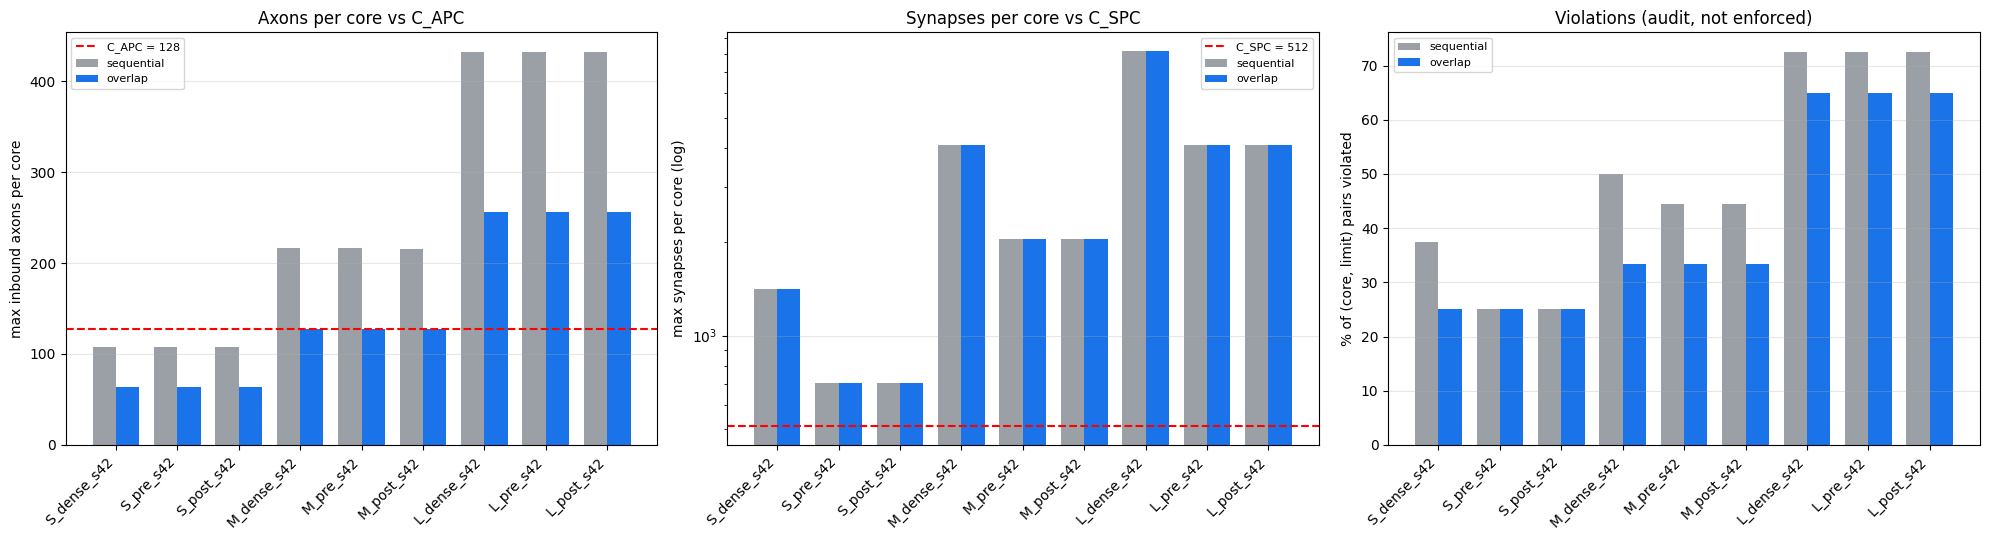


Saved: /content/drive/MyDrive/Prototype_10/code/p10_mapping.py
       /content/drive/MyDrive/Prototype_10/hypergraph/partitions_val.pkl
       /content/drive/MyDrive/Prototype_10/hypergraph/mapping_audit.csv
       /content/drive/MyDrive/Prototype_10/figures/10_mapping_audit.png
       config updated (MAPPING_CODE)

Cell 10 complete.


In [34]:
# ===================== CELL 10: Mapping toolkit (Prototype8 Cell 6) + verification for deeper graphs + hardware audit =====================
import os, sys, json, time, math, random, pickle, hashlib, importlib
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------- Prelude (same pattern as Cells 5-9; no GPU needed) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS, HW = config['ROOT'], config['PATHS'], config['HW']
TRAIN, FT = config['TRAIN'], config['FT']
MANIFEST_PATH, CONFIG_PATH = os.path.join(ROOT, 'manifest.json'), os.path.join(PATHS['config'], 'config.json')
HG_DIR = PATHS['hypergraph']
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'variant_paths' not in globals():
    from p10_model import *
    from p10_train import *
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
tu = config['STEPS']['total_updates']
EXP_UPD = dict(dense=tu['dense'], pre=tu['pre'], post=tu['post'])

# ---------- 1) NEW code file code/p10_mapping.py: toolkit COPIED from Prototype8 Cell 6 ----------
MAP_SRC = r'''# p10_mapping.py -- Prototype 10 mapping toolkit (written by Cell 10). Functions are COPIED from Prototype8 Cell 6;
# the only change: hardware constants are read from config['HW'] via set_hw() instead of being hard-coded in each function.
import math, random
from collections import Counter

HW = None
def set_hw(hw):
    global HW
    HW = dict(hw)
def _hw():
    assert HW is not None, "call set_hw(config['HW']) first"
    return HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T']

# (from Prototype8 Cell 6) greedy overlap (hypergraph-aware) partitioning
def overlap_partitioning(nodes, h_edges, spike_freqs, max_neurons_per_core):
    partition_map = {n: None for n in nodes}
    inbound_sets = {n: set() for n in nodes}
    for edge_id, dests in h_edges.items():
        for d in dests: inbound_sets[d].add(edge_id)
    unmapped = set(nodes); pid = 0
    while unmapped:
        core = set(); seed = max(unmapped, key=lambda n: spike_freqs.get(n, 0))
        core.add(seed); unmapped.remove(seed)
        core_edges = set(inbound_sets[seed])
        while len(core) < max_neurons_per_core and unmapped:
            best = max(unmapped, key=lambda n: len(inbound_sets[n] & core_edges))
            core.add(best); unmapped.remove(best); core_edges |= inbound_sets[best]
        for n in core: partition_map[n] = pid
        pid += 1
    return partition_map

# (from Prototype8 Cell 6) naive baseline: fill cores by node id
def sequential_partitioning(nodes, max_neurons_per_core):
    pm, core, cnt = {}, 0, 0
    for n in sorted(nodes):
        pm[n] = core; cnt += 1
        if cnt >= max_neurons_per_core: core += 1; cnt = 0
    return pm

def hilbert_d2xy(n, d):
    t = d; x = y = 0; s = 1
    while s < n:
        rx = 1 & (t // 2); ry = 1 & (t ^ rx)
        if ry == 0:
            if rx == 1: x = s - 1 - x; y = s - 1 - y
            x, y = y, x
        x += s * rx; y += s * ry; t //= 4; s *= 2
    return x, y

def _grid(num):
    return 2 ** max(1, math.ceil(math.log2(math.sqrt(num))))

def hilbert_initial_placement(pm):
    ups = sorted(set(pm.values())); n = _grid(len(ups))
    return {p: hilbert_d2xy(n, i) for i, p in enumerate(ups)}, n

def linear_placement(pm):
    ups = sorted(set(pm.values())); n = _grid(len(ups))
    return {p: (i % n, i // n) for i, p in enumerate(ups)}, n

def calculate_hardware_cost(place, phe, total_spikes):
    E_R, E_T, L_R, L_T = _hw()
    en = lat = 0.0
    for sp, dps, w in phe:
        if sp not in place: continue
        x1, y1 = place[sp]
        for dp in dps:
            if dp not in place: continue
            x2, y2 = place[dp]; d = abs(x1 - x2) + abs(y1 - y2)
            en += w * (d * (E_R + E_T) + E_R); lat += w * (d * (L_R + L_T) + L_R)
    return en * (lat / total_spikes if total_spikes > 0 else 0)

def placement_refinement(place, pm, h_edges, spike_freqs, iterations=2000):
    phe, tot = [], 0.0
    for s, dests in h_edges.items():
        w = spike_freqs.get(s, 0)
        if w == 0: continue
        sp = pm.get(s)
        if sp is None: continue
        dps = {pm[d] for d in dests if pm.get(d) is not None and pm[d] != sp}
        if dps: phe.append((sp, dps, w)); tot += w
    parts = list(place.keys()); cur = calculate_hardware_cost(place, phe, tot)
    if len(parts) < 2: return place, cur
    for _ in range(iterations):
        p1, p2 = random.sample(parts, 2)
        place[p1], place[p2] = place[p2], place[p1]
        new = calculate_hardware_cost(place, phe, tot)
        if new < cur: cur = new
        else: place[p1], place[p2] = place[p2], place[p1]
    return place, cur

def evaluate_mapping(h_edges, spike_freqs, pm, place):
    E_R, E_T, L_R, L_T = _hw()
    en = ln = ld = conn = 0.0
    for s, dests in h_edges.items():
        w = spike_freqs.get(s, 0)
        if w == 0: continue
        sp = pm.get(s)
        if sp not in place: continue
        sl = place[sp]
        dps = {pm[d] for d in dests if pm.get(d) is not None and pm[d] != sp}
        conn += w * len(dps)
        for dp in dps:
            if dp not in place: continue
            dist = abs(sl[0] - place[dp][0]) + abs(sl[1] - place[dp][1])
            en += w * (dist * (E_R + E_T) + E_R); ln += w * (dist * (L_R + L_T) + L_R); ld += w
    avg_lat = ln / ld if ld > 0 else 0
    ib_syn = {p: 0 for p in set(pm.values())}; ib_ax = {p: set() for p in set(pm.values())}
    for s, dests in h_edges.items():
        for d in dests:
            dp = pm.get(d)
            if dp is not None: ib_syn[dp] += 1; ib_ax[dp].add(s)
    reuse = [ib_syn[p] / len(ib_ax[p]) for p in ib_syn if ib_ax[p]]
    return {"Connectivity": round(conn, 6), "Total Energy (pJ)": round(en, 6), "Average Latency (ns)": round(avg_lat, 6),
            "Energy-Latency Product": round(en * avg_lat, 6), "Synaptic Reuse": round(sum(reuse) / len(reuse), 4) if reuse else 0}

# (from Prototype8 Cell 6) audit as-is: counts ALL inbound sources of a core's neurons, including sources inside the same core (the stricter definition)
def core_audit(h_edges, pm):
    ax = {p: set() for p in set(pm.values())}; syn = {p: 0 for p in ax}
    for s, dests in h_edges.items():
        for d in dests:
            p = pm[d]; ax[p].add(s); syn[p] += 1
    return {"max axons/core": max(len(v) for v in ax.values()), "max synapses/core": max(syn.values()),
            "cores > C_apc": sum(len(v) > HW['C_APC'] for v in ax.values()),
            "cores > C_spc": sum(v > HW['C_SPC'] for v in syn.values()), "cores": len(ax)}
'''
MAP_PATH = os.path.join(PATHS['code'], 'p10_mapping.py')
with open(MAP_PATH, 'w') as f: f.write(MAP_SRC)
register(MAP_PATH, "mapping toolkit copied from Prototype8 Cell 6 (partitioners, Hilbert/linear placement, refinement, evaluate_mapping, core_audit); constants from config HW")
import p10_mapping; importlib.reload(p10_mapping)
from p10_mapping import (overlap_partitioning, sequential_partitioning, hilbert_d2xy, _grid, hilbert_initial_placement,
                         linear_placement, calculate_hardware_cost, placement_refinement, evaluate_mapping, core_audit, set_hw)
set_hw(HW)
C_NPC, C_APC, C_SPC = HW['C_NPC'], HW['C_APC'], HW['C_SPC']
E_R, E_T, L_R, L_T, ITERS = HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T'], HW['ITERATIONS']
print(f"Mapping toolkit written and imported from {MAP_PATH}")
print(f"  C_NPC {C_NPC} (enforced) | C_APC {C_APC}, C_SPC {C_SPC} (audited, NOT enforced) | E_R {E_R} E_T {E_T} pJ | L_R {L_R} L_T {L_T} ns | refinement iterations {ITERS} | {HW['MESH']}")

# ---------- 2) Load hypergraphs (Cell 9 pickle) + staleness guard ----------
print("\n[1] HYPERGRAPHS")
HG = pickle.load(open(os.path.join(HG_DIR, 'hypergraphs_val.pkl'), 'rb'))
hypergraphs, hg_info, node_maps, T_STEPS = HG['hypergraphs'], HG['info'], HG['node_maps'], HG['T']
chk(T_STEPS == config['DATA']['T_time_steps'], f"pickle T = {T_STEPS}")
for key, (nodes, h_edges, sf) in hypergraphs.items():
    r = json.load(open(variant_paths(DIRS, key)['results'])); mode = hg_info[key]['mode']
    chk(r['total_updates'] == EXP_UPD[mode] and abs(r['best_acc'] - hg_info[key]['best_val']) < 1e-12,
        f"{key}: hypergraph is current (results total_updates {r['total_updates']}, best-val {r['best_acc']*100:.2f}% equals the value stored with the graph)")
keys = list(hypergraphs)
print(f"  {len(keys)} models: {keys}")

# ---------- 3) Partition every model (both pipelines, neuron-count capped at C_NPC) + structural checks ----------
print("\n[2] PARTITIONING (sequential = naive baseline, overlap = greedy hypergraph-aware) AND CHECKS")
parts, ptime = {}, {}
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]
    t0 = time.time(); seq = sequential_partitioning(nodes, C_NPC); t_seq = time.time() - t0
    t0 = time.time(); ovl = overlap_partitioning(nodes, h_edges, sf, C_NPC); t_ovl = time.time() - t0
    parts[key] = dict(sequential=seq, overlap=ovl); ptime[key] = (t_seq, t_ovl)
    K_exp = math.ceil(len(nodes) / C_NPC)
    for lab, pm in parts[key].items():
        sz = Counter(pm.values())
        ok = (all(v is not None for v in pm.values()) and set(pm) == set(nodes) and sorted(sz) == list(range(len(sz)))
              and max(sz.values()) <= C_NPC and len(sz) == K_exp and sum(1 for v in sz.values() if v < C_NPC) <= 1)
        chk(ok, f"{key} {lab:<10}: {len(sz)} cores (= ceil({len(nodes)}/{C_NPC})), ids 0..{len(sz)-1}, max {max(sz.values())} / min {min(sz.values())} neurons per core, every node assigned once")
    seq_ok = all(parts[key]['sequential'][n] == i // C_NPC for i, n in enumerate(sorted(nodes)))
    chk(seq_ok, f"{key} sequential : cores are contiguous node-id blocks (layer order)")
    print(f"      time: sequential {t_seq:.2f}s, overlap {t_ovl:.1f}s")
kdet = "M_dense_s42" if "M_dense_s42" in keys else keys[0]
chk(overlap_partitioning(*[hypergraphs[kdet][i] for i in (0, 1, 2)], C_NPC) == parts[kdet]['overlap'], f"{kdet}: overlap partitioning is deterministic (second run identical)")

# ---------- 4) Placement toolkit: grid / Hilbert / layout properties ----------
print("\n[3] PLACEMENT PROPERTIES (does the 2D layout logic hold for the core counts of these deeper graphs?)")
for n in (2, 4, 8, 16):
    pts = [hilbert_d2xy(n, d) for d in range(n * n)]
    chk(len(set(pts)) == n * n and all(0 <= x < n and 0 <= y < n for x, y in pts) and
        all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(pts, pts[1:])), f"Hilbert {n}x{n}: {n*n} distinct cells, all in range, consecutive indices are neighbours (distance 1)")
chk(all(((_grid(K) & (_grid(K) - 1)) == 0) and _grid(K) ** 2 >= K and (_grid(K) == 2 or (_grid(K) // 2) ** 2 < K) for K in range(1, 129)),
    "grid size is the smallest power of two n >= 2 with n*n >= cores (1..128 cores)")
def mean_pair_dist(coords):
    c = np.array(list(coords)); d = np.abs(c[:, None, :] - c[None, :, :]).sum(-1)
    return d.sum() / (len(c) * (len(c) - 1))
K_set = sorted({len(set(pm.values())) for k in keys for pm in parts[k].values()})
print(f"  {'cores':>6}{'grid':>8}{'cells':>7}{'fill':>7}{'linear: mean pair dist':>24}{'bbox':>8}{'Hilbert: mean pair dist':>25}{'bbox':>8}")
for K in K_set:
    pmK = {i: i for i in range(K)}; lp, n = linear_placement(pmK); hp, _ = hilbert_initial_placement(pmK)
    chk(len(set(lp.values())) == K and len(set(hp.values())) == K and all(0 <= x < n and 0 <= y < n for x, y in list(lp.values()) + list(hp.values())),
        f"{K} cores: linear and Hilbert layouts are injective and inside the {n}x{n} grid")
    bb = lambda p: f"{max(x for x, _ in p.values()) + 1}x{max(y for _, y in p.values()) + 1}"
    print(f"  {K:>6}{str(n)+'x'+str(n):>8}{n*n:>7}{K/(n*n)*100:>6.0f}%{mean_pair_dist(lp.values()):>24.2f}{bb(lp):>8}{mean_pair_dist(hp.values()):>25.2f}{bb(hp):>8}")
print("  ℹ️ Placement = first K cells of a row-major scan (linear) or of the Hilbert curve; the refinement only swaps cores among the K occupied cells (it never moves into empty cells).")
print("  ℹ️ Hence 'placement only' (B vs A) also changes the layout SHAPE (mean pair distance above), not only the core order: say so when interpreting B vs A.")

# ---------- 5) Independent re-implementation of the metrics (vectorised numpy) vs the copied functions ----------
def indep_metrics(h_edges, sf, pm, place):
    N = max(pm) + 1; K = max(pm.values()) + 1
    P = np.array([pm[n] for n in range(N)]); Wt = np.array([sf[n] for n in range(N)])
    C = np.array([place[p] for p in range(K)])
    src = np.repeat(np.array(list(h_edges.keys())), [len(v) for v in h_edges.values()]); dst = np.concatenate([np.array(v) for v in h_edges.values()])
    cross = (P[src] != P[dst]) & (Wt[src] > 0)
    pairs = np.unique(src[cross] * K + P[dst][cross]); s_, q_ = pairs // K, pairs % K          # one (source, destination core) pair, as in evaluate_mapping
    dist = np.abs(C[P[s_]] - C[q_]).sum(1); w = Wt[s_]
    en = float((w * (dist * (E_R + E_T) + E_R)).sum()); ln = float((w * (dist * (L_R + L_T) + L_R)).sum()); ld = float(w.sum())
    avg = ln / ld if ld > 0 else 0.0
    ax_pairs = np.unique(P[dst] * N + src); ax = np.bincount(ax_pairs // N, minlength=K); syn = np.bincount(P[dst], minlength=K)
    reuse = float(np.mean(syn[ax > 0] / ax[ax > 0]))
    return dict(conn=float(w.sum()), en=en, lat=avg, elp=en * avg, reuse=reuse, ax=ax, syn=syn, ld=ld)
print("\n[4] METRICS: copied evaluate_mapping / core_audit vs an independent numpy implementation (every model, both partitions, both placements)")
A_smoke = {}
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]; n_syn = sum(len(v) for v in h_edges.values()); ok = True
    for lab in ("sequential", "overlap"):
        pm = parts[key][lab]
        for plname, plf in (("linear", linear_placement), ("hilbert", hilbert_initial_placement)):
            place, _ = plf(pm); m = evaluate_mapping(h_edges, sf, pm, place); ii = indep_metrics(h_edges, sf, pm, place)
            ok &= (np.isclose(m["Connectivity"], ii['conn'], rtol=1e-6, atol=1e-5) and np.isclose(m["Total Energy (pJ)"], ii['en'], rtol=1e-6, atol=1e-5)
                   and np.isclose(m["Average Latency (ns)"], ii['lat'], rtol=1e-6, atol=1e-5) and np.isclose(m["Energy-Latency Product"], ii['elp'], rtol=1e-6, atol=1e-5)
                   and abs(m["Synaptic Reuse"] - ii['reuse']) < 1e-3)
            if lab == "sequential" and plname == "linear": A_smoke[key] = m
        a = core_audit(h_edges, pm)
        ok &= (a["max axons/core"] == ii['ax'].max() and a["max synapses/core"] == ii['syn'].max() and int(ii['syn'].sum()) == n_syn
               and a["cores > C_apc"] == int((ii['ax'] > C_APC).sum()) and a["cores > C_spc"] == int((ii['syn'] > C_SPC).sum()))
    m = A_smoke[key]
    chk(ok, f"{key}: Connectivity / Energy / Latency / ELP / Reuse and the audit agree (sum of synapses over cores = {n_syn:,}); A = sequential+linear: ELP {m['Energy-Latency Product']:.1f}, connectivity {m['Connectivity']:.2f}")

# ---------- 6) Refinement: objective, monotonicity, determinism, runtime ----------
print("\n[5] REFINEMENT (swap search): objective vs reported ELP, monotonic improvement, determinism, runtime")
def build_phe(h_edges, sf, pm):                                      # same construction as the first lines of placement_refinement
    phe, tot = [], 0.0
    for s, dests in h_edges.items():
        w = sf.get(s, 0)
        if w == 0: continue
        sp = pm.get(s)
        if sp is None: continue
        dps = {pm[d] for d in dests if pm.get(d) is not None and pm[d] != sp}
        if dps: phe.append((sp, dps, w)); tot += w
    return phe, tot
kobj = [k for k in ("L_dense_s42", "M_post_s42") if k in keys] or keys[:1]
for key in kobj:
    nodes, h_edges, sf = hypergraphs[key]
    for lab in ("sequential", "overlap"):
        pm = parts[key][lab]; K = len(set(pm.values())); n = _grid(K); phe, tot = build_phe(h_edges, sf, pm)
        cells = [(x, y) for x in range(n) for y in range(n)]; rng = random.Random(0); ratios = []
        for _ in range(20):
            place = dict(zip(range(K), rng.sample(cells, K)))
            ratios.append(evaluate_mapping(h_edges, sf, pm, place)["Energy-Latency Product"] / calculate_hardware_cost(place, phe, tot))
        ld = indep_metrics(h_edges, sf, pm, dict(zip(range(K), cells[:K])))['ld']
        chk(np.ptp(ratios) / np.mean(ratios) < 1e-5 and abs(np.mean(ratios) - tot / ld) / (tot / ld) < 1e-5,
            f"{key} {lab}: reported ELP / refinement objective = {np.mean(ratios):.4f} for 20 random placements, equal to sum(w over sources)/sum(w over source-core pairs) = {tot/ld:.4f} (same minimiser)")
for key in [k for k in ("S_dense_s42", "M_dense_s42", "L_dense_s42") if k in keys]:
    nodes, h_edges, sf = hypergraphs[key]
    for lab in ("sequential", "overlap"):
        pm = parts[key][lab]; phe, tot = build_phe(h_edges, sf, pm); p0, _ = hilbert_initial_placement(pm); c0 = calculate_hardware_cost(p0, phe, tot)
        random.seed(HW['PLACEMENT_SEEDS'][0]); t0 = time.time(); p1, c1 = placement_refinement(dict(p0), pm, h_edges, sf, iterations=ITERS); dt = time.time() - t0
        random.seed(HW['PLACEMENT_SEEDS'][0]); p2, _ = placement_refinement(dict(p0), pm, h_edges, sf, iterations=ITERS)
        chk(c1 <= c0 + 1e-12 and abs(c1 - calculate_hardware_cost(p1, phe, tot)) < 1e-9 * max(1.0, abs(c1)) and sorted(p1.values()) == sorted(p0.values()) and p1 == p2,
            f"{key} {lab}: Hilbert start cost {c0:.3f} -> refined {c1:.3f} ({(c1-c0)/c0*100:+.1f}%) in {dt:.1f}s ({ITERS} swaps); same cells, same result for the same seed")
print("  ℹ️ runtime of one refinement run above x (2 pipelines x 5 seeds x 9 models) is the budget of the ablation cell.")

# ---------- 7) Hardware audit (C_APC / C_SPC reported, NOT enforced) ----------
print("\n[6] HARDWARE AUDIT: neuron cap C_NPC = %d enforced; C_APC = %d axons/core and C_SPC = %d synapses/core are AUDITED (cores counted as violating)" % (C_NPC, C_APC, C_SPC))
print("    (core_audit as in Prototype8: counts ALL inbound sources of a core's neurons including sources inside the same core, the stricter definition)")
print(f"{'model':<13}{'pipeline':<11}{'cores':>6}{'max/min nrn':>13}{'layers/core':>13}{'max axons':>11}{'max syn':>9}{'cores>%dax' % C_APC:>11}{'cores>%dsyn' % C_SPC:>12}")
audit_rows = []
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]; nm = node_maps[key]
    layer_of = {}
    for lname, (st_, sz_) in nm.items():
        for i in range(sz_): layer_of[st_ + i] = lname
    for lab in ("sequential", "overlap"):
        pm = parts[key][lab]; sz = Counter(pm.values()); a = core_audit(h_edges, pm)
        lay = {p: set() for p in sz}
        for n_, p_ in pm.items(): lay[p_].add(layer_of[n_])
        conv_cores = sum(1 for p_ in sz if "conv_units" in lay[p_])
        print(f"{key:<13}{lab:<11}{a['cores']:>6}{str(max(sz.values()))+'/'+str(min(sz.values())):>13}{np.mean([len(v) for v in lay.values()]):>13.2f}{a['max axons/core']:>11}{a['max synapses/core']:>9}{a['cores > C_apc']:>11}{a['cores > C_spc']:>12}")
        audit_rows.append(dict(variant=key, size=hg_info[key]['size'], mode=hg_info[key]['mode'], pipeline=lab, cores=a['cores'], nodes=len(nodes),
                               max_neurons_core=max(sz.values()), min_neurons_core=min(sz.values()), layers_per_core_mean=float(np.mean([len(v) for v in lay.values()])),
                               cores_with_conv_units=conv_cores, max_axons_core=a['max axons/core'], max_synapses_core=a['max synapses/core'],
                               cores_over_C_APC=a['cores > C_apc'], cores_over_C_SPC=a['cores > C_spc'], C_NPC=C_NPC, C_APC=C_APC, C_SPC=C_SPC,
                               grid=_grid(a['cores']), synapses=sum(len(v) for v in h_edges.values()), A_smoke_ELP=(A_smoke[key]['Energy-Latency Product'] if lab == "sequential" else np.nan)))
dfa = pd.DataFrame(audit_rows)
for key in keys:
    sub = dfa[dfa.variant == key]
    soft((sub.cores_over_C_APC == 0).all() and (sub.cores_over_C_SPC == 0).all(), f"{key}: audit {'within' if (sub.cores_over_C_APC == 0).all() and (sub.cores_over_C_SPC == 0).all() else 'VIOLATES'} C_APC/C_SPC (cores over axon limit: {sub.cores_over_C_APC.tolist()}, over synapse limit: {sub.cores_over_C_SPC.tolist()} of {sub.cores.tolist()} cores; [sequential, overlap])")
print("  ℹ️ Audit only: no model is re-partitioned to satisfy C_APC/C_SPC, and the sparse models are not assumed to fit; the table above is the result. Hardware gains must be read together with this.")

# ---------- 8) Save + plot ----------
pp = os.path.join(HG_DIR, 'partitions_val.pkl')
pickle.dump({"partitions": parts, "C_NPC": C_NPC, "note": "partition_map {node: core id}; sequential = node-id blocks, overlap = greedy hypergraph-aware (Prototype8 Cell 6)"}, open(pp, 'wb'))
register(pp, "partitions (sequential and overlap, C_NPC 32) for every valid model")
ap = os.path.join(HG_DIR, 'mapping_audit.csv'); dfa.round(4).to_csv(ap, index=False)
register(ap, "core counts and C_APC / C_SPC audit per model and partitioning pipeline (audited, not enforced)")
cfg = json.load(open(CONFIG_PATH))
cfg['MAPPING_CODE'] = dict(path=MAP_PATH, md5=hashlib.md5(MAP_SRC.encode()).hexdigest(), source="Prototype8 Cell 6 (copied); constants from HW", audit="core_audit counts all inbound sources incl. intra-core")
with open(CONFIG_PATH, 'w') as f: json.dump(cfg, f, indent=2)
register(CONFIG_PATH, "central config (MAPPING_CODE added in Cell 10)")
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5)); x = np.arange(len(keys)); w = 0.38
for j, (lab, col) in enumerate((("sequential", "#9aa0a6"), ("overlap", "#1a73e8"))):
    sub = dfa[dfa.pipeline == lab].set_index('variant').loc[keys]
    ax[0].bar(x + (j - 0.5) * w, sub.max_axons_core, w, color=col, label=lab); ax[1].bar(x + (j - 0.5) * w, sub.max_synapses_core, w, color=col, label=lab)
    ax[2].bar(x + (j - 0.5) * w, (sub.cores_over_C_APC + sub.cores_over_C_SPC) / (2 * sub.cores) * 100, w, color=col, label=lab)
ax[0].axhline(C_APC, color='r', ls='--', label=f"C_APC = {C_APC}"); ax[1].axhline(C_SPC, color='r', ls='--', label=f"C_SPC = {C_SPC}"); ax[1].set_yscale('log')
ax[0].set_ylabel("max inbound axons per core"); ax[1].set_ylabel("max synapses per core (log)"); ax[2].set_ylabel("% of (core, limit) pairs violated")
for a_, t_ in zip(ax, ("Axons per core vs C_APC", "Synapses per core vs C_SPC", "Violations (audit, not enforced)")):
    a_.set_xticks(x); a_.set_xticklabels(keys, rotation=45, ha='right'); a_.set_title(t_); a_.legend(fontsize=8); a_.grid(axis='y', alpha=0.3)
plt.tight_layout(); fig_path = os.path.join(PATHS['figures'], '10_mapping_audit.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "hardware audit: axons / synapses per core vs C_APC / C_SPC for every valid model and partitioning pipeline")
print(f"\nSaved: {MAP_PATH}\n       {pp}\n       {ap}\n       {fig_path}\n       config updated (MAPPING_CODE)")
print("\nCell 10 complete.")

ABLATION | placement seeds [42, 43, 44, 45, 46] | 1500 swaps | C_NPC 32 enforced, C_APC 128 / C_SPC 512 audited | Manhattan distance, Hilbert grid = next power of two

[1] INPUTS
  ✅ S_dense_s42: hypergraph is current (total_updates 4800, best-val 58.63%)
  ✅ S_pre_s42: hypergraph is current (total_updates 4800, best-val 58.34%)
  ✅ S_post_s42: hypergraph is current (total_updates 6400, best-val 58.15%)
  ✅ M_dense_s42: hypergraph is current (total_updates 4800, best-val 62.87%)
  ✅ M_pre_s42: hypergraph is current (total_updates 4800, best-val 61.62%)
  ✅ M_post_s42: hypergraph is current (total_updates 6400, best-val 63.74%)
  ✅ L_dense_s42: hypergraph is current (total_updates 4800, best-val 63.65%)
  ✅ L_pre_s42: hypergraph is current (total_updates 4800, best-val 64.22%)
  ✅ L_post_s42: hypergraph is current (total_updates 6400, best-val 63.55%)
  ✅ partitions recomputed here are identical to Cell 10's partitions_val.pkl
  9 models, partitions recomputed (deterministic)

[2] RUNNI

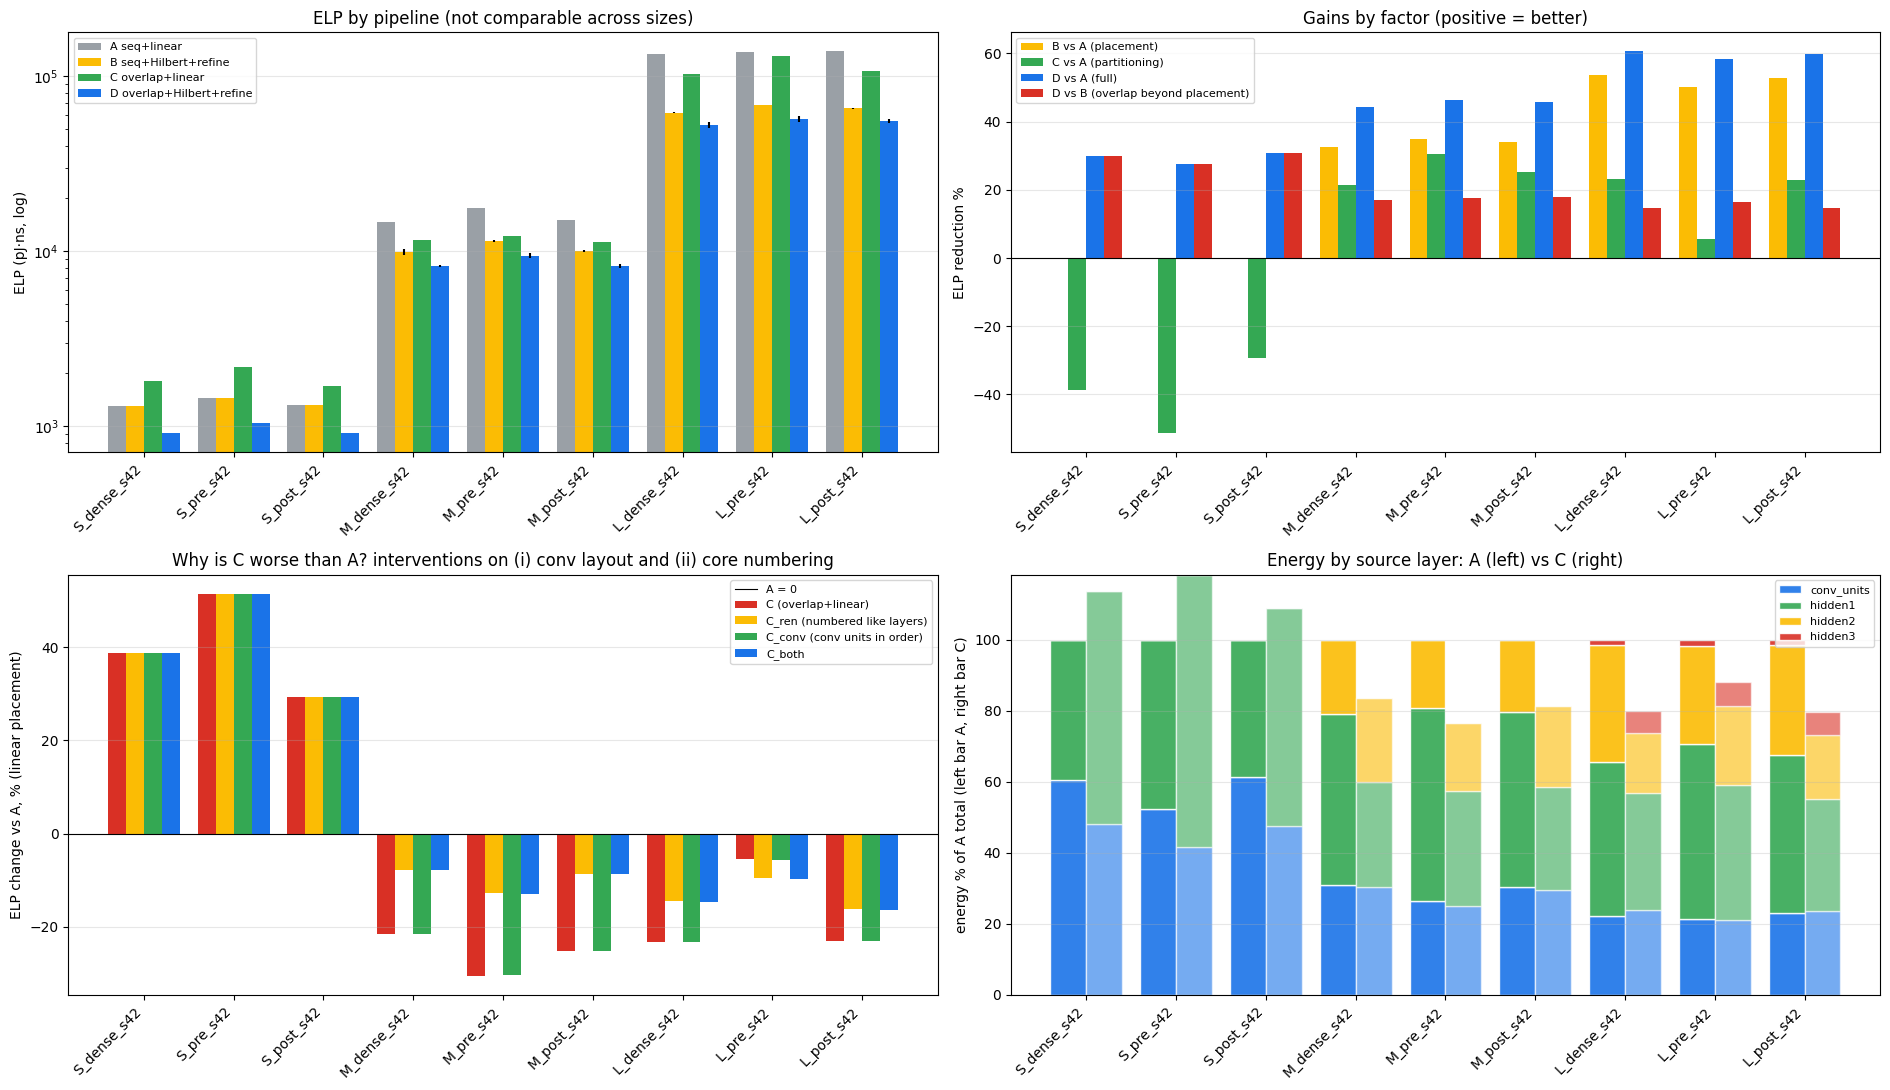


Saved: /content/drive/MyDrive/Prototype_10/hypergraph/ablation_val.csv
       /content/drive/MyDrive/Prototype_10/hypergraph/mapping_metrics_val.csv
       /content/drive/MyDrive/Prototype_10/hypergraph/c_vs_a_diagnosis_val.csv
       /content/drive/MyDrive/Prototype_10/hypergraph/pair_stats_val.csv
       /content/drive/MyDrive/Prototype_10/figures/11_ablation.png

Cell 11 complete.


In [35]:
# ===================== CELL 11: Four-way mapping ablation A/B/C/D on every valid model + test of the two explanations for "C worse than A" =====================
import os, sys, json, time, math, random, pickle
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------- Prelude (same pattern as Cells 5-10; no GPU needed) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS, HW = config['ROOT'], config['PATHS'], config['HW']
MANIFEST_PATH = os.path.join(ROOT, 'manifest.json'); HG_DIR = PATHS['hypergraph']
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'variant_paths' not in globals():
    from p10_model import *
    from p10_train import *
from p10_mapping import (overlap_partitioning, sequential_partitioning, hilbert_initial_placement, linear_placement,
                         placement_refinement, evaluate_mapping, core_audit, _grid, set_hw)
set_hw(HW)
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
C_NPC, C_APC, C_SPC = HW['C_NPC'], HW['C_APC'], HW['C_SPC']
E_R, E_T, L_R, L_T = HW['E_R'], HW['E_T'], HW['L_R'], HW['L_T']
tu = config['STEPS']['total_updates']; EXP_UPD = dict(dense=tu['dense'], pre=tu['pre'], post=tu['post'])

# ---------- CONTROL PANEL ----------
MODELS          = None                                  # None = every valid model in the Cell 9 pickle, or a list of variant keys
PLACEMENT_SEEDS = list(HW['PLACEMENT_SEEDS'])           # [42..46]: seeds of the swap search (B and D); A and C are deterministic
ITERS           = HW['ITERATIONS']                      # 1500 swaps
METRICS = ["Connectivity", "Total Energy (pJ)", "Average Latency (ns)", "Energy-Latency Product", "Synaptic Reuse"]
print(f"ABLATION | placement seeds {PLACEMENT_SEEDS} | {ITERS} swaps | C_NPC {C_NPC} enforced, C_APC {C_APC} / C_SPC {C_SPC} audited | {HW['MESH']}")

# ---------- 1) Load hypergraphs, stale guard, partitions ----------
print("\n[1] INPUTS")
HG = pickle.load(open(os.path.join(HG_DIR, 'hypergraphs_val.pkl'), 'rb'))
hypergraphs, hg_info, node_maps = HG['hypergraphs'], HG['info'], HG['node_maps']
keys = [k for k in hypergraphs if (MODELS is None or k in MODELS)]
acc = {}
for key in keys:
    r = json.load(open(variant_paths(DIRS, key)['results'])); mode = hg_info[key]['mode']
    chk(r['total_updates'] == EXP_UPD[mode] and abs(r['best_acc'] - hg_info[key]['best_val']) < 1e-12, f"{key}: hypergraph is current (total_updates {r['total_updates']}, best-val {r['best_acc']*100:.2f}%)")
    acc[key] = dict(best_val=r['best_acc'], last10_mean=r['last_k_mean'], last10_std=r['last_k_std'])
parts = {}
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]
    parts[key] = dict(sequential=sequential_partitioning(nodes, C_NPC), overlap=overlap_partitioning(nodes, h_edges, sf, C_NPC))
pp = os.path.join(HG_DIR, 'partitions_val.pkl')
if os.path.exists(pp):
    saved = pickle.load(open(pp, 'rb'))['partitions']
    soft(all(k in saved and saved[k] == parts[k] for k in keys), "partitions recomputed here are identical to Cell 10's partitions_val.pkl")
print(f"  {len(keys)} models, partitions recomputed (deterministic)")

# ---------- 2) Helpers (new; vectorised, verified against evaluate_mapping in Cell 10) ----------
def pair_arrays(h_edges, sf, pm):
    N = max(pm) + 1; K = max(pm.values()) + 1
    P = np.array([pm[n] for n in range(N)]); Wt = np.array([sf[n] for n in range(N)])
    src = np.repeat(np.array(list(h_edges.keys())), [len(v) for v in h_edges.values()]); dst = np.concatenate([np.array(v) for v in h_edges.values()])
    cross = P[src] != P[dst]
    allp = np.unique(src[cross] * K + P[dst][cross]); s_all, q_all = allp // K, allp % K
    return P, Wt, K, src, cross, s_all, q_all, Wt[s_all] > 0
def partition_stats(h_edges, sf, pm):
    P, Wt, K, src, cross, s_all, q_all, act = pair_arrays(h_edges, sf, pm)
    return dict(synapses=len(src), cross_core_syn_frac=float(cross.mean()), pairs_all=int(len(s_all)), pairs_active=int(act.sum()), connectivity=float(Wt[s_all][act].sum()))
def layer_breakdown(h_edges, sf, pm, place, node_map):          # weighted connectivity and energy per SOURCE layer (same pair definition as evaluate_mapping)
    P, Wt, K, src, cross, s_all, q_all, act = pair_arrays(h_edges, sf, pm)
    s_, q_ = s_all[act], q_all[act]; C = np.array([place[p] for p in range(K)])
    dist = np.abs(C[P[s_]] - C[q_]).sum(1); w = Wt[s_]; en = w * (dist * (E_R + E_T) + E_R)
    lid = np.zeros(len(P), dtype=int)
    for i, (nm, (st_, sz_)) in enumerate(node_map.items()): lid[st_:st_ + sz_] = i
    return {nm: dict(conn=float(w[lid[s_] == i].sum()), energy=float(en[lid[s_] == i].sum())) for i, nm in enumerate(node_map) if nm != "readout"}
def renumber_by_mean_id(pm):                                      # explanation (ii): same cores, numbered like the sequential layout (by mean node id)
    g = {}
    for n, p in pm.items(): g.setdefault(p, []).append(n)
    new = {p: i for i, p in enumerate(sorted(g, key=lambda p: np.mean(g[p])))}
    return {n: new[p] for n, p in pm.items()}
def conv_sequential_in_slots(pm, node_map):                       # explanation (i): conv units keep their slots (same core sizes) but are laid out in node-id order
    st_, sz_ = node_map['conv_units']; conv = list(range(st_, st_ + sz_)); slots = sorted(pm[n] for n in conv); new = dict(pm)
    for n, p in zip(conv, slots): new[n] = p
    return new
def refined(pm, h_edges, sf, seed):
    place, _ = hilbert_initial_placement(pm); random.seed(seed)
    place, _ = placement_refinement(place, pm, h_edges, sf, iterations=ITERS)
    assert len(set(place.values())) == len(place), "two cores share a grid cell"          # refinement only swaps, so cells stay distinct
    return evaluate_mapping(h_edges, sf, pm, place)

# ---------- 3) Four-way ablation ----------
print("\n[2] RUNNING A / B / C / D")
R, long_rows, t_start = {}, [], time.time()
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]; seq, ovl = parts[key]['sequential'], parts[key]['overlap']; t0 = time.time()
    A = evaluate_mapping(h_edges, sf, seq, linear_placement(seq)[0]); C = evaluate_mapping(h_edges, sf, ovl, linear_placement(ovl)[0])
    B_runs = [refined(seq, h_edges, sf, s) for s in PLACEMENT_SEEDS]; D_runs = [refined(ovl, h_edges, sf, s) for s in PLACEMENT_SEEDS]
    R[key] = dict(A=A, C=C, B_runs=B_runs, D_runs=D_runs)
    for lab, pm, runs, pipe in (("A", seq, [A], "sequential + linear"), ("B", seq, B_runs, "sequential + Hilbert + refinement"),
                                ("C", ovl, [C], "overlap + linear"), ("D", ovl, D_runs, "overlap + Hilbert + refinement")):
        au = core_audit(h_edges, pm); row = dict(variant=key, size=hg_info[key]['size'], mode=hg_info[key]['mode'], pipeline=lab, description=pipe, n_runs=len(runs), cores=au['cores'],
                                                    max_axons_core=au['max axons/core'], max_synapses_core=au['max synapses/core'], cores_over_C_APC=au['cores > C_apc'], cores_over_C_SPC=au['cores > C_spc'])
        for m_ in METRICS: row[m_ + " mean"] = float(np.mean([r_[m_] for r_ in runs])); row[m_ + " std"] = float(np.std([r_[m_] for r_ in runs]))
        long_rows.append(row)
    print(f"  {key:<13} done in {time.time()-t0:.1f}s")
print(f"  total {time.time()-t_start:.0f}s")
dfl = pd.DataFrame(long_rows)
def mu(key, lab, m_="Energy-Latency Product"): r = dfl[(dfl.variant == key) & (dfl.pipeline == lab)].iloc[0]; return r[m_ + " mean"], r[m_ + " std"]
abl = []
for key in keys:
    (a, _), (b, bs), (c, _), (d, ds) = mu(key, "A"), mu(key, "B"), mu(key, "C"), mu(key, "D")
    margin, noise = b - d, bs + ds
    verdict = "overlap helps beyond placement" if (margin > noise and margin > 0) else ("sequential+refinement is better" if margin < -noise else "within seed noise")
    abl.append(dict(variant=key, size=hg_info[key]['size'], mode=hg_info[key]['mode'], cores=int(dfl[(dfl.variant == key) & (dfl.pipeline == "A")].cores.iloc[0]),
                    A=a, B=b, B_std=bs, C=c, D=d, D_std=ds,
                    gain_D_vs_A=(a - d) / a * 100, gain_D_vs_A_std=ds / a * 100, gain_B_vs_A=(a - b) / a * 100, gain_B_vs_A_std=bs / a * 100,
                    gain_C_vs_A=(a - c) / a * 100, gain_D_vs_B=(b - d) / b * 100, verdict_D_vs_B=verdict,
                    best_val=acc[key]['best_val'], last10_mean=acc[key]['last10_mean'], last10_std=acc[key]['last10_std']))
dfa = pd.DataFrame(abl)

print("\n" + "=" * 132)
print(f"[3] ELP (pJ·ns, lower is better; analytical estimate, Loihi-small constants). B and D: mean ± std over {len(PLACEMENT_SEEDS)} placement seeds. ELP is NOT comparable across different networks.")
print("=" * 132)
print(f"{'model':<13}{'cores':>6}{'A seq+lin':>12}{'B seq+ref':>18}{'C ovl+lin':>12}{'D ovl+ref':>18}{'':>4}{'D vs A':>14}{'B vs A':>14}{'C vs A':>9}{'D vs B':>9}")
for r in abl:
    print(f"{r['variant']:<13}{r['cores']:>6}{r['A']:>12.1f}{r['B']:>11.1f}±{r['B_std']:<6.1f}{r['C']:>12.1f}{r['D']:>11.1f}±{r['D_std']:<6.1f}{'':>4}"
          f"{r['gain_D_vs_A']:>+8.1f}±{r['gain_D_vs_A_std']:<4.1f}%{r['gain_B_vs_A']:>+8.1f}±{r['gain_B_vs_A_std']:<4.1f}%{r['gain_C_vs_A']:>+8.1f}%{r['gain_D_vs_B']:>+8.1f}%")
print("  (positive = lower ELP than the reference; D vs A = full pipeline, B vs A = placement only, C vs A = partitioning only [not a clean test], D vs B = overlap beyond placement)")
print("\nVERDICT D vs B (Prototype8 rule: margin vs summed std of the 5 seeds)")
for r in abl: print(f"  {r['variant']:<13} {r['verdict_D_vs_B']}")

print("\n" + "=" * 132)
print("[4] ALL FIVE METRICS (mean over seeds for B and D) + core count and audit of the partition")
print("=" * 132)
print(f"{'model':<13}{'pipe':>5}{'cores':>6}{'Connectivity':>14}{'Energy (pJ)':>13}{'Latency (ns)':>14}{'ELP':>12}{'Reuse':>9}{'max ax':>8}{'max syn':>9}{'>C_APC':>8}{'>C_SPC':>8}")
for _, r in dfl.iterrows():
    print(f"{r.variant:<13}{r.pipeline:>5}{r.cores:>6}{r['Connectivity mean']:>14.2f}{r['Total Energy (pJ) mean']:>13.1f}{r['Average Latency (ns) mean']:>14.3f}{r['Energy-Latency Product mean']:>12.1f}{r['Synaptic Reuse mean']:>9.2f}"
          f"{r.max_axons_core:>8}{r.max_synapses_core:>9}{r.cores_over_C_APC:>8}{r.cores_over_C_SPC:>8}")

# ---------- 4) Why is C worse than A? Two explanations tested separately ----------
print("\n" + "=" * 132)
print("[5] C vs A: (i) conv units have no inbound overlap, so overlap partitioning sees no structure for them; (ii) overlap cores are numbered by firing-rate order, so linear placement scatters them")
print("    tests (all with LINEAR placement, no refinement):  C_ren = same overlap cores renumbered by mean node id (only (ii) changed) | C_conv = conv units laid out in node-id order inside the same slots (only (i) changed) | C_both")
print("=" * 132)
diag = []
print(f"{'model':<13}{'A':>10}{'C':>10}{'C_ren':>10}{'C_conv':>10}{'C_both':>10}   {'gap C-A':>9}{'(ii) removes':>14}{'(i) removes':>13}{'both remove':>13}")
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]; seq, ovl, nm = parts[key]['sequential'], parts[key]['overlap'], node_maps[key]
    variants = dict(C_ren=renumber_by_mean_id(ovl), C_conv=conv_sequential_in_slots(ovl, nm), C_both=renumber_by_mean_id(conv_sequential_in_slots(ovl, nm)))
    for lab, pm in variants.items():
        assert set(pm) == set(nodes) and Counter(Counter(pm.values()).values()) == Counter(Counter(ovl.values()).values()) and max(Counter(pm.values()).values()) <= C_NPC, f"{key} {lab}: invalid intervention partition"
    E = {lab: evaluate_mapping(h_edges, sf, pm, linear_placement(pm)[0])["Energy-Latency Product"] for lab, pm in variants.items()}
    a, c = R[key]['A']["Energy-Latency Product"], R[key]['C']["Energy-Latency Product"]; gap = c - a
    rem = {lab: ((c - E[lab]) / gap * 100 if gap > 0 else float('nan')) for lab in E}
    la, lc = layer_breakdown(h_edges, sf, seq, linear_placement(seq)[0], nm), layer_breakdown(h_edges, sf, ovl, linear_placement(ovl)[0], nm)
    diag.append(dict(variant=key, A=a, C=c, C_ren=E['C_ren'], C_conv=E['C_conv'], C_both=E['C_both'], gap_C_minus_A=gap, share_removed_ren=rem['C_ren'], share_removed_conv=rem['C_conv'], share_removed_both=rem['C_both'],
                     energy_A_by_source_layer=json.dumps({k: round(v['energy'], 2) for k, v in la.items()}), energy_C_by_source_layer=json.dumps({k: round(v['energy'], 2) for k, v in lc.items()}),
                     conn_A_by_source_layer=json.dumps({k: round(v['conn'], 3) for k, v in la.items()}), conn_C_by_source_layer=json.dumps({k: round(v['conn'], 3) for k, v in lc.items()})))
    f = lambda v: f"{v:>+12.0f}%" if v == v else f"{'C<=A':>13}"
    print(f"{key:<13}{a:>10.1f}{c:>10.1f}{E['C_ren']:>10.1f}{E['C_conv']:>10.1f}{E['C_both']:>10.1f}   {gap:>+9.1f}{f(rem['C_ren'])}{f(rem['C_conv'])}{f(rem['C_both'])}")
print("  ('removes' = share of the C-minus-A gap closed by the intervention; 'C<=A' = C is not worse than A, nothing to explain; negative = made it worse)")
print("\n  Energy by SOURCE layer, % of A's total energy (A = sequential+linear | C = overlap+linear): where does the extra traffic cost come from?")
for key, d in zip(keys, diag):
    ea, ec = json.loads(d['energy_A_by_source_layer']), json.loads(d['energy_C_by_source_layer']); tot = sum(ea.values())
    print(f"  {key:<13} A " + " ".join(f"{k}:{v/tot*100:5.1f}" for k, v in ea.items()) + f" (=100) | C " + " ".join(f"{k}:{v/tot*100:5.1f}" for k, v in ec.items()) + f" (={sum(ec.values())/tot*100:.0f})")
dfd = pd.DataFrame(diag)

# ---------- 5) Why a sparser graph may not cost less to route: the model counts one packet per (source, destination core) pair ----------
print("\n" + "=" * 132)
print("[6] PAIRS: evaluate_mapping charges one packet per (source neuron, destination core) per spike, not per synapse. How many such pairs survive 50% sparsity?")
print("=" * 132)
print(f"{'model':<13}{'pipe':<11}{'synapses':>10}{'cross-core syn %':>18}{'active pairs':>14}{'all pairs':>11}{'weighted connectivity':>23}")
ps_rows = []
for key in keys:
    nodes, h_edges, sf = hypergraphs[key]
    for lab in ("sequential", "overlap"):
        s = partition_stats(h_edges, sf, parts[key][lab]); ps_rows.append(dict(variant=key, size=hg_info[key]['size'], mode=hg_info[key]['mode'], pipeline=lab, **s))
        print(f"{key:<13}{lab:<11}{s['synapses']:>10,}{s['cross_core_syn_frac']*100:>17.1f}%{s['pairs_active']:>14,}{s['pairs_all']:>11,}{s['connectivity']:>23.2f}")
dfp = pd.DataFrame(ps_rows)
for sz in sorted(dfp['size'].unique()):
    for lab in ("sequential", "overlap"):
        d_ = dfp[(dfp['size'] == sz) & (dfp.pipeline == lab) & (dfp['mode'] == "dense")]
        for md in ("pre", "post"):
            s_ = dfp[(dfp['size'] == sz) & (dfp.pipeline == lab) & (dfp['mode'] == md)]
            if len(d_) and len(s_):
                print(f"  {sz} {lab:<10} {md}: synapses {s_.synapses.iloc[0]/d_.synapses.iloc[0]*100:5.1f}% of dense | active (source, core) pairs {s_.pairs_active.iloc[0]/d_.pairs_active.iloc[0]*100:5.1f}% of dense | weighted connectivity {s_.connectivity.iloc[0]/d_.connectivity.iloc[0]*100:5.1f}% of dense")

# ---------- 6) Checks, save, plot ----------
print("\n[7] CHECKS (interventions in [5] were asserted to keep the node set and the core-size multiset of the overlap partition; placements to keep distinct cells)")
for key in keys:
    A, C = R[key]['A'], R[key]['C']
    chk(all(r_["Energy-Latency Product"] > 0 for r_ in [A, C] + R[key]['B_runs'] + R[key]['D_runs']), f"{key}: every ELP is positive")
    chk(all(r_["Total Energy (pJ)"] >= r_["Connectivity"] * E_R - 1e-6 for r_ in [A, C] + R[key]['B_runs'] + R[key]['D_runs']), f"{key}: energy >= connectivity x E_R in every run (physical minimum)")
    cA = int(dfl[(dfl.variant == key) & (dfl.pipeline == "A")].cores.iloc[0]); cD = int(dfl[(dfl.variant == key) & (dfl.pipeline == "D")].cores.iloc[0])
    chk(cA == cD == math.ceil(len(hypergraphs[key][0]) / C_NPC), f"{key}: A/B and C/D use the same number of cores ({cA}); only the grouping differs")
print("  ℹ️ Placement seeds vary only the swap search; there is ONE training seed, so none of these numbers carries training variance.")
print("  ℹ️ Absolute ELP is not comparable across networks; compare gains inside a model, and read accuracy together with cost (Cell 12).")
print("  ℹ️ Cell 10: every model violates C_APC and/or C_SPC. These are communication-cost estimates for capacity-violating mappings, not proof that a network fits the hardware.")
print("  ℹ️ B vs A also changes the layout shape (Hilbert is more compact than the row-major scan for 9 and 20 cores), not only the core order.")
a_path = os.path.join(HG_DIR, 'ablation_val.csv'); dfa.round(4).to_csv(a_path, index=False)
m_path = os.path.join(HG_DIR, 'mapping_metrics_val.csv'); dfl.round(5).to_csv(m_path, index=False)
d_path = os.path.join(HG_DIR, 'c_vs_a_diagnosis_val.csv'); dfd.round(4).to_csv(d_path, index=False)
p_path = os.path.join(HG_DIR, 'pair_stats_val.csv'); dfp.round(4).to_csv(p_path, index=False)
for pth, ds in ((a_path, "four-way ablation per model: ELP of A/B/C/D, gains, verdict D vs B, accuracy columns"),
                (m_path, "all five metrics + cores + audit for A/B/C/D (mean/std over placement seeds), long format"),
                (d_path, "C vs A diagnosis: renumbering (ii) and conv layout (i) interventions, energy by source layer"),
                (p_path, "(source, destination-core) pair statistics per model and partition")): register(pth, ds)

mcol = {"dense": "#9aa0a6", "pre": "#1a73e8", "post": "#34a853"}
fig, ax = plt.subplots(2, 2, figsize=(19, 11)); x = np.arange(len(keys)); w = 0.2
for i, (lab, col) in enumerate((("A", "#9aa0a6"), ("B", "#fbbc04"), ("C", "#34a853"), ("D", "#1a73e8"))):
    vals = [mu(k, lab)[0] for k in keys]; errs = [mu(k, lab)[1] for k in keys]
    ax[0, 0].bar(x + (i - 1.5) * w, vals, w, yerr=errs, color=col, label={"A": "A seq+linear", "B": "B seq+Hilbert+refine", "C": "C overlap+linear", "D": "D overlap+Hilbert+refine"}[lab])
ax[0, 0].set_yscale('log'); ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(keys, rotation=45, ha='right'); ax[0, 0].set_ylabel("ELP (pJ·ns, log)"); ax[0, 0].legend(fontsize=8); ax[0, 0].grid(axis='y', alpha=0.3)
ax[0, 0].set_title("ELP by pipeline (not comparable across sizes)")
for i, (col, lab, c_) in enumerate((("gain_B_vs_A", "B vs A (placement)", "#fbbc04"), ("gain_C_vs_A", "C vs A (partitioning)", "#34a853"), ("gain_D_vs_A", "D vs A (full)", "#1a73e8"), ("gain_D_vs_B", "D vs B (overlap beyond placement)", "#d93025"))):
    ax[0, 1].bar(x + (i - 1.5) * w, dfa[col], w, color=c_, label=lab)
ax[0, 1].axhline(0, color='k', lw=0.8); ax[0, 1].set_xticks(x); ax[0, 1].set_xticklabels(keys, rotation=45, ha='right'); ax[0, 1].set_ylabel("ELP reduction %"); ax[0, 1].legend(fontsize=8); ax[0, 1].grid(axis='y', alpha=0.3)
ax[0, 1].set_title("Gains by factor (positive = better)")
for i, (col, lab, c_) in enumerate((("C", "C (overlap+linear)", "#d93025"), ("C_ren", "C_ren (numbered like layers)", "#fbbc04"), ("C_conv", "C_conv (conv units in order)", "#34a853"), ("C_both", "C_both", "#1a73e8"))):
    ax[1, 0].bar(x + (i - 1.5) * w, (dfd[col] / dfd['A'] - 1) * 100, w, color=c_, label=lab)
ax[1, 0].axhline(0, color='k', lw=0.8, label="A = 0"); ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(keys, rotation=45, ha='right'); ax[1, 0].set_ylabel("ELP change vs A, % (linear placement)"); ax[1, 0].legend(fontsize=8); ax[1, 0].grid(axis='y', alpha=0.3)
ax[1, 0].set_title("Why is C worse than A? interventions on (i) conv layout and (ii) core numbering")
layers = ["conv_units", "hidden1", "hidden2", "hidden3"]; lcol = ["#1a73e8", "#34a853", "#fbbc04", "#d93025"]
for j, (tag, colname) in enumerate((("A", 'energy_A_by_source_layer'), ("C", 'energy_C_by_source_layer'))):
    bottom = np.zeros(len(keys))
    for li, ln_ in enumerate(layers):
        v = np.array([(json.loads(dfd.iloc[i][colname]).get(ln_, 0.0)) / sum(json.loads(dfd.iloc[i]['energy_A_by_source_layer']).values()) * 100 for i in range(len(keys))])
        ax[1, 1].bar(x + (j - 0.5) * 0.4, v, 0.4, bottom=bottom, color=lcol[li], alpha=0.9 if tag == "A" else 0.6, label=(ln_ if j == 0 else None), edgecolor='white'); bottom += v
ax[1, 1].set_xticks(x); ax[1, 1].set_xticklabels(keys, rotation=45, ha='right'); ax[1, 1].set_ylabel("energy % of A total (left bar A, right bar C)"); ax[1, 1].legend(fontsize=8); ax[1, 1].grid(axis='y', alpha=0.3)
ax[1, 1].set_title("Energy by source layer: A (left) vs C (right)")
plt.tight_layout(); fig_path = os.path.join(PATHS['figures'], '11_ablation.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()
register(fig_path, "four-way mapping ablation, gains by factor, C-vs-A diagnosis, energy by source layer")
print(f"\nSaved: {a_path}\n       {m_path}\n       {d_path}\n       {p_path}\n       {fig_path}")
print("\nCell 11 complete.")

[1] INPUTS (every variant must be valid; mapping tables must belong to the same models)
  ✅ S_dense_s42: 7 files present
  ✅ S_dense_s42: total_updates 4800 (need 4800), epochs 150
  ✅ S_pre_s42: 7 files present
  ✅ S_pre_s42: total_updates 4800 (need 4800), epochs 150
  ✅ S_post_s42: 7 files present
  ✅ S_post_s42: total_updates 6400 (need 6400), epochs 50
  ✅ M_dense_s42: 7 files present
  ✅ M_dense_s42: total_updates 4800 (need 4800), epochs 150
  ✅ M_pre_s42: 7 files present
  ✅ M_pre_s42: total_updates 4800 (need 4800), epochs 150
  ✅ M_post_s42: 7 files present
  ✅ M_post_s42: total_updates 6400 (need 6400), epochs 50
  ✅ L_dense_s42: 7 files present
  ✅ L_dense_s42: total_updates 4800 (need 4800), epochs 150
  ✅ L_pre_s42: 7 files present
  ✅ L_pre_s42: total_updates 4800 (need 4800), epochs 150
  ✅ L_post_s42: 7 files present
  ✅ L_post_s42: total_updates 6400 (need 6400), epochs 50
  ✅ ablation, mapping-metric tables and hypergraphs cover exactly these variants
  ✅ S_dense_s42

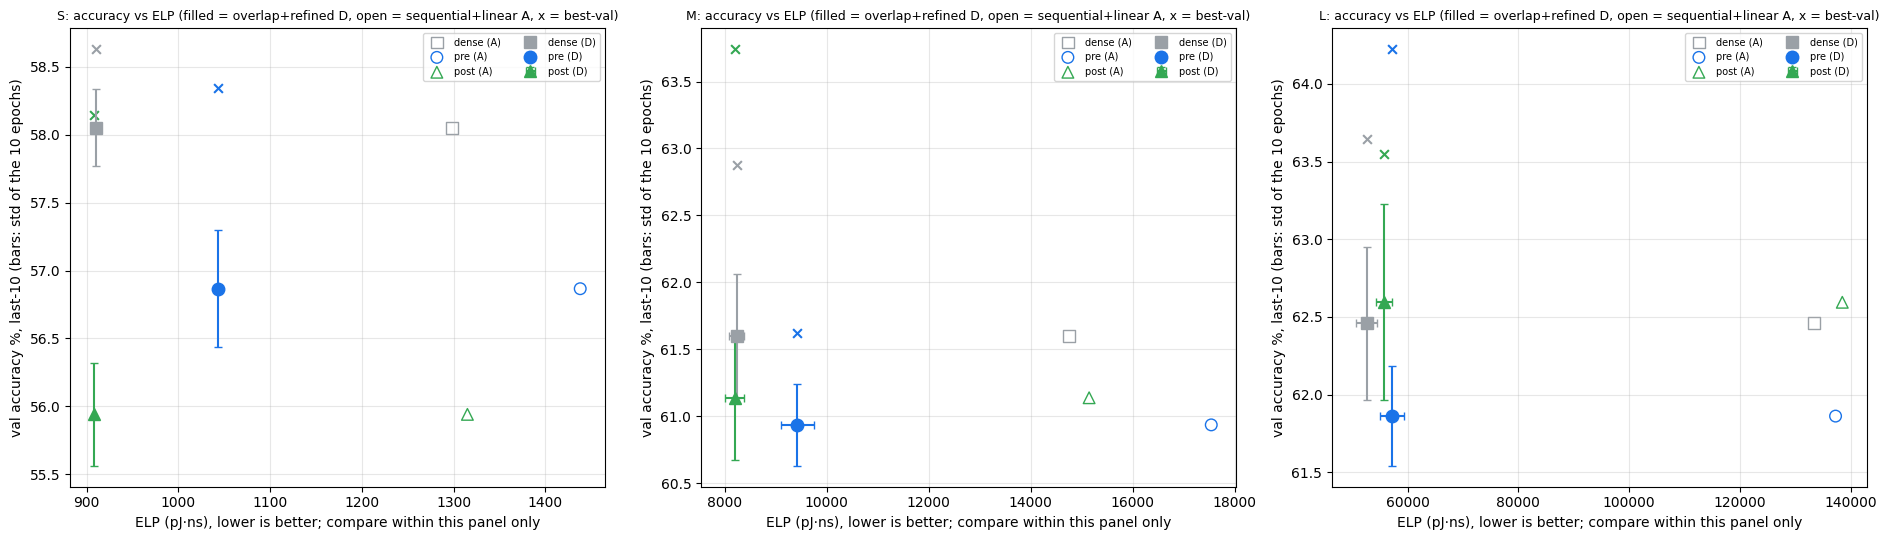


Saved: /content/drive/MyDrive/Prototype_10/reports/tradeoff_all_variants.csv
       /content/drive/MyDrive/Prototype_10/reports/relative_to_dense.csv
       /content/drive/MyDrive/Prototype_10/reports/pre_vs_post.csv
       /content/drive/MyDrive/Prototype_10/reports/final_report.md
       /content/drive/MyDrive/Prototype_10/figures/12_tradeoff.png

[6] MANIFEST AND REPRODUCIBILITY CHECK
  ✅ all 103 manifest entries exist on Drive
  ✅ every file under /content/drive/MyDrive/Prototype_10 is registered
  ✅ p10_model.py: md5 equals config.json
  ✅ p10_train.py: md5 equals config.json
  ✅ p10_post.py: md5 equals config.json
  ✅ p10_mapping.py: md5 equals config.json
  ✅ S_dense_s42: 7 files on Drive and in the manifest
  ✅ S_pre_s42: 7 files on Drive and in the manifest
  ✅ S_post_s42: 7 files on Drive and in the manifest
  ✅ M_dense_s42: 7 files on Drive and in the manifest
  ✅ M_pre_s42: 7 files on Drive and in the manifest
  ✅ M_post_s42: 7 files on Drive and in the manifest
  ✅ L_dens

In [36]:
# ===================== CELL 12: Final report: accuracy vs hardware cost, S-placement optimality check, limitations, manifest check =====================
import os, sys, json, math, time, pickle, hashlib, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------- Prelude (same pattern as Cells 5-11; no GPU needed) ----------
if 'config' not in globals():
    from google.colab import drive
    if not os.path.ismount('/content/drive'): drive.mount('/content/drive')
    config = json.load(open('/content/drive/MyDrive/Prototype_10/config/config.json'))
ROOT, PATHS, HW = config['ROOT'], config['PATHS'], config['HW']
TRAIN, FT = config['TRAIN'], config['FT']
MANIFEST_PATH, CONFIG_PATH = os.path.join(ROOT, 'manifest.json'), os.path.join(PATHS['config'], 'config.json'); HG_DIR = PATHS['hypergraph']
if 'register' not in globals():
    def register(path, desc):
        m = json.load(open(MANIFEST_PATH)) if os.path.exists(MANIFEST_PATH) else {}
        m[os.path.relpath(path, ROOT)] = desc
        with open(MANIFEST_PATH, 'w') as f: json.dump(m, f, indent=2)
if 'chk' not in globals():
    def chk(ok, msg):
        print(f"  {'✅' if ok else '❌'} {msg}"); assert ok, msg
    def soft(ok, msg):
        print(f"  {'✅' if ok else '⚠️'} {msg}"); return bool(ok)
if PATHS['code'] not in sys.path: sys.path.insert(0, PATHS['code'])
if 'variant_paths' not in globals():
    from p10_model import *
    from p10_train import *
from p10_mapping import linear_placement, evaluate_mapping, set_hw
set_hw(HW)
DIRS = {k: PATHS[k] for k in ('models', 'masks', 'results', 'spike_traces')}
REP_DIR = os.path.join(ROOT, 'reports'); os.makedirs(REP_DIR, exist_ok=True)

# ---------- CONTROL PANEL ----------
SIZES, MODES, SEEDS_RUN = ["S", "M", "L"], ["dense", "pre", "post"], list(config['SEEDS'])
NARRATIVE = ""      # paste the written conclusions here and re-run: they are inserted as section 7 of the report (empty = placeholder)
tu = config['STEPS']['total_updates']; EXP_UPD = dict(dense=tu['dense'], pre=tu['pre'], post=tu['post'])
EXP_EP = dict(dense=TRAIN['EPOCHS'], pre=TRAIN['EPOCHS'], post=FT['FT_EPOCHS'])

# ---------- 1) Inputs + stale guard ----------
print("[1] INPUTS (every variant must be valid; mapping tables must belong to the same models)")
valid, keys = {}, []
for seed in SEEDS_RUN:
    for size in SIZES:
        for mode in MODES:
            key = variant_key(size, mode, seed); keys.append(key)
            chk(is_done(DIRS, key), f"{key}: 7 files present")
            r = json.load(open(variant_paths(DIRS, key)['results']))
            chk(r['total_updates'] == EXP_UPD[mode] and r['epochs'] == EXP_EP[mode], f"{key}: total_updates {r['total_updates']} (need {EXP_UPD[mode]}), epochs {r['epochs']}")
            valid[key] = r
HG = pickle.load(open(os.path.join(HG_DIR, 'hypergraphs_val.pkl'), 'rb')); hg_info, hypergraphs = HG['info'], HG['hypergraphs']
dfa = pd.read_csv(os.path.join(HG_DIR, 'ablation_val.csv')); dfl = pd.read_csv(os.path.join(HG_DIR, 'mapping_metrics_val.csv'))
chk(set(dfa.variant) == set(keys) == set(hypergraphs) == set(dfl.variant), "ablation, mapping-metric tables and hypergraphs cover exactly these variants")
for _, a in dfa.iterrows():
    chk(abs(a.best_val - valid[a.variant]['best_acc']) < 1e-4 and abs(a.last10_mean - valid[a.variant]['last_k_mean']) < 1e-4, f"{a.variant}: ablation CSV accuracy equals results file") if a.variant == keys[0] else None
    assert abs(a.best_val - valid[a.variant]['best_acc']) < 1e-4 and abs(a.last10_mean - valid[a.variant]['last_k_mean']) < 1e-4, f"{a.variant}: ablation CSV is stale"
print("  ✅ every ablation-CSV accuracy equals its results file (not stale)")
def L(key, pipe, col): return float(dfl[(dfl.variant == key) & (dfl.pipeline == pipe)][col].iloc[0])

# ---------- 2) Table 1: accuracy and hardware cost for every variant ----------
rows = []
for key in keys:
    r, a, hi = valid[key], dfa[dfa.variant == key].iloc[0], hg_info[key]
    rows.append(dict(variant=key, size=hi['size'], mode=hi['mode'], params=r['n_params'], retained=r['retained_params'], synapses=r['fc_connections'],
                     best_val=r['best_acc'], last10=r['last_k_mean'], last10_std=r['last_k_std'], last_ep=r['last_epoch_acc'], silent=int(sum(r['silent_per_layer'])), events=hi['events_per_step'],
                     cores=int(a.cores), ELP_A=a.A, ELP_B=a.B, ELP_C=a.C, ELP_D=a.D, ELP_D_std=a.D_std, gain_D_vs_A=a.gain_D_vs_A, verdict=a.verdict_D_vs_B,
                     E_D=L(key, "D", "Total Energy (pJ) mean"), Lat_D=L(key, "D", "Average Latency (ns) mean"), Conn_D=L(key, "D", "Connectivity mean"),
                     over_APC=int(L(key, "D", "cores_over_C_APC")), over_SPC=int(L(key, "D", "cores_over_C_SPC")), max_ax=int(L(key, "D", "max_axons_core")), max_syn=int(L(key, "D", "max_synapses_core"))))
t1 = pd.DataFrame(rows)
print("\n" + "=" * 170)
print("[2] ACCURACY AND HARDWARE COST (val set; last-10 = mean of the last 10 epochs, for post of the last 10 FINE-TUNE epochs; ELP of D = overlap + Hilbert + refinement, mean over 5 placement seeds)")
print("=" * 170)
print(f"{'variant':<13}{'retained':>9}{'synapses':>9}{'best val':>9}{'last-10':>15}{'cores':>6}{'ELP A':>10}{'ELP D':>16}{'Energy D':>10}{'Lat D':>8}{'Conn D':>8}{'events/step':>12}{'>C_APC':>7}{'>C_SPC':>7}")
for x in rows:
    print(f"{x['variant']:<13}{x['retained']:>9,}{x['synapses']:>9,}{x['best_val']*100:>8.2f}%{x['last10']*100:>9.2f}±{x['last10_std']*100:<4.2f}{x['cores']:>6}{x['ELP_A']:>10.1f}{x['ELP_D']:>10.1f}±{x['ELP_D_std']:<5.1f}{x['E_D']:>10.1f}{x['Lat_D']:>8.2f}{x['Conn_D']:>8.1f}{x['events']:>12.1f}{x['over_APC']:>7}{x['over_SPC']:>7}")

# ---------- 3) Table 2: relative to the dense twin of the same size (accuracy deltas in points, cost deltas in %) ----------
print("\n" + "=" * 170)
print("[3] RELATIVE TO DENSE (same size). Accuracy flag: WITHIN when |Δlast10| <= larger last-10 std. Cost flag: WITHIN when |ΔELP_D| <= summed placement-seed std (does NOT include training variance)")
print("=" * 170)
print(f"{'variant':<13}{'Δbest pts':>10}{'Δlast10 pts':>12}{'acc flag':>10}{'ΔELP A %':>10}{'ΔELP D %':>10}{'cost flag':>11}{'ΔEnergy D %':>12}{'ΔLatency D %':>13}{'ΔConn D %':>10}")
t2 = []
for size in SIZES:
    d = t1[(t1['size'] == size) & (t1['mode'] == "dense")].iloc[0]
    for md in ("pre", "post"):
        s = t1[(t1['size'] == size) & (t1['mode'] == md)].iloc[0]
        dl = s.last10 - d.last10; sd = max(s.last10_std, d.last10_std); dE = s.ELP_D - d.ELP_D; nz = s.ELP_D_std + d.ELP_D_std
        t2.append(dict(variant=s.variant, size=size, mode=md, d_best=(s.best_val - d.best_val) * 100, d_last10=dl * 100, acc_flag="WITHIN" if abs(dl) <= sd else "outside",
                       d_ELP_A=(s.ELP_A / d.ELP_A - 1) * 100, d_ELP_D=(s.ELP_D / d.ELP_D - 1) * 100, cost_flag="WITHIN" if abs(dE) <= nz else "outside",
                       d_E_D=(s.E_D / d.E_D - 1) * 100, d_Lat_D=(s.Lat_D / d.Lat_D - 1) * 100, d_Conn_D=(s.Conn_D / d.Conn_D - 1) * 100))
        x = t2[-1]
        print(f"{x['variant']:<13}{x['d_best']:>+10.2f}{x['d_last10']:>+12.2f}{x['acc_flag']:>10}{x['d_ELP_A']:>+10.1f}{x['d_ELP_D']:>+10.1f}{x['cost_flag']:>11}{x['d_E_D']:>+12.1f}{x['d_Lat_D']:>+13.1f}{x['d_Conn_D']:>+10.1f}")
t2 = pd.DataFrame(t2)

# ---------- 4) Table 3: pre vs post (the research question), with the confounds stated ----------
print("\n" + "=" * 170)
print("[4] PRE vs POST (pre - post). Confounds: random fixed mask vs magnitude mask; post has 1600 extra updates (6400 vs 4800); ONE training seed, so mask type cannot be separated from training randomness")
print("=" * 170)
print(f"{'size':<6}{'Δbest pts':>10}{'Δlast10 pts':>12}{'acc flag':>10}{'ΔELP D %':>10}{'cost flag':>11}{'ΔEnergy D %':>12}{'ΔLatency D %':>13}{'Δevents %':>10}{'Δsilent':>9}")
t3 = []
for size in SIZES:
    p = t1[(t1['size'] == size) & (t1['mode'] == "pre")].iloc[0]; q = t1[(t1['size'] == size) & (t1['mode'] == "post")].iloc[0]
    dl = p.last10 - q.last10; sd = max(p.last10_std, q.last10_std); nz = p.ELP_D_std + q.ELP_D_std
    t3.append(dict(size=size, d_best=(p.best_val - q.best_val) * 100, d_last10=dl * 100, acc_flag="WITHIN" if abs(dl) <= sd else "outside", d_ELP_D=(p.ELP_D / q.ELP_D - 1) * 100,
                   cost_flag="WITHIN" if abs(p.ELP_D - q.ELP_D) <= nz else "outside", d_E_D=(p.E_D / q.E_D - 1) * 100, d_Lat_D=(p.Lat_D / q.Lat_D - 1) * 100,
                   d_events=(p.events / q.events - 1) * 100, d_silent=int(p.silent - q.silent)))
    x = t3[-1]; print(f"{size:<6}{x['d_best']:>+10.2f}{x['d_last10']:>+12.2f}{x['acc_flag']:>10}{x['d_ELP_D']:>+10.1f}{x['cost_flag']:>11}{x['d_E_D']:>+12.1f}{x['d_Lat_D']:>+13.1f}{x['d_events']:>+10.1f}{x['d_silent']:>+9}")
t3 = pd.DataFrame(t3)

# ---------- 5) Is the swap search optimal on the smallest graph? exhaustive check over all placements of the 4 cores of S ----------
print("\n[5] EXHAUSTIVE PLACEMENT CHECK for S (4 cores on a 2x2 grid: 24 placements)")
parts = pickle.load(open(os.path.join(HG_DIR, 'partitions_val.pkl'), 'rb'))['partitions']
cells = [(0, 0), (1, 0), (0, 1), (1, 1)]
for key in [k for k in keys if k.startswith("S_")]:
    nodes, h_edges, sf = hypergraphs[key]; out = {}
    for lab, pipe_ref, refd in (("sequential", "B", "ELP_B"), ("overlap", "D", "ELP_D")):
        pm = parts[key][lab]; K = len(set(pm.values())); assert K == 4
        elps = [evaluate_mapping(h_edges, sf, pm, dict(zip(range(K), [cells[i] for i in perm])))["Energy-Latency Product"] for perm in itertools.permutations(range(K))]
        ref = float(t1[t1.variant == key][refd].iloc[0]); out[lab] = (min(elps), max(elps), ref)
        soft(abs(ref - min(elps)) < 1e-3 * max(1.0, min(elps)), f"{key} {lab}: pipeline {pipe_ref} = {ref:.1f}; exhaustive best {min(elps):.1f}, worst {max(elps):.1f} -> the swap search {'reaches' if abs(ref - min(elps)) < 1e-3 * max(1.0, min(elps)) else 'MISSES'} the optimum")
print("  ℹ️ Only S is checked exhaustively (9 and 20 cores have 362,880 and 20!/44! placements); for M and L the swap search is a heuristic whose optimality is not verified.")

# ---------- 6) Plot: accuracy vs cost within each size ----------
mcol = {"dense": "#9aa0a6", "pre": "#1a73e8", "post": "#34a853"}; mk = {"dense": "s", "pre": "o", "post": "^"}
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for i, size in enumerate(SIZES):
    for _, x in t1[t1['size'] == size].iterrows():
        ax[i].errorbar(x.ELP_D, x.last10 * 100, xerr=x.ELP_D_std, yerr=x.last10_std * 100, fmt=mk[x['mode']], color=mcol[x['mode']], ms=9, capsize=3, label=f"{x['mode']} (D)")
        ax[i].scatter([x.ELP_A], [x.last10 * 100], marker=mk[x['mode']], facecolors='none', edgecolors=mcol[x['mode']], s=70, label=f"{x['mode']} (A)")
        ax[i].scatter([x.ELP_D], [x.best_val * 100], marker='x', color=mcol[x['mode']], s=40)
    ax[i].set_title(f"{size}: accuracy vs ELP (filled = overlap+refined D, open = sequential+linear A, x = best-val)", fontsize=9)
    ax[i].set_xlabel("ELP (pJ·ns), lower is better; compare within this panel only"); ax[i].set_ylabel("val accuracy %, last-10 (bars: std of the 10 epochs)"); ax[i].grid(alpha=0.3)
    h_, l_ = ax[i].get_legend_handles_labels(); u = dict(zip(l_, h_)); ax[i].legend(u.values(), u.keys(), fontsize=7, ncol=2)
plt.tight_layout(); fig_path = os.path.join(PATHS['figures'], '12_tradeoff.png'); plt.savefig(fig_path, dpi=200, bbox_inches='tight'); plt.show()

# ---------- 7) Files: tables + markdown report ----------
t1p, t2p, t3p = (os.path.join(REP_DIR, n) for n in ('tradeoff_all_variants.csv', 'relative_to_dense.csv', 'pre_vs_post.csv'))
t1.round(5).to_csv(t1p, index=False); t2.round(4).to_csv(t2p, index=False); t3.round(4).to_csv(t3p, index=False)
def md_table(df, fmt):
    cols = list(df.columns); out = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows(): out.append("| " + " | ".join((fmt.get(c, "{}").format(r[c]) if not isinstance(r[c], str) else r[c]) for c in cols) + " |")
    return "\n".join(out)
ADD_LIM = [
    "Analytical hardware estimates (rates x Manhattan hops, Loihi-small constants), not simulated hardware; ELP is not comparable across different networks, only within a model.",
    "C_APC (128 axons) and C_SPC (512 synapses) are audited, not enforced: every one of the nine models violates them (see the audit columns), so the mapping gains are communication-cost estimates for capacity-violating mappings.",
    "The cost model charges one packet per (source neuron, destination core) per spike; 50% fixed fan-in sparsity leaves 98.7-100% of these pairs, so synapse reduction does not lower the estimated routing cost; differences between modes follow the firing rates.",
    "B vs A (placement only) also changes the layout shape (Hilbert is more compact than the row-major scan for 9 and 20 cores).",
    "The explanation of 'C worse than A' (S models only) is not established: the conv-unit layout test was a near no-op (the partitioner already orders conv units by id), renumbering the overlap cores made M and L worse.",
    "Swap-search optimality was verified exhaustively only for S (4 cores); M and L use the same heuristic without an optimality proof.",
    "Pre vs post compares a random fixed mask with a magnitude mask, with one training seed and different update budgets (4800 vs 6400); training variance is not measured.",
    "The conv stage (depthwise conv + BatchNorm) is not in the hypergraph; BatchNorm/LayerNorm/bf16 mean the earlier integer-quantisation and Verilog work must be adapted in the hardware notebook (BatchNorm can be folded into the conv, LayerNorm has no simple integer equivalent, the old Verilog assumed 4-bit core ids / a 4x4 mesh, the old NoC replay assumed T = 2048 whereas this model uses T = 201)."]
rep = ["# Prototype 10: pre-sparse vs post-sparse spiking networks, with hypergraph partitioning and placement (EEG motor imagery, BCI IV-2a)", "",
       f"_Auto-generated by Cell 12 on {time.strftime('%Y-%m-%d %H:%M')} from the files in {ROOT}. All numbers come from saved results; narrative only in section 7._", "",
       "## 1. Setup", f"- Data: BCI IV-2a (MOABB BNCI2014_001), 4 classes, 22 channels x 1001 samples, Euclidean Alignment per subject; mixed sessions, one stratified 80/20 split (4147 train / 1037 val), **no test set** (val used for model selection, spike rates and reporting); LDA log-variance reference {config['DATA']['lda_val_acc']*100:.1f}%, chance 25%.",
       f"- Model: FastSNN (depthwise Conv1d + BatchNorm -> LIF, then MaskedLinear + LayerNorm + LIF per hidden layer, dense leaky-integrator readout), T = {HG['T']} time steps. Sizes S 22-44-64-4, M 22-88-128-64-4, L 22-176-256-128-64-4.",
       f"- Training: batch {TRAIN['BATCH_SIZE']} ({config['STEPS']['steps_per_epoch']} steps/epoch), {TRAIN['EPOCHS']} epochs = {tu['dense']} updates for dense and pre; post = dense checkpoint (best val) pruned, then {FT['FT_EPOCHS']} fine-tune epochs = {tu['post']} updates in total. Seeds: {SEEDS_RUN}.",
       "- Sparsity: 50% fixed fan-in on every FC layer from the conv units through the last hidden layer; depthwise conv and readout stay dense (whole-model sparsity 24.5% / 38.4% / 44.0% for S / M / L). Pre: random fixed mask trained from scratch. Post: top-|W| per output neuron of the trained dense model, then frozen-mask fine-tuning.",
       f"- Hardware model: C_NPC {HW['C_NPC']} neurons/core (enforced); C_APC {HW['C_APC']}, C_SPC {HW['C_SPC']} audited; E_R {HW['E_R']} / E_T {HW['E_T']} pJ, L_R {HW['L_R']} / L_T {HW['L_T']} ns; Manhattan distance; {HW['ITERATIONS']} swap iterations; placement seeds {HW['PLACEMENT_SEEDS']}.", "",
       "## 2. Accuracy and hardware cost (validation set)", "last-10 = mean of the last 10 epochs (post: of the last 10 fine-tune epochs); ELP_D = overlap partitioning + Hilbert + refinement, mean over placement seeds.", "",
       md_table(t1[['variant', 'retained', 'synapses', 'best_val', 'last10', 'last10_std', 'cores', 'ELP_A', 'ELP_D', 'ELP_D_std', 'E_D', 'Lat_D', 'over_APC', 'over_SPC']],
                dict(best_val="{:.4f}", last10="{:.4f}", last10_std="{:.4f}", ELP_A="{:.1f}", ELP_D="{:.1f}", ELP_D_std="{:.1f}", E_D="{:.1f}", Lat_D="{:.2f}")), "",
       "## 3. Relative to the dense model of the same size", "Accuracy deltas in points; cost deltas in %. WITHIN = inside the epoch-to-epoch (accuracy) or placement-seed (cost) noise; training variance is not included.", "",
       md_table(t2, {c: "{:+.2f}" for c in t2.columns if c.startswith("d_")}), "",
       "## 4. Pre-sparse vs post-sparse", "Confounds: random vs magnitude mask, 4800 vs 6400 updates, one training seed.", "", md_table(t3, {c: "{:+.2f}" for c in t3.columns if c.startswith("d_")}), "",
       "## 5. Mapping ablation (ELP; A = sequential + linear, B = sequential + Hilbert + refinement, C = overlap + linear, D = overlap + Hilbert + refinement)", "",
       md_table(dfa[['variant', 'cores', 'A', 'B', 'B_std', 'C', 'D', 'D_std', 'gain_D_vs_A', 'gain_B_vs_A', 'gain_C_vs_A', 'gain_D_vs_B', 'verdict_D_vs_B']],
                dict(A="{:.1f}", B="{:.1f}", B_std="{:.1f}", C="{:.1f}", D="{:.1f}", D_std="{:.1f}", gain_D_vs_A="{:+.1f}", gain_B_vs_A="{:+.1f}", gain_C_vs_A="{:+.1f}", gain_D_vs_B="{:+.1f}")), "",
       "## 6. Hardware audit (partition of pipeline D; cores over the limits)", "", md_table(t1[['variant', 'cores', 'max_ax', 'max_syn', 'over_APC', 'over_SPC']], {}), "",
       "## 7. Conclusions", NARRATIVE if NARRATIVE.strip() else "_(not yet written: paste the conclusions into NARRATIVE in Cell 12 and re-run)_", "",
       "## 8. Limitations"] + [f"- {s}" for s in config['LIMITATIONS']] + [f"- {s}" for s in ADD_LIM] + ["",
       "## 9. Hand-off to the hardware notebook (all saved, nothing needs retraining)",
       f"- Per variant (key = size_mode_seed): models/model_*_best.pt and *_last.pt (state_dict with mask buffers), models/results_*.json, masks/masks_*.npz (uint8, rows = output neurons), results/rates_*.npz, spike_traces/trace_*.npz (uint8, T x 32 windows x neurons, T = {HG['T']}), spike_traces/trace_windows.npz (32 fixed val windows).",
       "- hypergraph/hypergraphs_val.pkl (nodes, hyperedges, rates, node maps), partitions_val.pkl, mapping_audit.csv, mapping_metrics_val.csv, ablation_val.csv; code/ p10_model.py, p10_train.py, p10_post.py, p10_mapping.py (md5 in config.json).", ""]
rp = os.path.join(REP_DIR, 'final_report.md'); open(rp, 'w').write("\n".join(rep))
for pth, ds in ((t1p, "final table: accuracy + hardware cost for every variant"), (t2p, "sparse vs dense deltas (accuracy points, cost %) with noise flags"), (t3p, "pre vs post deltas with noise flags"),
                (rp, "auto-generated final report (tables, limitations, hand-off)"), (fig_path, "accuracy vs ELP within each network size")): register(pth, ds)
print(f"\nSaved: {t1p}\n       {t2p}\n       {t3p}\n       {rp}\n       {fig_path}")

# ---------- 8) Manifest and reproducibility check ----------
print("\n[6] MANIFEST AND REPRODUCIBILITY CHECK")
man = json.load(open(MANIFEST_PATH)); cfg = json.load(open(CONFIG_PATH))
missing = [p for p in man if not os.path.exists(os.path.join(ROOT, p))]
chk(not missing, f"all {len(man)} manifest entries exist on Drive" if not missing else f"manifest entries missing on Drive: {missing[:5]}")
on_disk = [os.path.relpath(os.path.join(d, f), ROOT) for d, _, fs in os.walk(ROOT) for f in fs if '__pycache__' not in d and '.ipynb_checkpoints' not in d]
unreg = sorted(p for p in on_disk if p not in man and p != 'manifest.json')
soft(not unreg, f"every file under {ROOT} is registered" if not unreg else f"{len(unreg)} files not in the manifest: {unreg[:8]}")
for nm, k_ in (("p10_model.py", "MODEL_CODE"), ("p10_train.py", "TRAIN_CODE"), ("p10_post.py", "POST_CODE"), ("p10_mapping.py", "MAPPING_CODE")):
    md5 = hashlib.md5(open(os.path.join(PATHS['code'], nm), 'rb').read()).hexdigest(); soft(md5 == cfg[k_]['md5'], f"{nm}: md5 equals config.json")
for key in keys:
    ps = variant_paths(DIRS, key); soft(is_done(DIRS, key) and all(os.path.relpath(p, ROOT) in man for p in ps.values()), f"{key}: 7 files on Drive and in the manifest")
for f_ in ("05_dense_training.png", "06_pre_sparse_training.png", "07_post_sparse_training.png", "08_all_variants.png", "09_hypergraph_extraction.png", "10_mapping_audit.png", "11_ablation.png", "12_tradeoff.png"):
    soft(os.path.exists(os.path.join(PATHS['figures'], f_)), f"figure {f_}")
soft(not any(s.startswith("BATCH_SIZE 4000") for s in cfg['LIMITATIONS']), "config.json LIMITATIONS no longer contain the stale batch-4000 text")
print(f"  ℹ️ 08_all_variants.png / all_variants_summary.csv include pre-sparse only if Cell 8 was re-run after pre was retrained: re-run Cell 8 once if its figure still lacks pre.")
print(f"\nReport: {rp}")
print("\nCell 12 complete.")